In [1]:
# ============================================
# REFINED LABOUR MARKET ANALYSIS
# ============================================

from pathlib import Path
import pandas as pd
import numpy as np

# Load refined dataset
INPUT_FILE = Path(
    r"C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\final_labour_market_refined.csv"
)

df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully.
Rows: 19207
Columns: 51

Column names:
['job_id', 'source_id', 'title', 'company', 'location', 'description', 'salary_min', 'salary_max', 'salary_avg', 'created', 'contract_type', 'contract_time', 'url', 'source', 'title_clean', 'description_clean', 'industry', 'industry_original', 'second_pass_industry', 'industry_before_second_pass', 'technical_skills', 'soft_skills', 'tools_and_technologies', 'certifications', 'licenses', 'education_required', 'experience_required', 'languages', 'status', 'technical_skills_normalized', 'soft_skills_normalized', 'tools_and_technologies_normalized', 'certifications_normalized', 'licenses_normalized', 'languages_normalized', 'technical_skills_parsed', 'soft_skills_parsed', 'tools_parsed', 'certifications_parsed', 'licenses_parsed', 'languages_parsed', 'experience_required_original', 'experience_clean', 'experience_years', 'experience_category_final', 'experience_outlier_flag', 'tools_and_technologies_parsed', 'technical_ski

In [2]:
# ============================================
# REFINED DATASET QUALITY CHECK
# ============================================

print("============================================")
print("REFINED DATASET QUALITY CHECK")
print("============================================")

# Basic dimensions
print("\nDataset shape:")
print("Rows:", len(df))
print("Columns:", len(df.columns))

# Job ID checks
print("\nJob ID checks:")
print("Missing job IDs:", df["job_id"].isna().sum())
print("Duplicate job IDs:", df["job_id"].duplicated().sum())

# Refined industry checks
print("\nRefined industry checks:")
print("Missing refined industries:",
      df["industry_refined"].isna().sum())

print(
    "Number of refined industries:",
    df["industry_refined"].nunique()
)

print("\nRefined industry distribution:")
industry_distribution = (
    df["industry_refined"]
    .value_counts()
    .to_frame("job_count")
)

industry_distribution["percentage"] = (
    industry_distribution["job_count"]
    / len(df) * 100
)

display(
    industry_distribution.round(2)
)

# Check Other
other_count = (
    df["industry_refined"] == "Other"
).sum()

print("\nOther jobs:", other_count)
print(
    "Other percentage:",
    round(other_count / len(df) * 100, 2),
    "%"
)

# Check key analysis columns
required_columns = [
    "title",
    "description_clean",
    "industry_refined",
    "technical_skills_parsed",
    "soft_skills_parsed",
    "tools_and_technologies_parsed",
    "experience_years",
    "experience_category_final",
    "salary_avg"
]

print("\nRequired analysis columns:")
missing_required = [
    col for col in required_columns
    if col not in df.columns
]

if missing_required:
    print("Missing:", missing_required)
else:
    print("All required analysis columns are present.")

print("\n============================================")
print("QUALITY CHECK COMPLETE")
print("============================================")

REFINED DATASET QUALITY CHECK

Dataset shape:
Rows: 19207
Columns: 51

Job ID checks:
Missing job IDs: 0
Duplicate job IDs: 0

Refined industry checks:
Missing refined industries: 0
Number of refined industries: 17

Refined industry distribution:


,job_count,percentage
industry_refined,,
Other,8496,44.23
Engineering,2583,13.45
Construction,1369,7.13
Manufacturing,1277,6.65
Finance and Banking,1117,5.82
Education,1012,5.27
Transport and Logistics,948,4.94
IT and Technology,644,3.35
Hospitality and Food Services,330,1.72



Other jobs: 8496
Other percentage: 44.23 %

Required analysis columns:
All required analysis columns are present.

QUALITY CHECK COMPLETE


In [3]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 1: OVERALL TECHNICAL SKILL DEMAND
# ============================================

# Explode technical skills into individual rows
technical_skill_data = (
    df[
        ["job_id", "technical_skills_parsed"]
    ]
    .explode("technical_skills_parsed")
    .dropna(subset=["technical_skills_parsed"])
    .copy()
)

# Clean skill names
technical_skill_data["technical_skill"] = (
    technical_skill_data["technical_skills_parsed"]
    .astype(str)
    .str.strip()
)

# Remove empty values
technical_skill_data = technical_skill_data[
    technical_skill_data["technical_skill"] != ""
].copy()

# Remove duplicate skill occurrences within the same job
technical_skill_data = (
    technical_skill_data
    .drop_duplicates(
        subset=["job_id", "technical_skill"]
    )
)

# Count jobs demanding each skill
technical_skill_demand = (
    technical_skill_data
    .groupby("technical_skill")["job_id"]
    .nunique()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
)

# Calculate percentage of all job postings
technical_skill_demand["demand_percentage"] = (
    technical_skill_demand["job_count"]
    / len(df)
    * 100
)

print("Total jobs:", len(df))

print(
    "Jobs with technical skills:",
    technical_skill_data["job_id"].nunique()
)

print(
    "Unique technical skills:",
    technical_skill_demand["technical_skill"].nunique()
)

print("\nTop 30 technical skills by job demand:")

display(
    technical_skill_demand
    .head(30)
    .round(3)
)

Total jobs: 19207
Jobs with technical skills: 19207
Unique technical skills: 1570

Top 30 technical skills by job demand:


,technical_skill,job_count,demand_percentage
1569,[],15614,81.293
603,['Electrical Installation'],578,3.009
800,['Forklift Operation'],120,0.625
1051,['Mechanical Design'],59,0.307
269,['CNC Milling'],57,0.297
1059,['Mechanical Engineering'],56,0.292
611,['Electrical Maintenance'],50,0.260
261,['CNC Machining'],50,0.260
1076,['Mechanical Maintenance'],47,0.245
762,['Financial Analysis'],45,0.234


In [4]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 1: OVERALL TECHNICAL SKILL DEMAND
# CORRECTED PARSING
# ============================================

import ast

def parse_skill_list(value):
    """
    Convert CSV-stored list strings back into Python lists.
    Empty lists and invalid values become [].
    """
    
    if isinstance(value, list):
        return value
    
    if pd.isna(value):
        return []
    
    if isinstance(value, str):
        value = value.strip()
        
        if value in ["", "[]", "nan", "None"]:
            return []
        
        try:
            parsed = ast.literal_eval(value)
            
            if isinstance(parsed, list):
                return parsed
            
            return []
        
        except (ValueError, SyntaxError):
            return []
    
    return []


# Create a clean parsed technical skill column
df["technical_skills_analysis_parsed"] = (
    df["technical_skills_parsed"]
    .apply(parse_skill_list)
)


# Explode technical skills into individual rows
technical_skill_data = (
    df[
        ["job_id", "technical_skills_analysis_parsed"]
    ]
    .explode("technical_skills_analysis_parsed")
    .dropna(subset=["technical_skills_analysis_parsed"])
    .copy()
)


# Clean skill names
technical_skill_data["technical_skill"] = (
    technical_skill_data["technical_skills_analysis_parsed"]
    .astype(str)
    .str.strip()
)


# Remove empty values
technical_skill_data = technical_skill_data[
    ~technical_skill_data["technical_skill"].isin(
        ["", "[]", "nan", "None"]
    )
].copy()


# Remove duplicate skill occurrences within the same job
technical_skill_data = (
    technical_skill_data
    .drop_duplicates(
        subset=["job_id", "technical_skill"]
    )
)


# Count jobs demanding each skill
technical_skill_demand = (
    technical_skill_data
    .groupby("technical_skill")["job_id"]
    .nunique()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
)


# Calculate percentage of all job postings
technical_skill_demand["demand_percentage"] = (
    technical_skill_demand["job_count"]
    / len(df)
    * 100
)


print("Total jobs:", len(df))

print(
    "Jobs with technical skills:",
    technical_skill_data["job_id"].nunique()
)

print(
    "Unique technical skills:",
    technical_skill_demand["technical_skill"].nunique()
)

print("\nTop 30 technical skills by job demand:")

display(
    technical_skill_demand
    .head(30)
    .round(3)
)

Total jobs: 19207
Jobs with technical skills: 3593
Unique technical skills: 2305

Top 30 technical skills by job demand:


,technical_skill,job_count,demand_percentage
779,Electrical Installation,628,3.270
932,Financial Analysis,156,0.812
981,Forklift Operation,120,0.625
781,Electrical Maintenance,81,0.422
1357,Mechanical Maintenance,80,0.417
935,Financial Modelling,73,0.380
1347,Mechanical Engineering,72,0.375
2257,Welding,66,0.344
364,CNC Milling,65,0.338
372,CNC Programming,64,0.333


In [5]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 2: SKILL DEMAND BY REFINED INDUSTRY
# ============================================

# Add refined industry to the technical skill records
technical_skill_industry = (
    df[
        ["job_id", "industry_refined",
         "technical_skills_analysis_parsed"]
    ]
    .explode("technical_skills_analysis_parsed")
    .dropna(subset=["technical_skills_analysis_parsed"])
    .copy()
)

# Clean skill names
technical_skill_industry["technical_skill"] = (
    technical_skill_industry[
        "technical_skills_analysis_parsed"
    ]
    .astype(str)
    .str.strip()
)

# Remove empty values
technical_skill_industry = technical_skill_industry[
    ~technical_skill_industry["technical_skill"].isin(
        ["", "[]", "nan", "None"]
    )
].copy()

# Avoid counting the same skill twice within one job
technical_skill_industry = (
    technical_skill_industry
    .drop_duplicates(
        subset=[
            "job_id",
            "industry_refined",
            "technical_skill"
        ]
    )
)

# Count jobs demanding each skill within each industry
industry_skill_demand = (
    technical_skill_industry
    .groupby(
        ["industry_refined", "technical_skill"]
    )["job_id"]
    .nunique()
    .reset_index(name="job_count")
)

# Number of jobs in each refined industry
industry_job_counts = (
    df["industry_refined"]
    .value_counts()
    .rename("industry_job_count")
    .reset_index()
)

industry_job_counts.columns = [
    "industry_refined",
    "industry_job_count"
]

# Merge industry totals
industry_skill_demand = industry_skill_demand.merge(
    industry_job_counts,
    on="industry_refined",
    how="left"
)

# Calculate percentage of jobs within each industry
industry_skill_demand["demand_percentage"] = (
    industry_skill_demand["job_count"]
    / industry_skill_demand["industry_job_count"]
    * 100
)

# Sort within each industry
industry_skill_demand = (
    industry_skill_demand
    .sort_values(
        ["industry_refined", "job_count"],
        ascending=[True, False]
    )
)

print(
    "Total industry-skill records:",
    len(industry_skill_demand)
)

print(
    "Industries represented:",
    industry_skill_demand["industry_refined"].nunique()
)

print(
    "Unique technical skills:",
    industry_skill_demand["technical_skill"].nunique()
)

print("\nTop 10 technical skills by industry:")

display(
    industry_skill_demand
    .groupby("industry_refined")
    .head(10)
    .round(3)
)

Total industry-skill records: 2682
Industries represented: 15
Unique technical skills: 2305

Top 10 technical skills by industry:


,industry_refined,technical_skill,job_count,industry_job_count,demand_percentage
22,Automotive,Vehicle Maintenance,9,255,3.529
7,Automotive,Light vehicle maintenance,4,255,1.569
4,Automotive,Diagnostic Skill,2,255,0.784
12,Automotive,Panel painting,2,255,0.784
16,Automotive,Repair,2,255,0.784
...,...,...,...,...,...
2677,Real Estate,Financial Modelling,1,42,2.381
2679,Transport and Logistics,Forklift Operation,90,948,9.494
2678,Transport and Logistics,Data Warehouse Architecture,1,948,0.105
2680,Transport and Logistics,HIAB,1,948,0.105


In [6]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 3: RELATIVE SKILL DEMAND
# ============================================

# Overall technical skill demand
overall_skill_demand = (
    technical_skill_demand[
        [
            "technical_skill",
            "job_count",
            "demand_percentage"
        ]
    ]
    .rename(
        columns={
            "job_count": "overall_job_count",
            "demand_percentage": "overall_demand_percentage"
        }
    )
)

# Merge overall demand with industry demand
relative_skill_demand = industry_skill_demand.merge(
    overall_skill_demand,
    left_on="technical_skill",
    right_on="technical_skill",
    how="left"
)

# Calculate relative demand ratio
relative_skill_demand["relative_demand_ratio"] = (
    relative_skill_demand["demand_percentage"]
    / relative_skill_demand["overall_demand_percentage"]
)

# Sort by relative demand
relative_skill_demand = (
    relative_skill_demand
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
)

print(
    "Total industry-skill records:",
    len(relative_skill_demand)
)

print(
    "Unique industries:",
    relative_skill_demand["industry_refined"].nunique()
)

print(
    "Unique technical skills:",
    relative_skill_demand["technical_skill"].nunique()
)

print("\nHighest relative technical skill demand:")

display(
    relative_skill_demand[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "overall_job_count",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .head(30)
    .round(3)
)

Total industry-skill records: 2682
Unique industries: 15
Unique technical skills: 2305

Highest relative technical skill demand:


,industry_refined,technical_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio
1569,Insurance,Claims Management,1,59,1.695,1,0.005,325.542
1566,Insurance,Actuarial,1,59,1.695,1,0.005,325.542
1567,Insurance,Actuarial Reserving,1,59,1.695,1,0.005,325.542
1568,Insurance,Capital Model,1,59,1.695,1,0.005,325.542
1724,Marketing and Advertising,Paid Social,1,148,0.676,1,0.005,129.777
1723,Marketing and Advertising,Keyword Research,1,148,0.676,1,0.005,129.777
1721,Marketing and Advertising,Ad Grouping,1,148,0.676,1,0.005,129.777
1571,Legal,Conveyancing,1,240,0.417,1,0.005,80.029
1570,Legal,Commercial Legal Work,1,240,0.417,1,0.005,80.029
24,Automotive,Vehicle Repair,1,255,0.392,1,0.005,75.322


In [7]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 4: FILTER LOW-FREQUENCY SKILL DEMAND
# ============================================

MIN_INDUSTRY_JOB_COUNT = 5

technical_skill_gap_candidates = (
    relative_skill_demand[
        relative_skill_demand["job_count"]
        >= MIN_INDUSTRY_JOB_COUNT
    ]
    .copy()
)

print(
    "Minimum industry job count:",
    MIN_INDUSTRY_JOB_COUNT
)

print(
    "Industry-skill records before filtering:",
    len(relative_skill_demand)
)

print(
    "Industry-skill records after filtering:",
    len(technical_skill_gap_candidates)
)

print(
    "Industries represented:",
    technical_skill_gap_candidates[
        "industry_refined"
    ].nunique()
)

print(
    "Unique technical skills:",
    technical_skill_gap_candidates[
        "technical_skill"
    ].nunique()
)

print("\nHighest relative-demand skills after filtering:")

display(
    technical_skill_gap_candidates[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "overall_job_count",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .head(30)
    .round(3)
)

Minimum industry job count: 5
Industry-skill records before filtering: 2682
Industry-skill records after filtering: 147
Industries represented: 8
Unique technical skills: 104

Highest relative-demand skills after filtering:


,industry_refined,technical_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio
0,Automotive,Vehicle Maintenance,9,255,3.529,11,0.057,61.627
1218,IT and Technology,Node.js,6,644,0.932,6,0.031,29.825
1211,IT and Technology,Software Engineering,10,644,1.553,10,0.052,29.825
1224,IT and Technology,Dynamics 365,5,644,0.776,5,0.026,29.825
1206,IT and Technology,C#,20,644,3.106,22,0.115,27.113
1212,IT and Technology,JavaScript,8,644,1.242,9,0.047,26.511
1207,IT and Technology,React,18,644,2.795,21,0.109,25.564
1221,IT and Technology,Data Science,5,644,0.776,6,0.031,24.854
1222,IT and Technology,DevOps,5,644,0.776,6,0.031,24.854
1225,IT and Technology,GCP,5,644,0.776,6,0.031,24.854


In [8]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 5: INDUSTRY SKILL SPECIALISATION SCORE
# ============================================

# Maximum values used for normalisation
max_demand = (
    technical_skill_gap_candidates[
        "demand_percentage"
    ].max()
)

max_relative_ratio = (
    technical_skill_gap_candidates[
        "relative_demand_ratio"
    ].max()
)

max_job_count = (
    technical_skill_gap_candidates[
        "job_count"
    ].max()
)


# Normalised demand score
technical_skill_gap_candidates["demand_score"] = (
    technical_skill_gap_candidates["demand_percentage"]
    / max_demand
)


# Normalised specialisation score
technical_skill_gap_candidates["specialisation_score"] = (
    technical_skill_gap_candidates["relative_demand_ratio"]
    / max_relative_ratio
)


# Normalised frequency score
technical_skill_gap_candidates["frequency_score"] = (
    technical_skill_gap_candidates["job_count"]
    / max_job_count
)


# Composite industry skill specialisation score
technical_skill_gap_candidates[
    "industry_skill_specialisation_score"
] = (
    0.40
    * technical_skill_gap_candidates["demand_score"]
    +
    0.35
    * technical_skill_gap_candidates["specialisation_score"]
    +
    0.25
    * technical_skill_gap_candidates["frequency_score"]
)


# Rank skills globally
technical_skill_gap_candidates[
    "specialisation_rank"
] = (
    technical_skill_gap_candidates[
        "industry_skill_specialisation_score"
    ]
    .rank(
        method="dense",
        ascending=False
    )
)


print(
    "Industry-skill records:",
    len(technical_skill_gap_candidates)
)

print(
    "Maximum demand percentage:",
    round(max_demand, 3)
)

print(
    "Maximum relative demand ratio:",
    round(max_relative_ratio, 3)
)

print(
    "Maximum job count:",
    max_job_count
)

print("\nTop 30 industry-specific technical skills:")

display(
    technical_skill_gap_candidates[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "demand_score",
            "specialisation_score",
            "frequency_score",
            "industry_skill_specialisation_score",
            "specialisation_rank"
        ]
    ]
    .sort_values(
        "industry_skill_specialisation_score",
        ascending=False
    )
    .head(30)
    .round(3)
)

Industry-skill records: 147
Maximum demand percentage: 13.44
Maximum relative demand ratio: 61.627
Maximum job count: 316

Top 30 industry-specific technical skills:


,industry_refined,technical_skill,job_count,industry_job_count,demand_percentage,relative_demand_ratio,demand_score,specialisation_score,frequency_score,industry_skill_specialisation_score,specialisation_rank
206,Engineering,Electrical Installation,316,2583,12.234,3.742,0.910,0.061,1.000,0.635,1.0
1043,Finance and Banking,Financial Analysis,147,1117,13.160,16.203,0.979,0.263,0.465,0.600,2.0
27,Construction,Electrical Installation,184,1369,13.440,4.111,1.000,0.067,0.582,0.569,3.0
0,Automotive,Vehicle Maintenance,9,255,3.529,61.627,0.263,1.000,0.028,0.462,4.0
2678,Transport and Logistics,Forklift Operation,90,948,9.494,15.195,0.706,0.247,0.285,0.440,5.0
1044,Finance and Banking,Financial Modelling,69,1117,6.177,16.253,0.460,0.264,0.218,0.331,6.0
1199,IT and Technology,CNC Programming,41,644,6.366,19.106,0.474,0.310,0.130,0.330,7.0
1201,IT and Technology,AI,30,644,4.658,24.182,0.347,0.392,0.095,0.300,8.0
1200,IT and Technology,Python,32,644,4.969,21.691,0.370,0.352,0.101,0.296,9.0
1206,IT and Technology,C#,20,644,3.106,27.113,0.231,0.440,0.063,0.262,10.0


In [9]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 6: HIGH-DEMAND SPECIALISED SKILLS
# ============================================

MIN_JOB_COUNT = 10
MIN_DEMAND_PERCENTAGE = 0.5
MIN_RELATIVE_RATIO = 2.0

high_demand_specialised_skills = (
    technical_skill_gap_candidates[
        (technical_skill_gap_candidates["job_count"] >= MIN_JOB_COUNT)
        &
        (technical_skill_gap_candidates["demand_percentage"] >= MIN_DEMAND_PERCENTAGE)
        &
        (technical_skill_gap_candidates["relative_demand_ratio"] >= MIN_RELATIVE_RATIO)
    ]
    .copy()
)

print("Minimum job count:", MIN_JOB_COUNT)
print("Minimum industry demand (%):", MIN_DEMAND_PERCENTAGE)
print("Minimum relative demand ratio:", MIN_RELATIVE_RATIO)

print(
    "\nHigh-demand specialised industry-skill records:",
    len(high_demand_specialised_skills)
)

print(
    "Industries represented:",
    high_demand_specialised_skills["industry_refined"].nunique()
)

print(
    "Unique technical skills:",
    high_demand_specialised_skills["technical_skill"].nunique()
)

display(
    high_demand_specialised_skills[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "overall_job_count",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_skill_specialisation_score"
        ]
    ]
    .sort_values(
        "industry_skill_specialisation_score",
        ascending=False
    )
    .round(3)
)

Minimum job count: 10
Minimum industry demand (%): 0.5
Minimum relative demand ratio: 2.0

High-demand specialised industry-skill records: 46
Industries represented: 5
Unique technical skills: 44


,industry_refined,technical_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio,industry_skill_specialisation_score
206,Engineering,Electrical Installation,316,2583,12.234,628,3.270,3.742,0.635
1043,Finance and Banking,Financial Analysis,147,1117,13.160,156,0.812,16.203,0.600
27,Construction,Electrical Installation,184,1369,13.440,628,3.270,4.111,0.569
2678,Transport and Logistics,Forklift Operation,90,948,9.494,120,0.625,15.195,0.440
1044,Finance and Banking,Financial Modelling,69,1117,6.177,73,0.380,16.253,0.331
1199,IT and Technology,CNC Programming,41,644,6.366,64,0.333,19.106,0.330
1201,IT and Technology,AI,30,644,4.658,37,0.193,24.182,0.300
1200,IT and Technology,Python,32,644,4.969,44,0.229,21.691,0.296
1206,IT and Technology,C#,20,644,3.106,22,0.115,27.113,0.262
1202,IT and Technology,Java,29,644,4.503,48,0.250,18.019,0.259


In [10]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 7: TECHNICAL SKILL × EXPERIENCE
# ============================================

# Keep only records with valid numeric experience
skill_experience = df[
    df["technical_skills_analysis_parsed"].apply(len) > 0
].copy()

skill_experience = skill_experience[
    skill_experience["experience_years"].notna()
].copy()

# Explode technical skills
skill_experience = skill_experience.explode(
    "technical_skills_analysis_parsed"
)

skill_experience = skill_experience.rename(
    columns={
        "technical_skills_analysis_parsed": "technical_skill"
    }
)

# Remove empty skill values
skill_experience = skill_experience[
    skill_experience["technical_skill"].notna()
    &
    (skill_experience["technical_skill"].astype(str).str.strip() != "")
].copy()

# Remove duplicate job-skill combinations
skill_experience = skill_experience.drop_duplicates(
    subset=["job_id", "technical_skill"]
)

print(
    "Technical skill-experience records:",
    len(skill_experience)
)

print(
    "Unique technical skills:",
    skill_experience["technical_skill"].nunique()
)

print(
    "Jobs with numeric experience and technical skills:",
    skill_experience["job_id"].nunique()
)

# Summarise experience by skill
technical_skill_experience_summary = (
    skill_experience
    .groupby("technical_skill")
    .agg(
        job_count=("job_id", "nunique"),
        median_experience_years=("experience_years", "median"),
        mean_experience_years=("experience_years", "mean"),
        min_experience_years=("experience_years", "min"),
        max_experience_years=("experience_years", "max")
    )
    .reset_index()
)

# Keep skills with at least 5 numeric-experience observations
technical_skill_experience_summary = (
    technical_skill_experience_summary[
        technical_skill_experience_summary["job_count"] >= 5
    ]
    .copy()
)

print(
    "\nSkills with at least 5 numeric-experience observations:",
    len(technical_skill_experience_summary)
)

display(
    technical_skill_experience_summary
    .sort_values(
        "median_experience_years",
        ascending=False
    )
    .head(30)
    .round(2)
)

Technical skill-experience records: 267
Unique technical skills: 142
Jobs with numeric experience and technical skills: 168



Skills with at least 5 numeric-experience observations: 7


,technical_skill,job_count,median_experience_years,mean_experience_years,min_experience_years,max_experience_years
49,Electrical Installation,35,2.0,1.97,1.0,2.0
50,Electrical Maintenance,5,2.0,2.00,2.0,2.0
60,Financial Analysis,29,2.0,1.97,1.0,2.0
61,Financial Modelling,14,2.0,2.00,2.0,2.0
65,Forklift Operation,9,2.0,1.89,1.0,2.0
88,Mechanical Maintenance,6,2.0,2.00,2.0,2.0
108,Project Management,7,2.0,2.00,2.0,2.0


In [11]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 8: EXPERIENCE-ADJUSTED SKILL PRESSURE
# ============================================

# Merge experience evidence with high-demand specialised skills
skill_pressure = high_demand_specialised_skills.merge(
    technical_skill_experience_summary[
        [
            "technical_skill",
            "job_count",
            "median_experience_years",
            "mean_experience_years"
        ]
    ],
    on="technical_skill",
    how="left",
    suffixes=("", "_experience")
)

# Rename experience observation count
skill_pressure = skill_pressure.rename(
    columns={
        "job_count_experience": "experience_observation_count"
    }
)

# Identify whether numeric experience evidence exists
skill_pressure["experience_evidence"] = (
    skill_pressure["experience_observation_count"]
    .notna()
    .map({
        True: "Available",
        False: "Not Available"
    })
)

# Create an experience score ONLY where numeric evidence exists
# Missing evidence remains NaN and is NOT treated as zero.
max_median_experience = (
    skill_pressure["median_experience_years"]
    .max()
)

skill_pressure["experience_score"] = (
    skill_pressure["median_experience_years"]
    / max_median_experience
)

# Combine market-demand score and experience evidence
# Experience receives 20% only where evidence is available.
skill_pressure["skill_pressure_score"] = (
    0.80
    * skill_pressure["industry_skill_specialisation_score"]
    +
    0.20
    * skill_pressure["experience_score"]
)

# Keep score unavailable when experience evidence is unavailable
skill_pressure.loc[
    skill_pressure["experience_evidence"] == "Not Available",
    "skill_pressure_score"
] = skill_pressure.loc[
    skill_pressure["experience_evidence"] == "Not Available",
    "industry_skill_specialisation_score"
]

# Rank
skill_pressure["skill_pressure_rank"] = (
    skill_pressure["skill_pressure_score"]
    .rank(
        method="dense",
        ascending=False
    )
)

print(
    "High-demand specialised skills:",
    len(skill_pressure)
)

print(
    "With numeric experience evidence:",
    (
        skill_pressure["experience_evidence"]
        == "Available"
    ).sum()
)

print(
    "Without numeric experience evidence:",
    (
        skill_pressure["experience_evidence"]
        == "Not Available"
    ).sum()
)

display(
    skill_pressure[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "industry_skill_specialisation_score",
            "experience_observation_count",
            "median_experience_years",
            "experience_evidence",
            "experience_score",
            "skill_pressure_score",
            "skill_pressure_rank"
        ]
    ]
    .sort_values(
        "skill_pressure_score",
        ascending=False
    )
    .round(3)
)

High-demand specialised skills: 46
With numeric experience evidence: 8
Without numeric experience evidence: 38


,industry_refined,technical_skill,job_count,demand_percentage,relative_demand_ratio,industry_skill_specialisation_score,experience_observation_count,median_experience_years,experience_evidence,experience_score,skill_pressure_score,skill_pressure_rank
44,Engineering,Electrical Installation,316,12.234,3.742,0.635,35.0,2.0,Available,1.0,0.708,1.0
12,Finance and Banking,Financial Analysis,147,13.160,16.203,0.600,29.0,2.0,Available,1.0,0.680,2.0
42,Construction,Electrical Installation,184,13.440,4.111,0.569,35.0,2.0,Available,1.0,0.655,3.0
15,Transport and Logistics,Forklift Operation,90,9.494,15.195,0.440,9.0,2.0,Available,1.0,0.552,4.0
11,Finance and Banking,Financial Modelling,69,6.177,16.253,0.331,14.0,2.0,Available,1.0,0.465,5.0
32,Engineering,Electrical Maintenance,75,2.904,6.885,0.185,5.0,2.0,Available,1.0,0.348,6.0
37,Engineering,Mechanical Maintenance,66,2.555,6.135,0.163,6.0,2.0,Available,1.0,0.330,7.0
7,IT and Technology,CNC Programming,41,6.366,19.106,0.330,NaN,NaN,Not Available,NaN,0.330,8.0
3,IT and Technology,AI,30,4.658,24.182,0.300,NaN,NaN,Not Available,NaN,0.300,9.0
5,IT and Technology,Python,32,4.969,21.691,0.296,NaN,NaN,Not Available,NaN,0.296,10.0


In [12]:
# ============================================
# STEP 8A: STANDARDISE MISSING EXPERIENCE LABELS
# ============================================

skill_pressure["experience_evidence"] = (
    skill_pressure["experience_evidence"]
    .fillna("Not Available")
)

display(
    skill_pressure[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "industry_skill_specialisation_score",
            "experience_observation_count",
            "median_experience_years",
            "experience_evidence",
            "experience_score",
            "skill_pressure_score",
            "skill_pressure_rank"
        ]
    ]
    .sort_values(
        "skill_pressure_score",
        ascending=False
    )
    .round(3)
)

,industry_refined,technical_skill,job_count,industry_skill_specialisation_score,experience_observation_count,median_experience_years,experience_evidence,experience_score,skill_pressure_score,skill_pressure_rank
44,Engineering,Electrical Installation,316,0.635,35.0,2.0,Available,1.0,0.708,1.0
12,Finance and Banking,Financial Analysis,147,0.600,29.0,2.0,Available,1.0,0.680,2.0
42,Construction,Electrical Installation,184,0.569,35.0,2.0,Available,1.0,0.655,3.0
15,Transport and Logistics,Forklift Operation,90,0.440,9.0,2.0,Available,1.0,0.552,4.0
11,Finance and Banking,Financial Modelling,69,0.331,14.0,2.0,Available,1.0,0.465,5.0
32,Engineering,Electrical Maintenance,75,0.185,5.0,2.0,Available,1.0,0.348,6.0
37,Engineering,Mechanical Maintenance,66,0.163,6.0,2.0,Available,1.0,0.330,7.0
7,IT and Technology,CNC Programming,41,0.330,NaN,NaN,Not Available,NaN,0.330,8.0
3,IT and Technology,AI,30,0.300,NaN,NaN,Not Available,NaN,0.300,9.0
5,IT and Technology,Python,32,0.296,NaN,NaN,Not Available,NaN,0.296,10.0


In [13]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 9: PRIORITY TECHNICAL SKILLS
# ============================================

# Select the top 5 skills within each industry
TOP_N_PER_INDUSTRY = 5

priority_technical_skills = (
    skill_pressure
    .sort_values(
        [
            "industry_refined",
            "skill_pressure_score"
        ],
        ascending=[True, False]
    )
    .groupby("industry_refined", group_keys=False)
    .head(TOP_N_PER_INDUSTRY)
    .copy()
)

# Re-rank the selected records globally
priority_technical_skills[
    "priority_rank"
] = (
    priority_technical_skills[
        "skill_pressure_score"
    ]
    .rank(
        method="dense",
        ascending=False
    )
)

print(
    "Priority technical skill records:",
    len(priority_technical_skills)
)

print(
    "Industries represented:",
    priority_technical_skills[
        "industry_refined"
    ].nunique()
)

print(
    "Unique priority technical skills:",
    priority_technical_skills[
        "technical_skill"
    ].nunique()
)

display(
    priority_technical_skills[
        [
            "industry_refined",
            "technical_skill",
            "job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "industry_skill_specialisation_score",
            "experience_observation_count",
            "median_experience_years",
            "experience_evidence",
            "skill_pressure_score",
            "priority_rank"
        ]
    ]
    .sort_values(
        "skill_pressure_score",
        ascending=False
    )
    .round(3)
)

Priority technical skill records: 21
Industries represented: 5
Unique priority technical skills: 20


,industry_refined,technical_skill,job_count,demand_percentage,relative_demand_ratio,industry_skill_specialisation_score,experience_observation_count,median_experience_years,experience_evidence,skill_pressure_score,priority_rank
44,Engineering,Electrical Installation,316,12.234,3.742,0.635,35.0,2.0,Available,0.708,1.0
12,Finance and Banking,Financial Analysis,147,13.160,16.203,0.600,29.0,2.0,Available,0.680,2.0
42,Construction,Electrical Installation,184,13.440,4.111,0.569,35.0,2.0,Available,0.655,3.0
15,Transport and Logistics,Forklift Operation,90,9.494,15.195,0.440,9.0,2.0,Available,0.552,4.0
11,Finance and Banking,Financial Modelling,69,6.177,16.253,0.331,14.0,2.0,Available,0.465,5.0
32,Engineering,Electrical Maintenance,75,2.904,6.885,0.185,5.0,2.0,Available,0.348,6.0
37,Engineering,Mechanical Maintenance,66,2.555,6.135,0.163,6.0,2.0,Available,0.330,7.0
7,IT and Technology,CNC Programming,41,6.366,19.106,0.330,NaN,NaN,Not Available,0.330,8.0
3,IT and Technology,AI,30,4.658,24.182,0.300,NaN,NaN,Not Available,0.300,9.0
5,IT and Technology,Python,32,4.969,21.691,0.296,NaN,NaN,Not Available,0.296,10.0


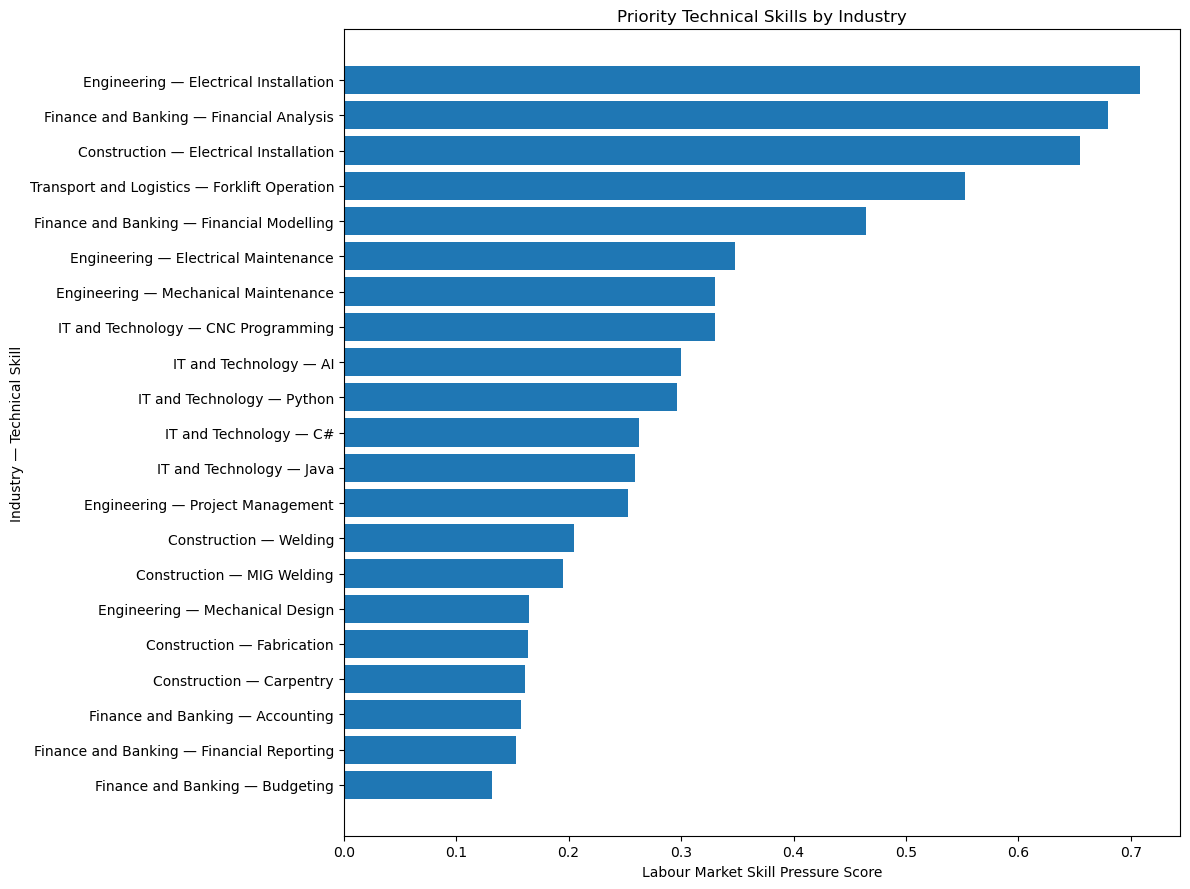

In [14]:
# ============================================
# TECHNICAL SKILLS INTELLIGENCE
# STEP 10: PRIORITY SKILL VISUALISATION
# ============================================

import matplotlib.pyplot as plt

plot_data = (
    priority_technical_skills
    .sort_values(
        "skill_pressure_score",
        ascending=True
    )
    .copy()
)

# Create readable industry-skill labels
plot_data["industry_skill_label"] = (
    plot_data["industry_refined"]
    + " — "
    + plot_data["technical_skill"]
)

plt.figure(figsize=(12, 9))

plt.barh(
    plot_data["industry_skill_label"],
    plot_data["skill_pressure_score"]
)

plt.xlabel("Labour Market Skill Pressure Score")
plt.ylabel("Industry — Technical Skill")
plt.title(
    "Priority Technical Skills by Industry"
)

plt.tight_layout()
plt.show()

In [15]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# PREPARATION: PARSE SOFT SKILLS
# ============================================

import ast

def parse_soft_skill_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    if isinstance(value, str):
        value = value.strip()

        if value in ["", "[]", "nan", "None"]:
            return []

        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, list):
                return parsed

            return []

        except (ValueError, SyntaxError):
            return []

    return []


df["soft_skills_analysis_parsed"] = (
    df["soft_skills_parsed"]
    .apply(parse_soft_skill_list)
)

print(
    "Soft skills parsed successfully."
)

print(
    "Jobs with at least one soft skill:",
    (
        df["soft_skills_analysis_parsed"]
        .apply(len) > 0
    ).sum()
)

print(
    "Total jobs:",
    len(df)
)

print(
    "Missing parsed soft-skill values:",
    df["soft_skills_analysis_parsed"].isna().sum()
)

Soft skills parsed successfully.
Jobs with at least one soft skill: 6424
Total jobs: 19207
Missing parsed soft-skill values: 0


In [16]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# STEP 11: OVERALL SOFT SKILL DEMAND
# ============================================

# Count jobs containing each soft skill
soft_skill_demand = (
    df[
        df["soft_skills_analysis_parsed"].apply(len) > 0
    ]
    .explode("soft_skills_analysis_parsed")
    .rename(
        columns={
            "soft_skills_analysis_parsed": "soft_skill"
        }
    )
)

# Remove empty values
soft_skill_demand = soft_skill_demand[
    soft_skill_demand["soft_skill"].notna()
    &
    (
        soft_skill_demand["soft_skill"]
        .astype(str)
        .str.strip()
        != ""
    )
].copy()

# Remove duplicate job-skill combinations
soft_skill_demand = soft_skill_demand.drop_duplicates(
    subset=["job_id", "soft_skill"]
)

# Count unique jobs per soft skill
overall_soft_skill_demand = (
    soft_skill_demand
    .groupby("soft_skill")
    .agg(
        job_count=("job_id", "nunique")
    )
    .reset_index()
)

# Calculate percentage of all jobs
total_jobs = len(df)

overall_soft_skill_demand["demand_percentage"] = (
    overall_soft_skill_demand["job_count"]
    / total_jobs
    * 100
)

# Sort by demand
overall_soft_skill_demand = (
    overall_soft_skill_demand
    .sort_values(
        "job_count",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Total jobs:", total_jobs)

print(
    "Jobs with at least one soft skill:",
    soft_skill_demand["job_id"].nunique()
)

print(
    "Unique soft skills:",
    overall_soft_skill_demand["soft_skill"].nunique()
)

print("\nTop 30 soft skills across the labour market:")

display(
    overall_soft_skill_demand
    .head(30)
    .round(3)
)

Total jobs: 19207
Jobs with at least one soft skill: 6424
Unique soft skills: 1530

Top 30 soft skills across the labour market:


,soft_skill,job_count,demand_percentage
0,Communication,2352,12.246
1,Problem Solving,2184,11.371
2,Attention to Detail,1944,10.121
3,Teamwork,1843,9.595
4,Leadership,1449,7.544
5,Customer Service,824,4.290
6,Time Management,396,2.062
7,Proactive,336,1.749
8,Reliable,170,0.885
9,Organised,151,0.786


In [17]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# STEP 12: SOFT SKILL DEMAND BY INDUSTRY
# ============================================

# Create industry-soft-skill dataset
soft_skill_industry = df[
    df["soft_skills_analysis_parsed"].apply(len) > 0
].explode(
    "soft_skills_analysis_parsed"
).rename(
    columns={
        "soft_skills_analysis_parsed": "soft_skill"
    }
)

# Remove missing / empty skills
soft_skill_industry = soft_skill_industry[
    soft_skill_industry["soft_skill"].notna()
    &
    (
        soft_skill_industry["soft_skill"]
        .astype(str)
        .str.strip()
        != ""
    )
].copy()

# Remove duplicate job-skill combinations
soft_skill_industry = soft_skill_industry.drop_duplicates(
    subset=[
        "job_id",
        "industry_refined",
        "soft_skill"
    ]
)

# Count jobs for each industry-soft-skill combination
industry_soft_skill_demand = (
    soft_skill_industry
    .groupby(
        [
            "industry_refined",
            "soft_skill"
        ]
    )
    .agg(
        job_count=("job_id", "nunique")
    )
    .reset_index()
)

# Total jobs in each industry
industry_job_counts = (
    df.groupby("industry_refined")
    .agg(
        industry_job_count=("job_id", "nunique")
    )
    .reset_index()
)

# Merge industry totals
industry_soft_skill_demand = (
    industry_soft_skill_demand
    .merge(
        industry_job_counts,
        on="industry_refined",
        how="left"
    )
)

# Calculate percentage of jobs within each industry
industry_soft_skill_demand["demand_percentage"] = (
    industry_soft_skill_demand["job_count"]
    / industry_soft_skill_demand["industry_job_count"]
    * 100
)

print(
    "Industry-soft-skill records:",
    len(industry_soft_skill_demand)
)

print(
    "Industries represented:",
    industry_soft_skill_demand[
        "industry_refined"
    ].nunique()
)

print(
    "Unique soft skills:",
    industry_soft_skill_demand[
        "soft_skill"
    ].nunique()
)

print("\nTop industry-specific soft skills:")

display(
    industry_soft_skill_demand[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage"
        ]
    ]
    .sort_values(
        "demand_percentage",
        ascending=False
    )
    .head(50)
    .round(3)
)

Industry-soft-skill records: 2333
Industries represented: 17
Unique soft skills: 1530

Top industry-specific soft skills:


,industry_refined,soft_skill,job_count,industry_job_count,demand_percentage
2200,Retail,Customer Service,99,192,51.562
84,Education,Communication,371,1012,36.660
2228,Retail,Teamwork,65,192,33.854
2222,Retail,Problem Solving,65,192,33.854
2196,Retail,Communication,59,192,30.729
730,Human Resources,Communication,70,232,30.172
597,Healthcare,Communication,78,263,29.658
2172,Real Estate,Communication,12,42,28.571
2184,Real Estate,Problem Solving,12,42,28.571
2208,Retail,Leadership,51,192,26.562


In [18]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# STEP 13: RELATIVE SOFT-SKILL DEMAND
# ============================================

# Add overall soft-skill demand information
relative_soft_skill_demand = (
    industry_soft_skill_demand
    .merge(
        overall_soft_skill_demand[
            [
                "soft_skill",
                "job_count",
                "demand_percentage"
            ]
        ],
        on="soft_skill",
        how="left",
        suffixes=(
            "",
            "_overall"
        )
    )
)

# Rename overall-market columns
relative_soft_skill_demand = (
    relative_soft_skill_demand
    .rename(
        columns={
            "job_count_overall": "overall_job_count",
            "demand_percentage_overall": "overall_demand_percentage"
        }
    )
)

# Calculate relative demand ratio
relative_soft_skill_demand[
    "relative_demand_ratio"
] = (
    relative_soft_skill_demand[
        "demand_percentage"
    ]
    /
    relative_soft_skill_demand[
        "overall_demand_percentage"
    ]
)

print(
    "Industry-soft-skill records:",
    len(relative_soft_skill_demand)
)

print(
    "Industries represented:",
    relative_soft_skill_demand[
        "industry_refined"
    ].nunique()
)

print(
    "Unique soft skills:",
    relative_soft_skill_demand[
        "soft_skill"
    ].nunique()
)

print(
    "\nHighest relative-demand soft skills:"
)

display(
    relative_soft_skill_demand[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "overall_job_count",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .head(30)
    .round(3)
)

Industry-soft-skill records: 2333


Industries represented: 17
Unique soft skills: 1530

Highest relative-demand soft skills:


,industry_refined,soft_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio
2185,Real Estate,Property Visit,1,42,2.381,1,0.005,457.310
2187,Real Estate,Strong Understanding,1,42,2.381,1,0.005,457.310
2169,Real Estate,Building Strong Tenant Relationships,1,42,2.381,1,0.005,457.310
2170,Real Estate,Check Diary Every Day,1,42,2.381,1,0.005,457.310
2175,Real Estate,Independently,1,42,2.381,1,0.005,457.310
2177,Real Estate,Move In Check Out,1,42,2.381,1,0.005,457.310
2179,Real Estate,Organise Necessary,1,42,2.381,1,0.005,457.310
2186,Real Estate,Staying Top of Compliance,1,42,2.381,1,0.005,457.310
844,Insurance,Natural resource underwriting,1,59,1.695,1,0.005,325.542
851,Insurance,Strategic Development,1,59,1.695,1,0.005,325.542


In [19]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# STEP 14: FILTER LOW-FREQUENCY SOFT SKILLS
# ============================================

MIN_INDUSTRY_JOB_COUNT = 5

soft_skill_gap_candidates = (
    relative_soft_skill_demand[
        relative_soft_skill_demand["job_count"]
        >= MIN_INDUSTRY_JOB_COUNT
    ]
    .copy()
)

print(
    "Minimum industry job count:",
    MIN_INDUSTRY_JOB_COUNT
)

print(
    "Industry-soft-skill records before filtering:",
    len(relative_soft_skill_demand)
)

print(
    "Industry-soft-skill records after filtering:",
    len(soft_skill_gap_candidates)
)

print(
    "Industries represented:",
    soft_skill_gap_candidates[
        "industry_refined"
    ].nunique()
)

print(
    "Unique soft skills:",
    soft_skill_gap_candidates[
        "soft_skill"
    ].nunique()
)

print(
    "\nHighest relative-demand soft skills after filtering:"
)

display(
    soft_skill_gap_candidates[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "overall_job_count",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .head(30)
    .round(3)
)

Minimum industry job count: 5
Industry-soft-skill records before filtering: 2333
Industry-soft-skill records after filtering: 304
Industries represented: 17
Unique soft skills: 137

Highest relative-demand soft skills after filtering:


,industry_refined,soft_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio
598,Healthcare,Companionship,6,263,2.281,6,0.031,73.030
599,Healthcare,Compassion,16,263,6.084,35,0.182,33.385
640,Healthcare,Support,5,263,1.901,18,0.094,20.286
109,Education,Encouragement,26,1012,2.569,26,0.135,18.979
132,Education,Genuine interest in helping others succeed,9,1012,0.889,9,0.047,18.979
165,Education,Listening Skill,10,1012,0.988,10,0.052,18.979
158,Education,Interest in helping students succeed,35,1012,3.458,35,0.182,18.979
131,Education,Genuine interest helping others succeed,14,1012,1.383,14,0.073,18.979
154,Education,Interest,6,1012,0.593,6,0.031,18.979
156,Education,Interest in Helping Students Succeed,12,1012,1.186,12,0.062,18.979


In [20]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# STEP 15: SOFT SKILL SPECIALISATION SCORE
# ============================================

# Maximum values for normalisation
max_soft_demand = (
    soft_skill_gap_candidates[
        "demand_percentage"
    ].max()
)

max_soft_relative_ratio = (
    soft_skill_gap_candidates[
        "relative_demand_ratio"
    ].max()
)

# Normalised industry demand score
soft_skill_gap_candidates[
    "demand_score"
] = (
    soft_skill_gap_candidates[
        "demand_percentage"
    ]
    / max_soft_demand
)

# Normalised specialisation score
soft_skill_gap_candidates[
    "specialisation_score"
] = (
    soft_skill_gap_candidates[
        "relative_demand_ratio"
    ]
    / max_soft_relative_ratio
)

# Composite soft-skill specialisation score
soft_skill_gap_candidates[
    "soft_skill_specialisation_score"
] = (
    0.55
    * soft_skill_gap_candidates[
        "demand_score"
    ]
    +
    0.45
    * soft_skill_gap_candidates[
        "specialisation_score"
    ]
)

# Rank industry-soft-skill combinations
soft_skill_gap_candidates[
    "specialisation_rank"
] = (
    soft_skill_gap_candidates[
        "soft_skill_specialisation_score"
    ]
    .rank(
        method="dense",
        ascending=False
    )
)

print(
    "Industry-soft-skill records:",
    len(soft_skill_gap_candidates)
)

print(
    "Maximum demand percentage:",
    round(
        max_soft_demand,
        3
    )
)

print(
    "Maximum relative demand ratio:",
    round(
        max_soft_relative_ratio,
        3
    )
)

print(
    "\nTop industry-specific soft skills:"
)

display(
    soft_skill_gap_candidates[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "demand_score",
            "specialisation_score",
            "soft_skill_specialisation_score",
            "specialisation_rank"
        ]
    ]
    .sort_values(
        "soft_skill_specialisation_score",
        ascending=False
    )
    .head(30)
    .round(3)
)

Industry-soft-skill records: 304
Maximum demand percentage: 51.562
Maximum relative demand ratio: 73.03

Top industry-specific soft skills:


,industry_refined,soft_skill,job_count,industry_job_count,demand_percentage,relative_demand_ratio,demand_score,specialisation_score,soft_skill_specialisation_score,specialisation_rank
2200,Retail,Customer Service,99,192,51.562,12.019,1.000,0.165,0.624,1.0
598,Healthcare,Companionship,6,263,2.281,73.030,0.044,1.000,0.474,2.0
84,Education,Communication,371,1012,36.660,2.994,0.711,0.041,0.409,3.0
2228,Retail,Teamwork,65,192,33.854,3.528,0.657,0.048,0.383,4.0
2222,Retail,Problem Solving,65,192,33.854,2.977,0.657,0.041,0.379,5.0
2196,Retail,Communication,59,192,30.729,2.509,0.596,0.034,0.343,6.0
730,Human Resources,Communication,70,232,30.172,2.464,0.585,0.034,0.337,7.0
597,Healthcare,Communication,78,263,29.658,2.422,0.575,0.033,0.331,8.0
2184,Real Estate,Problem Solving,12,42,28.571,2.513,0.554,0.034,0.320,9.0
2172,Real Estate,Communication,12,42,28.571,2.333,0.554,0.032,0.319,10.0


In [21]:
# ============================================
# SOFT SKILLS INTELLIGENCE
# STEP 16: HIGH-DEMAND SPECIALISED SOFT SKILLS
# ============================================

MIN_JOB_COUNT = 10
MIN_DEMAND_PERCENTAGE = 0.5
MIN_RELATIVE_RATIO = 2.0

high_demand_specialised_soft_skills = (
    soft_skill_gap_candidates[
        (soft_skill_gap_candidates["job_count"] >= MIN_JOB_COUNT)
        &
        (soft_skill_gap_candidates["demand_percentage"] >= MIN_DEMAND_PERCENTAGE)
        &
        (soft_skill_gap_candidates["relative_demand_ratio"] >= MIN_RELATIVE_RATIO)
    ]
    .copy()
)

print(
    "Minimum job count:",
    MIN_JOB_COUNT
)

print(
    "Minimum industry demand (%):",
    MIN_DEMAND_PERCENTAGE
)

print(
    "Minimum relative demand ratio:",
    MIN_RELATIVE_RATIO
)

print(
    "\nHigh-demand specialised soft-skill records:",
    len(high_demand_specialised_soft_skills)
)

print(
    "Industries represented:",
    high_demand_specialised_soft_skills[
        "industry_refined"
    ].nunique()
)

print(
    "Unique soft skills:",
    high_demand_specialised_soft_skills[
        "soft_skill"
    ].nunique()
)

display(
    high_demand_specialised_soft_skills[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "industry_job_count",
            "demand_percentage",
            "overall_job_count",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "soft_skill_specialisation_score"
        ]
    ]
    .sort_values(
        "soft_skill_specialisation_score",
        ascending=False
    )
    .round(3)
)

Minimum job count: 10
Minimum industry demand (%): 0.5
Minimum relative demand ratio: 2.0

High-demand specialised soft-skill records: 48
Industries represented: 12
Unique soft skills: 28


,industry_refined,soft_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio,soft_skill_specialisation_score
2200,Retail,Customer Service,99,192,51.562,824,4.290,12.019,0.624
84,Education,Communication,371,1012,36.660,2352,12.246,2.994,0.409
2228,Retail,Teamwork,65,192,33.854,1843,9.595,3.528,0.383
2222,Retail,Problem Solving,65,192,33.854,2184,11.371,2.977,0.379
2196,Retail,Communication,59,192,30.729,2352,12.246,2.509,0.343
730,Human Resources,Communication,70,232,30.172,2352,12.246,2.464,0.337
597,Healthcare,Communication,78,263,29.658,2352,12.246,2.422,0.331
2184,Real Estate,Problem Solving,12,42,28.571,2184,11.371,2.513,0.320
2172,Real Estate,Communication,12,42,28.571,2352,12.246,2.333,0.319
2208,Retail,Leadership,51,192,26.562,1449,7.544,3.521,0.305


In [22]:
# ============================================================
# STEP 17 — SOFT SKILLS × EXPERIENCE
# ============================================================

# Work only with jobs that have:
# 1. At least one analysed soft skill
# 2. A numeric experience requirement

soft_skill_experience_records = []

for _, row in df.iterrows():

    skills = row["soft_skills_analysis_parsed"]

    if not isinstance(skills, list) or len(skills) == 0:
        continue

    experience = row["experience_years"]

    if pd.isna(experience):
        continue

    for skill in skills:
        if skill is None:
            continue

        skill = str(skill).strip()

        if skill == "":
            continue

        soft_skill_experience_records.append({
            "job_id": row["job_id"],
            "industry_refined": row["industry_refined"],
            "soft_skill": skill,
            "experience_years": experience
        })


soft_skill_experience_df = pd.DataFrame(soft_skill_experience_records)

print("Soft-skill experience records:", len(soft_skill_experience_df))

if len(soft_skill_experience_df) > 0:

    # Remove implausibly high experience values
    # while retaining them separately for quality analysis
    soft_skill_experience_clean = soft_skill_experience_df[
        soft_skill_experience_df["experience_years"] <= 10
    ].copy()

    print(
        "Records after excluding experience >10 years:",
        len(soft_skill_experience_clean)
    )

    soft_skill_experience_summary = (
        soft_skill_experience_clean
        .groupby("soft_skill")
        .agg(
            observation_count=("experience_years", "count"),
            median_experience_years=("experience_years", "median"),
            mean_experience_years=("experience_years", "mean"),
            min_experience_years=("experience_years", "min"),
            max_experience_years=("experience_years", "max")
        )
        .reset_index()
        .sort_values(
            ["observation_count", "median_experience_years"],
            ascending=[False, True]
        )
    )

    print(
        "Unique soft skills with numeric experience:",
        soft_skill_experience_summary["soft_skill"].nunique()
    )

    display(soft_skill_experience_summary.head(30))

else:
    print("No soft-skill records with numeric experience were found.")

Soft-skill experience records: 2903
Records after excluding experience >10 years: 2901
Unique soft skills with numeric experience: 217


,soft_skill,observation_count,median_experience_years,mean_experience_years,min_experience_years,max_experience_years
148,Problem Solving,499,2.0,1.981964,0.083333,5.0
51,Communication,452,2.0,1.986910,0.083333,5.0
110,Leadership,447,2.0,1.985645,0.083333,3.0
207,Teamwork,418,2.0,1.981061,0.083333,5.0
13,Attention to Detail,396,2.0,1.978325,0.083333,3.0
65,Customer Service,144,2.0,1.979745,0.083333,2.0
210,Time Management,105,2.0,1.962698,0.083333,2.0
157,Project Management,48,2.0,1.979167,1.000000,2.0
144,Proactive,25,2.0,1.840000,1.000000,2.0
126,Organisation,16,2.0,1.817708,0.083333,2.0


In [23]:
# ============================================================
# STEP 18 — SOFT SKILLS EXPERIENCE-ADJUSTED PRESSURE
# ============================================================

# Use the high-demand specialised soft skills identified in Step 16
soft_experience_adjusted = high_demand_specialised_soft_skills.copy()

# Create experience lookup from Step 17
experience_lookup = soft_skill_experience_summary[
    [
        "soft_skill",
        "observation_count",
        "median_experience_years"
    ]
].copy()

# Merge experience evidence
soft_experience_adjusted = soft_experience_adjusted.merge(
    experience_lookup,
    on="soft_skill",
    how="left"
)

# Determine whether numeric experience evidence exists
soft_experience_adjusted["experience_evidence"] = (
    soft_experience_adjusted["observation_count"]
    .fillna(0)
    .gt(0)
    .map({
        True: "Available",
        False: "Not Available"
    })
)

# ------------------------------------------------------------
# Experience score
# ------------------------------------------------------------
# Lower median experience = lower experience barrier.
# Higher median experience = higher experience requirement.
#
# We normalise using the maximum observed median experience.
# This is used as supporting evidence, not as a standalone
# shortage measure.

max_experience = (
    soft_experience_adjusted["median_experience_years"]
    .dropna()
    .max()
)

if pd.isna(max_experience) or max_experience == 0:
    soft_experience_adjusted["experience_score"] = pd.NA
else:
    soft_experience_adjusted["experience_score"] = (
        soft_experience_adjusted["median_experience_years"]
        / max_experience
    )

# ------------------------------------------------------------
# Final experience-adjusted skill pressure score
# ------------------------------------------------------------

soft_experience_adjusted["skill_pressure_score"] = (
    soft_experience_adjusted["soft_skill_specialisation_score"]
)

available_mask = (
    soft_experience_adjusted["experience_evidence"] == "Available"
)

soft_experience_adjusted.loc[
    available_mask,
    "skill_pressure_score"
] = (
    0.80
    * soft_experience_adjusted.loc[
        available_mask,
        "soft_skill_specialisation_score"
    ]
    +
    0.20
    * soft_experience_adjusted.loc[
        available_mask,
        "experience_score"
    ]
)

# Sort by final pressure score
soft_experience_adjusted = soft_experience_adjusted.sort_values(
    "skill_pressure_score",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("High-demand specialised soft skills:",
      len(soft_experience_adjusted))

print(
    "With numeric experience evidence:",
    (soft_experience_adjusted["experience_evidence"] == "Available").sum()
)

print(
    "Without numeric experience evidence:",
    (soft_experience_adjusted["experience_evidence"] == "Not Available").sum()
)

print(
    "Unique industries:",
    soft_experience_adjusted["industry_refined"].nunique()
)

print(
    "Unique soft skills:",
    soft_experience_adjusted["soft_skill"].nunique()
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

display(
    soft_experience_adjusted[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "soft_skill_specialisation_score",
            "observation_count",
            "median_experience_years",
            "experience_evidence",
            "experience_score",
            "skill_pressure_score"
        ]
    ].head(30)
)

High-demand specialised soft skills: 48
With numeric experience evidence: 42
Without numeric experience evidence: 6
Unique industries: 12
Unique soft skills: 28


,industry_refined,soft_skill,job_count,demand_percentage,relative_demand_ratio,soft_skill_specialisation_score,observation_count,median_experience_years,experience_evidence,experience_score,skill_pressure_score
0,Retail,Customer Service,99,51.562500,12.018943,0.624059,144.0,2.0,Available,1.0,0.699247
1,Education,Communication,371,36.660079,2.993751,0.409488,452.0,2.0,Available,1.0,0.527590
2,Retail,Teamwork,65,33.854167,3.528144,0.382851,418.0,2.0,Available,1.0,0.506281
3,Retail,Problem Solving,65,33.854167,2.977276,0.379457,499.0,2.0,Available,1.0,0.503565
4,Retail,Communication,59,30.729167,2.509418,0.343240,452.0,2.0,Available,1.0,0.474592
5,Human Resources,Communication,70,30.172414,2.463952,0.337022,452.0,2.0,Available,1.0,0.469617
6,Healthcare,Communication,78,29.657795,2.421927,0.331273,452.0,2.0,Available,1.0,0.465019
7,Real Estate,Problem Solving,12,28.571429,2.512690,0.320245,499.0,2.0,Available,1.0,0.456196
8,Real Estate,Communication,12,28.571429,2.333212,0.319139,452.0,2.0,Available,1.0,0.455311
9,Retail,Leadership,51,26.562500,3.520952,0.305029,447.0,2.0,Available,1.0,0.444023


In [24]:
# ============================================================
# STEP 19 — TOP SOFT-SKILL PRIORITIES BY INDUSTRY
# ============================================================

# Rank soft skills within each industry
soft_experience_adjusted["industry_skill_rank"] = (
    soft_experience_adjusted
    .groupby("industry_refined")["skill_pressure_score"]
    .rank(
        method="first",
        ascending=False
    )
)

# Keep top 5 soft skills per industry
soft_skill_priority = (
    soft_experience_adjusted[
        soft_experience_adjusted["industry_skill_rank"] <= 5
    ]
    .copy()
    .sort_values(
        ["industry_refined", "skill_pressure_score"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("Top soft-skill priority records:", len(soft_skill_priority))
print(
    "Industries represented:",
    soft_skill_priority["industry_refined"].nunique()
)
print(
    "Unique priority soft skills:",
    soft_skill_priority["soft_skill"].nunique()
)

display(
    soft_skill_priority[
        [
            "industry_refined",
            "soft_skill",
            "job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "soft_skill_specialisation_score",
            "observation_count",
            "median_experience_years",
            "experience_evidence",
            "skill_pressure_score",
            "industry_skill_rank"
        ]
    ]
)

Top soft-skill priority records: 36
Industries represented: 12
Unique priority soft skills: 19


,industry_refined,soft_skill,job_count,demand_percentage,relative_demand_ratio,soft_skill_specialisation_score,observation_count,median_experience_years,experience_evidence,skill_pressure_score,industry_skill_rank
0,Automotive,Flexibility,14,5.490196,9.855159,0.119288,11.0,2.0,Available,0.295430,1.0
1,Construction,Reliability,10,0.730460,2.094022,0.020695,2.0,2.0,Available,0.216556,1.0
2,Education,Communication,371,36.660079,2.993751,0.409488,452.0,2.0,Available,0.527590,1.0
3,Education,Genuine interest helping others succeed,14,1.383399,18.979249,0.131703,1.0,2.0,Available,0.305362,2.0
4,Education,Enthusiasm,49,4.841897,8.942146,0.106747,1.0,2.0,Available,0.285397,3.0
5,Education,Passion,35,3.458498,7.635330,0.083938,3.0,2.0,Available,0.267151,4.0
6,Education,Commitment,11,1.086957,6.959058,0.054475,2.0,2.0,Available,0.243580,5.0
7,Finance and Banking,Detail Oriented,11,0.984781,3.002331,0.029004,1.0,2.0,Available,0.223203,1.0
8,Healthcare,Communication,78,29.657795,2.421927,0.331273,452.0,2.0,Available,0.465019,1.0
9,Healthcare,Teamwork,68,25.855513,2.694557,0.292396,418.0,2.0,Available,0.433916,2.0


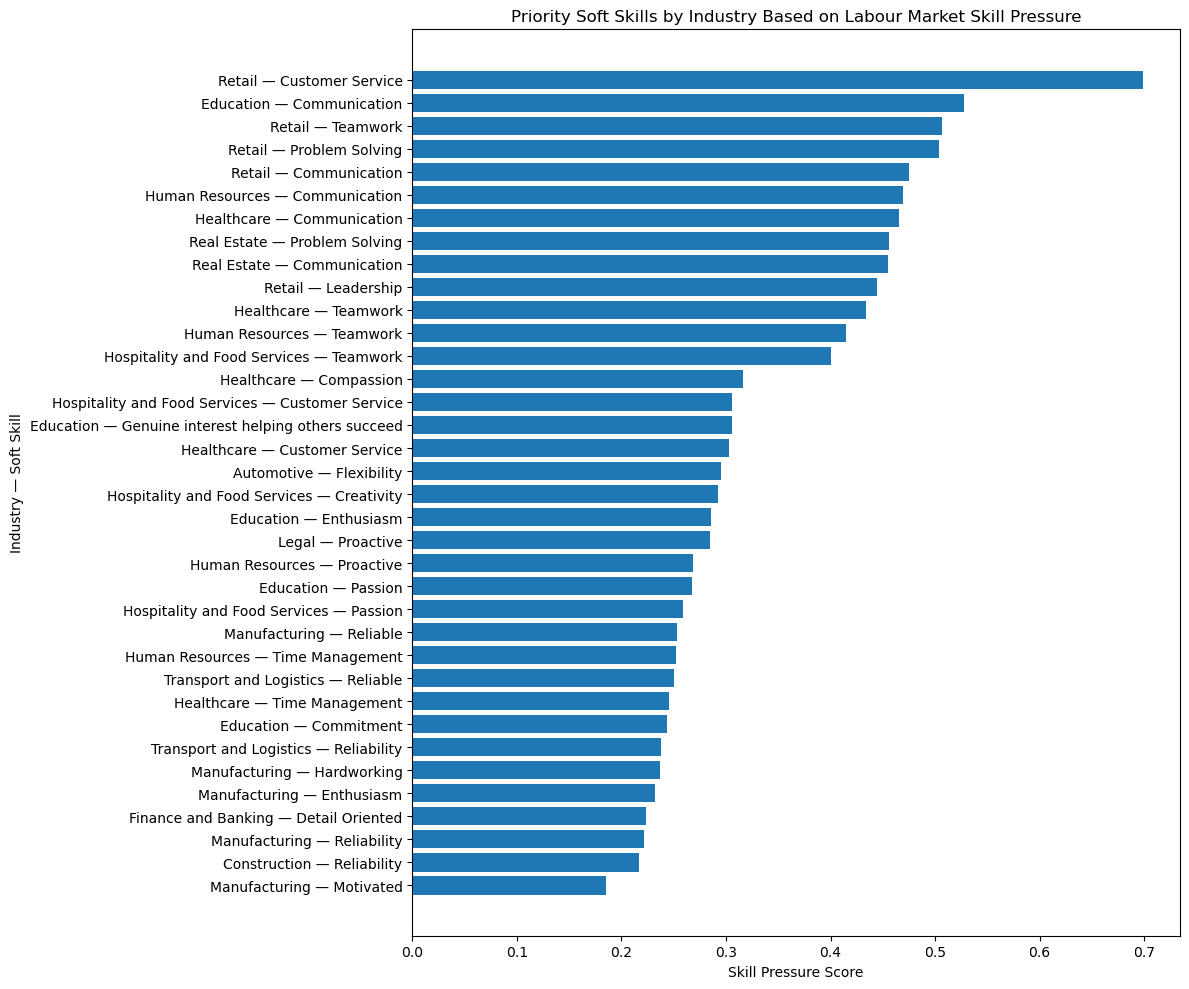

In [25]:
# ============================================================
# STEP 20 — SOFT-SKILL PRIORITY VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = soft_skill_priority.copy()

# Create readable labels
plot_df["industry_skill"] = (
    plot_df["industry_refined"]
    + " — "
    + plot_df["soft_skill"]
)

# Sort for horizontal bar chart
plot_df = plot_df.sort_values(
    "skill_pressure_score",
    ascending=True
)

plt.figure(figsize=(12, 10))

plt.barh(
    plot_df["industry_skill"],
    plot_df["skill_pressure_score"]
)

plt.xlabel("Skill Pressure Score")
plt.ylabel("Industry — Soft Skill")
plt.title(
    "Priority Soft Skills by Industry Based on Labour Market Skill Pressure"
)

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# STEP 21 — INDUSTRY JOB DEMAND DISTRIBUTION
# ============================================================

industry_demand = (
    df["industry_refined"]
    .value_counts()
    .reset_index()
)

industry_demand.columns = [
    "industry_refined",
    "job_count"
]

# Calculate percentage of total jobs
industry_demand["demand_percentage"] = (
    industry_demand["job_count"]
    / len(df)
    * 100
)

# Sort by demand
industry_demand = industry_demand.sort_values(
    "job_count",
    ascending=False
).reset_index(drop=True)

print("Total jobs:", len(df))
print("Number of industries:", len(industry_demand))

display(industry_demand)

Total jobs: 19207
Number of industries: 17


,industry_refined,job_count,demand_percentage
0,Other,8496,44.233873
1,Engineering,2583,13.448222
2,Construction,1369,7.127610
3,Manufacturing,1277,6.648618
4,Finance and Banking,1117,5.815588
5,Education,1012,5.268912
6,Transport and Logistics,948,4.935701
7,IT and Technology,644,3.352944
8,Hospitality and Food Services,330,1.718124
9,Healthcare,263,1.369292


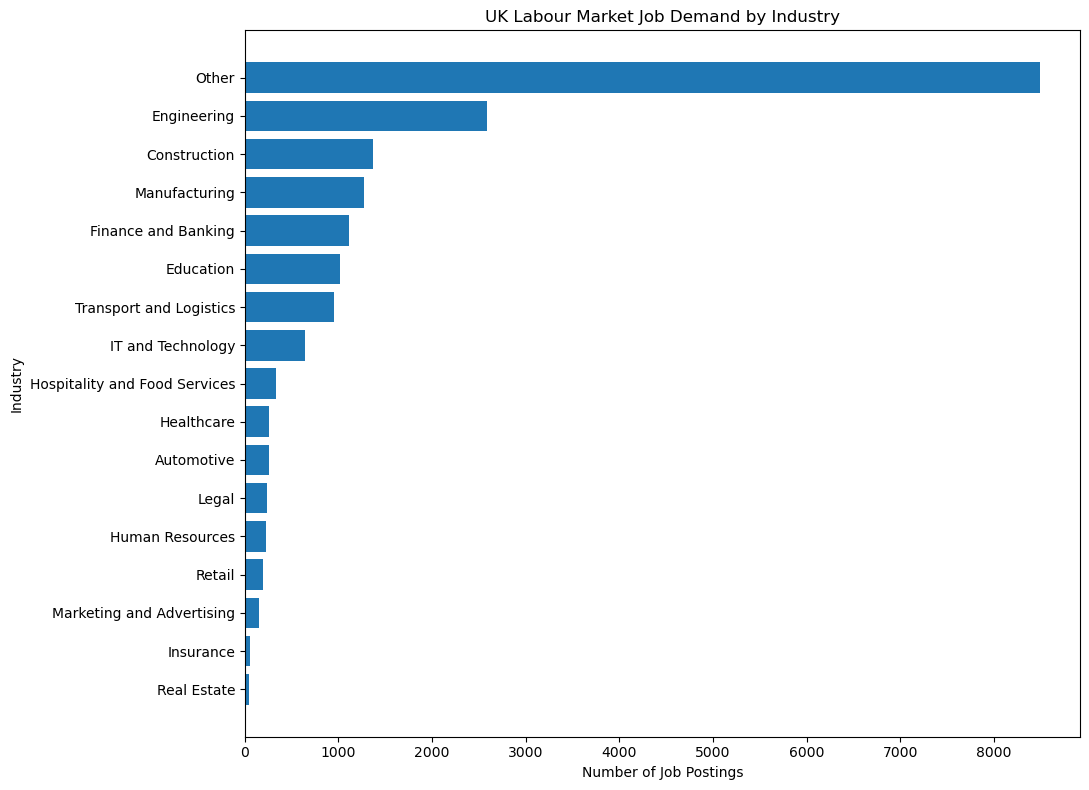

In [27]:
# ============================================================
# STEP 22 — INDUSTRY JOB DEMAND VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = industry_demand.sort_values(
    "job_count",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["job_count"]
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Industry")
plt.title("UK Labour Market Job Demand by Industry")

plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# STEP 23 — SALARY AVAILABILITY BY INDUSTRY
# ============================================================

salary_availability = (
    df.groupby("industry_refined")
    .agg(
        total_jobs=("job_id", "count"),
        salary_records=("salary_avg", lambda x: x.notna().sum())
    )
    .reset_index()
)

# Calculate missing salary records
salary_availability["missing_salary_records"] = (
    salary_availability["total_jobs"]
    - salary_availability["salary_records"]
)

# Calculate salary coverage percentage
salary_availability["salary_coverage_percentage"] = (
    salary_availability["salary_records"]
    / salary_availability["total_jobs"]
    * 100
)

# Sort by salary coverage
salary_availability = salary_availability.sort_values(
    "salary_coverage_percentage",
    ascending=False
).reset_index(drop=True)

print("Total jobs:", len(df))
print(
    "Jobs with salary information:",
    df["salary_avg"].notna().sum()
)
print(
    "Jobs without salary information:",
    df["salary_avg"].isna().sum()
)

display(salary_availability)

Total jobs: 19207
Jobs with salary information: 16775
Jobs without salary information: 2432


,industry_refined,total_jobs,salary_records,missing_salary_records,salary_coverage_percentage
0,Automotive,255,251,4,98.431373
1,Education,1012,996,16,98.418972
2,Construction,1369,1313,56,95.909423
3,Healthcare,263,251,12,95.437262
4,Transport and Logistics,948,871,77,91.877637
5,Real Estate,42,38,4,90.476190
6,Hospitality and Food Services,330,298,32,90.303030
7,Manufacturing,1277,1127,150,88.253720
8,Finance and Banking,1117,972,145,87.018800
9,Other,8496,7314,1182,86.087571


In [29]:
# ============================================================
# STEP 24 — SALARY STATISTICS BY INDUSTRY
# ============================================================

salary_by_industry = (
    df.groupby("industry_refined")["salary_avg"]
    .agg(
        salary_records="count",
        mean_salary="mean",
        median_salary="median",
        min_salary="min",
        max_salary="max"
    )
    .reset_index()
)

# Add salary coverage from Step 23
salary_by_industry = salary_by_industry.merge(
    salary_availability[
        [
            "industry_refined",
            "total_jobs",
            "salary_coverage_percentage"
        ]
    ],
    on="industry_refined",
    how="left"
)

# Reorder columns
salary_by_industry = salary_by_industry[
    [
        "industry_refined",
        "total_jobs",
        "salary_records",
        "salary_coverage_percentage",
        "mean_salary",
        "median_salary",
        "min_salary",
        "max_salary"
    ]
]

# Sort by median salary
salary_by_industry = salary_by_industry.sort_values(
    "median_salary",
    ascending=False
).reset_index(drop=True)

print("Industries analysed:", len(salary_by_industry))

display(salary_by_industry)

Industries analysed: 17


,industry_refined,total_jobs,salary_records,salary_coverage_percentage,mean_salary,median_salary,min_salary,max_salary
0,Finance and Banking,1117,972,87.018800,47286.517495,47500.000,0.000,435000.0
1,Legal,240,201,83.750000,50694.617488,46000.000,13.355,187500.0
2,Engineering,2583,2159,83.584979,46220.799481,45000.000,0.000,245000.0
3,Construction,1369,1313,95.909423,42954.939600,45000.000,0.000,107500.0
4,Insurance,59,33,55.932203,47832.846061,45000.000,25.000,167500.0
5,Real Estate,42,38,90.476190,52803.593158,42500.000,24.660,225000.0
6,IT and Technology,644,522,81.055901,48506.969138,41900.500,0.000,425000.0
7,Education,1012,996,98.418972,31842.021928,37869.140,13.125,78000.0
8,Marketing and Advertising,148,116,78.378378,38716.225431,35625.000,0.000,137500.0
9,Other,8496,7314,86.087571,37439.164026,35000.000,0.000,500000.0


In [30]:
# ============================================================
# STEP 25 — SALARY DATA DIAGNOSTICS
# ============================================================

salary_data = df["salary_avg"].dropna()

salary_diagnostics = {
    "Total salary records": len(salary_data),
    "Zero salary values": (salary_data == 0).sum(),
    "Negative salary values": (salary_data < 0).sum(),
    "Salary values below £100": (salary_data < 100).sum(),
    "Salary values below £1,000": (salary_data < 1000).sum(),
    "Salary values above £100,000": (salary_data > 100000).sum(),
    "Salary values above £200,000": (salary_data > 200000).sum(),
    "Salary values above £300,000": (salary_data > 300000).sum(),
    "Salary values above £400,000": (salary_data > 400000).sum(),
    "Maximum salary": salary_data.max(),
    "Minimum salary": salary_data.min()
}

for key, value in salary_diagnostics.items():
    print(f"{key}: {value}")

Total salary records: 16775
Zero salary values: 107
Negative salary values: 0
Salary values below £100: 2443
Salary values below £1,000: 2842
Salary values above £100,000: 226
Salary values above £200,000: 25
Salary values above £300,000: 10
Salary values above £400,000: 3
Maximum salary: 500000.0
Minimum salary: 0.0


Positive salary records: 16668


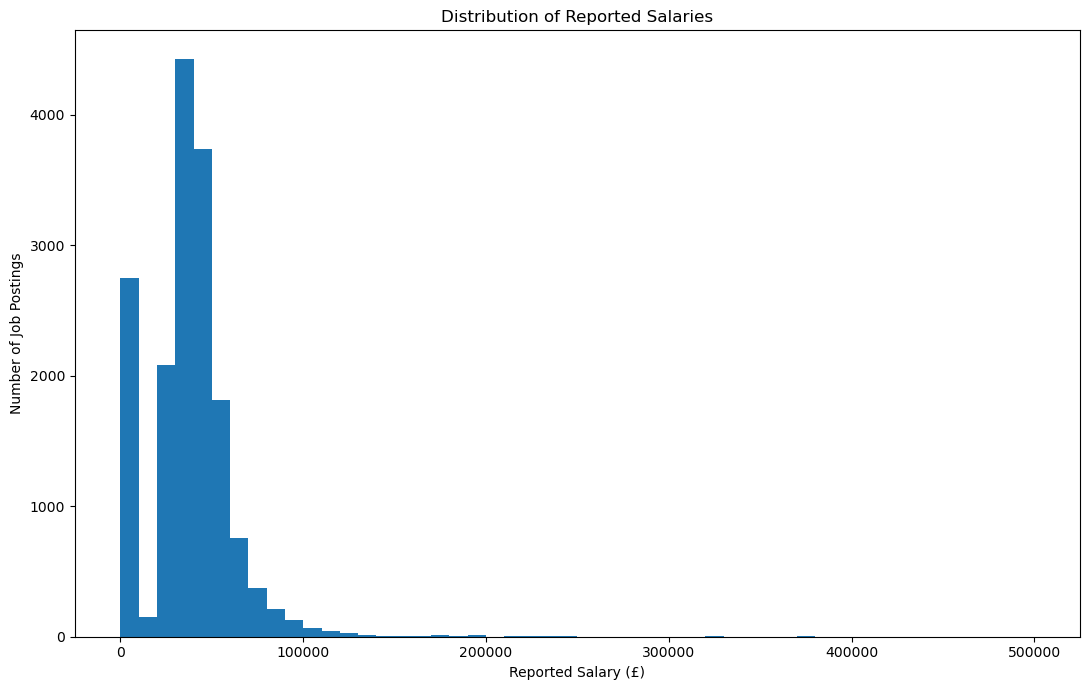

In [31]:
# ============================================================
# STEP 26 — SALARY DISTRIBUTION VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

# Use positive salary values for visualisation only
salary_positive = df.loc[
    df["salary_avg"] > 0,
    "salary_avg"
].dropna()

print("Positive salary records:", len(salary_positive))

plt.figure(figsize=(11, 7))

plt.hist(
    salary_positive,
    bins=50
)

plt.xlabel("Reported Salary (£)")
plt.ylabel("Number of Job Postings")
plt.title("Distribution of Reported Salaries")

plt.tight_layout()
plt.show()

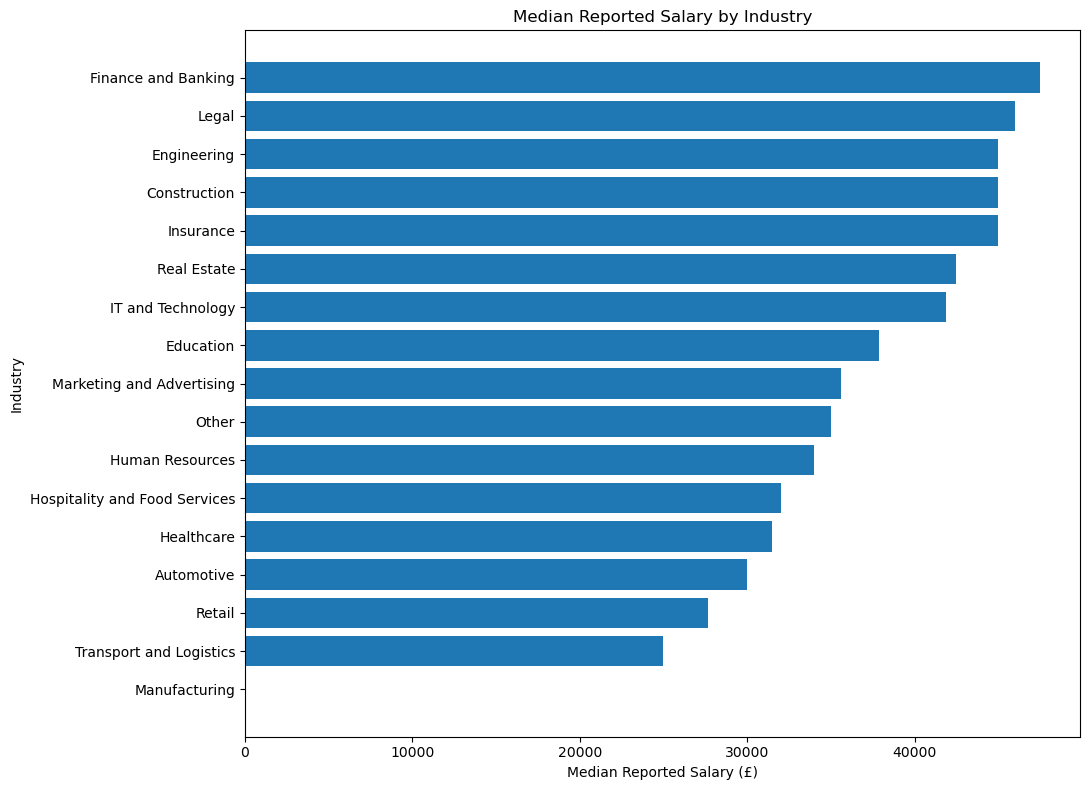

In [32]:
# ============================================================
# STEP 27 — MEDIAN SALARY BY INDUSTRY
# ============================================================

import matplotlib.pyplot as plt

plot_df = salary_by_industry.sort_values(
    "median_salary",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["median_salary"]
)

plt.xlabel("Median Reported Salary (£)")
plt.ylabel("Industry")
plt.title("Median Reported Salary by Industry")

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# STEP 28 — MEAN VS MEDIAN SALARY BY INDUSTRY
# ============================================================

salary_comparison = salary_by_industry[
    [
        "industry_refined",
        "salary_records",
        "salary_coverage_percentage",
        "mean_salary",
        "median_salary"
    ]
].copy()

# Calculate difference between mean and median
salary_comparison["mean_median_difference"] = (
    salary_comparison["mean_salary"]
    - salary_comparison["median_salary"]
)

# Calculate percentage difference relative to median
salary_comparison["mean_median_difference_percentage"] = (
    salary_comparison["mean_median_difference"]
    / salary_comparison["median_salary"]
    * 100
)

# Sort by absolute difference
salary_comparison = salary_comparison.sort_values(
    "mean_median_difference",
    ascending=False
).reset_index(drop=True)

print("Industries compared:", len(salary_comparison))

display(salary_comparison)

Industries compared: 17


,industry_refined,salary_records,salary_coverage_percentage,mean_salary,median_salary,mean_median_difference,mean_median_difference_percentage
0,Manufacturing,1127,88.253720,19826.154117,33.500,19792.654117,59082.549603
1,Real Estate,38,90.476190,52803.593158,42500.000,10303.593158,24.243749
2,IT and Technology,522,81.055901,48506.969138,41900.500,6606.469138,15.767041
3,Healthcare,251,95.437262,36596.309203,31500.000,5096.309203,16.178759
4,Legal,201,83.750000,50694.617488,46000.000,4694.617488,10.205690
5,Automotive,251,98.431373,33881.595279,30000.000,3881.595279,12.938651
6,Marketing and Advertising,116,78.378378,38716.225431,35625.000,3091.225431,8.677124
7,Insurance,33,55.932203,47832.846061,45000.000,2832.846061,6.295213
8,Other,7314,86.087571,37439.164026,35000.000,2439.164026,6.969040
9,Human Resources,196,84.482759,35356.930638,34000.000,1356.930638,3.990972


In [34]:
# ============================================================
# STEP 29 — LOW SALARY ANOMALY ANALYSIS BY INDUSTRY
# ============================================================

low_salary_analysis = (
    df.groupby("industry_refined")
    .agg(
        total_jobs=("job_id", "count"),
        salary_records=("salary_avg", lambda x: x.notna().sum()),
        zero_salary=("salary_avg", lambda x: (x == 0).sum()),
        below_100=("salary_avg", lambda x: ((x > 0) & (x < 100)).sum()),
        below_1000=("salary_avg", lambda x: ((x > 0) & (x < 1000)).sum())
    )
    .reset_index()
)

# Calculate percentages among salary records
low_salary_analysis["zero_salary_percentage"] = (
    low_salary_analysis["zero_salary"]
    / low_salary_analysis["salary_records"]
    * 100
)

low_salary_analysis["below_100_percentage"] = (
    low_salary_analysis["below_100"]
    / low_salary_analysis["salary_records"]
    * 100
)

low_salary_analysis["below_1000_percentage"] = (
    low_salary_analysis["below_1000"]
    / low_salary_analysis["salary_records"]
    * 100
)

# Sort by number of salaries below £100
low_salary_analysis = low_salary_analysis.sort_values(
    "below_100",
    ascending=False
).reset_index(drop=True)

print("Industries analysed:", len(low_salary_analysis))

display(low_salary_analysis)

Industries analysed: 17


,industry_refined,total_jobs,salary_records,zero_salary,below_100,below_1000,zero_salary_percentage,below_100_percentage,below_1000_percentage
0,Other,8496,7314,54,917,1049,0.738310,12.537599,14.342357
1,Manufacturing,1277,1127,3,571,573,0.266193,50.665484,50.842946
2,Transport and Logistics,948,871,5,393,394,0.574053,45.120551,45.235362
3,Construction,1369,1313,7,94,98,0.533130,7.159177,7.463823
4,Engineering,2583,2159,13,94,124,0.602131,4.353868,5.743400
5,Education,1012,996,0,75,197,0.000000,7.530120,19.779116
6,Finance and Banking,1117,972,3,47,94,0.308642,4.835391,9.670782
7,Retail,192,117,0,36,36,0.000000,30.769231,30.769231
8,IT and Technology,644,522,15,29,82,2.873563,5.555556,15.708812
9,Healthcare,263,251,0,24,25,0.000000,9.561753,9.960159


In [35]:
# ============================================================
# STEP 30 — SALARY SENSITIVITY ANALYSIS
# ============================================================

# Keep the original salary data unchanged.
# Compare industry medians under different analytical filters.

salary_sensitivity = []

thresholds = {
    "All reported values": 0,
    "Positive values only": 0,
    "Exclude values below £100": 100,
    "Exclude values below £1,000": 1000
}

for label, threshold in thresholds.items():

    if label == "All reported values":
        temp_df = df[df["salary_avg"].notna()].copy()

    elif label == "Positive values only":
        temp_df = df[
            df["salary_avg"].notna()
            & (df["salary_avg"] > 0)
        ].copy()

    else:
        temp_df = df[
            df["salary_avg"].notna()
            & (df["salary_avg"] >= threshold)
        ].copy()

    median_by_industry = (
        temp_df
        .groupby("industry_refined")["salary_avg"]
        .median()
        .reset_index()
    )

    median_by_industry["salary_filter"] = label

    salary_sensitivity.append(median_by_industry)


salary_sensitivity_df = pd.concat(
    salary_sensitivity,
    ignore_index=True
)

# Pivot for easy comparison
salary_sensitivity_table = (
    salary_sensitivity_df
    .pivot(
        index="industry_refined",
        columns="salary_filter",
        values="salary_avg"
    )
    .reset_index()
)

# Put industries in the same order as the original analysis
industry_order = industry_demand["industry_refined"].tolist()

salary_sensitivity_table["industry_order"] = (
    salary_sensitivity_table["industry_refined"]
    .map(
        {
            industry: i
            for i, industry in enumerate(industry_order)
        }
    )
)

salary_sensitivity_table = (
    salary_sensitivity_table
    .sort_values("industry_order")
    .drop(columns="industry_order")
    .reset_index(drop=True)
)

print("Salary sensitivity analysis completed.")
print(
    "Industries compared:",
    salary_sensitivity_table["industry_refined"].nunique()
)

display(salary_sensitivity_table)

Salary sensitivity analysis completed.
Industries compared: 17


salary_filter,industry_refined,All reported values,"Exclude values below £1,000",Exclude values below £100,Positive values only
0,Other,35000.000,37500.000,37467.710,35000.000
1,Engineering,45000.000,46500.000,46134.415,45046.500
2,Construction,45000.000,45582.695,45548.780,45000.250
3,Manufacturing,33.500,37500.000,37500.000,33.500
4,Finance and Banking,47500.000,50000.000,47500.000,47500.000
5,Education,37869.140,40367.980,38921.740,37869.140
6,Transport and Logistics,25000.000,35000.000,35000.000,25468.500
7,IT and Technology,41900.500,49500.000,44393.590,42500.000
8,Hospitality and Food Services,32032.075,33280.000,33280.000,32032.075
9,Healthcare,31500.000,35000.000,35000.000,31500.000


In [36]:
# ============================================================
# STEP 31 — ADJUSTED MEDIAN SALARY BY INDUSTRY
# ============================================================

# Use salary values >= £100 for analytical comparison.
# Original df remains unchanged.

salary_adjusted = df[
    df["salary_avg"].notna()
    & (df["salary_avg"] >= 100)
].copy()

adjusted_salary_by_industry = (
    salary_adjusted
    .groupby("industry_refined")["salary_avg"]
    .agg(
        salary_records="count",
        median_salary="median",
        mean_salary="mean",
        min_salary="min",
        max_salary="max"
    )
    .reset_index()
)

# Add original salary coverage
adjusted_salary_by_industry = adjusted_salary_by_industry.merge(
    salary_availability[
        [
            "industry_refined",
            "total_jobs",
            "salary_coverage_percentage"
        ]
    ],
    on="industry_refined",
    how="left"
)

# Calculate percentage of original salary records retained
adjusted_salary_by_industry["adjusted_salary_coverage"] = (
    adjusted_salary_by_industry["salary_records"]
    / adjusted_salary_by_industry["total_jobs"]
    * 100
)

# Sort by adjusted median salary
adjusted_salary_by_industry = (
    adjusted_salary_by_industry
    .sort_values(
        "median_salary",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Salary records after analytical threshold:",
    len(salary_adjusted)
)

print(
    "Threshold applied: salary >= £100"
)

print(
    "Industries analysed:",
    len(adjusted_salary_by_industry)
)

display(adjusted_salary_by_industry)

Salary records after analytical threshold: 14332
Threshold applied: salary >= £100
Industries analysed: 17


,industry_refined,salary_records,median_salary,mean_salary,min_salary,max_salary,total_jobs,salary_coverage_percentage,adjusted_salary_coverage
0,Finance and Banking,922,47500.000,49849.817636,160.00,435000.0,1117,87.018800,82.542525
1,Engineering,2052,46134.415,48629.445136,190.00,245000.0,2583,83.584979,79.442509
2,Legal,198,46064.625,51462.311919,23000.00,187500.0,240,83.750000,82.500000
3,Construction,1212,45548.780,46532.928998,255.00,107500.0,1369,95.909423,88.531775
4,Insurance,32,45000.000,49326.841250,862.00,167500.0,59,55.932203,54.237288
5,IT and Technology,478,44393.590,52970.657531,200.00,425000.0,644,81.055901,74.223602
6,Real Estate,37,42500.000,54230.050811,21999.91,225000.0,42,90.476190,88.095238
7,Education,921,38921.740,34431.537606,100.00,78000.0,1012,98.418972,91.007905
8,Manufacturing,553,37500.000,40389.645859,350.00,153000.0,1277,88.253720,43.304620
9,Other,6343,37467.710,43167.837984,100.00,500000.0,8496,86.087571,74.658663


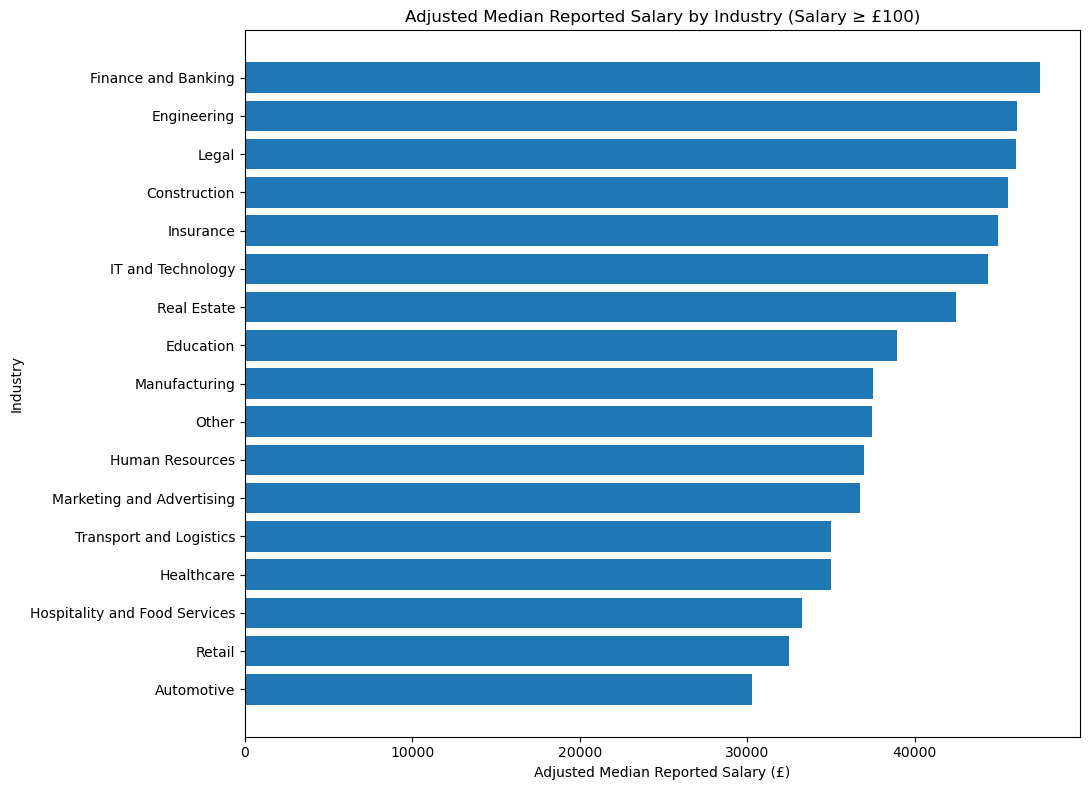

In [37]:
# ============================================================
# STEP 32 — ADJUSTED MEDIAN SALARY VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = adjusted_salary_by_industry.sort_values(
    "median_salary",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["median_salary"]
)

plt.xlabel("Adjusted Median Reported Salary (£)")
plt.ylabel("Industry")
plt.title(
    "Adjusted Median Reported Salary by Industry (Salary ≥ £100)"
)

plt.tight_layout()
plt.show()

In [38]:
# ============================================================
# STEP 33 — SALARY DISTRIBUTION BY INDUSTRY (IQR)
# ============================================================

salary_distribution_by_industry = (
    salary_adjusted
    .groupby("industry_refined")["salary_avg"]
    .agg(
        salary_records="count",
        q1_salary=lambda x: x.quantile(0.25),
        median_salary="median",
        q3_salary=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

# Calculate interquartile range
salary_distribution_by_industry["iqr"] = (
    salary_distribution_by_industry["q3_salary"]
    - salary_distribution_by_industry["q1_salary"]
)

# Calculate lower and upper bounds for reference
salary_distribution_by_industry["lower_iqr_bound"] = (
    salary_distribution_by_industry["q1_salary"]
    - 1.5 * salary_distribution_by_industry["iqr"]
)

salary_distribution_by_industry["upper_iqr_bound"] = (
    salary_distribution_by_industry["q3_salary"]
    + 1.5 * salary_distribution_by_industry["iqr"]
)

# Sort by median salary
salary_distribution_by_industry = (
    salary_distribution_by_industry
    .sort_values(
        "median_salary",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Industries analysed:",
    len(salary_distribution_by_industry)
)

display(salary_distribution_by_industry)

Industries analysed: 17


,industry_refined,salary_records,q1_salary,median_salary,q3_salary,iqr,lower_iqr_bound,upper_iqr_bound
0,Finance and Banking,922,35000.0000,47500.000,60000.000,25000.0000,-2500.00000,97500.00000
1,Engineering,2052,40000.0000,46134.415,53087.025,13087.0250,20369.46250,72717.56250
2,Legal,198,31988.6975,46064.625,64821.780,32833.0825,-17260.92625,114071.40375
3,Construction,1212,41721.0025,45548.780,50000.000,8278.9975,29302.50625,62418.49625
4,Insurance,32,31289.6700,45000.000,65625.000,34335.3300,-20213.32500,117127.99500
5,IT and Technology,478,37500.0000,44393.590,65000.000,27500.0000,-3750.00000,106250.00000
6,Real Estate,37,29000.0000,42500.000,52531.000,23531.0000,-6296.50000,87827.50000
7,Education,921,29002.9000,38921.740,44177.360,15174.4600,6241.21000,66939.05000
8,Manufacturing,553,31000.0000,37500.000,47500.000,16500.0000,6250.00000,72250.00000
9,Other,6343,31500.0000,37467.710,50000.000,18500.0000,3750.00000,77750.00000


C:\Users\Visakh H S\AppData\Local\Temp\ipykernel_22460\3185176426.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


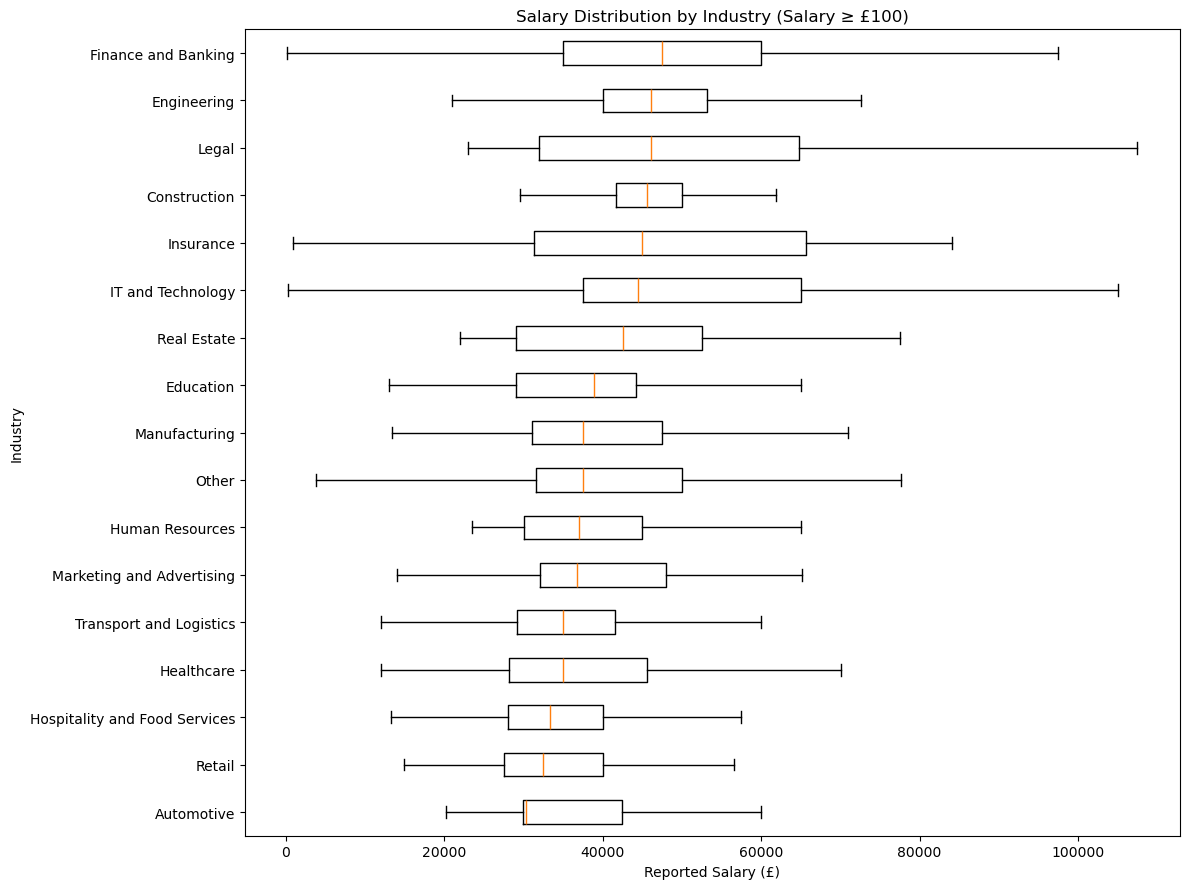

In [39]:
# ============================================================
# STEP 34 — SALARY DISTRIBUTION BOXPLOT BY INDUSTRY
# ============================================================

import matplotlib.pyplot as plt

# Use analytical salary data (salary >= £100)
boxplot_df = salary_adjusted.copy()

# Order industries by median salary
industry_order = (
    boxplot_df
    .groupby("industry_refined")["salary_avg"]
    .median()
    .sort_values()
    .index
)

salary_groups = [
    boxplot_df.loc[
        boxplot_df["industry_refined"] == industry,
        "salary_avg"
    ]
    for industry in industry_order
]

plt.figure(figsize=(12, 9))

plt.boxplot(
    salary_groups,
    vert=False,
    labels=industry_order,
    showfliers=False
)

plt.xlabel("Reported Salary (£)")
plt.ylabel("Industry")
plt.title(
    "Salary Distribution by Industry (Salary ≥ £100)"
)

plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# STEP 35 — EXPERIENCE REQUIREMENT DISTRIBUTION
# ============================================================

experience_distribution = (
    df["experience_category_final"]
    .value_counts(dropna=False)
    .reset_index()
)

experience_distribution.columns = [
    "experience_category",
    "job_count"
]

# Calculate percentage
experience_distribution["percentage"] = (
    experience_distribution["job_count"]
    / len(df)
    * 100
)

# Sort by job count
experience_distribution = (
    experience_distribution
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

print("Total jobs:", len(df))
print(
    "Jobs with experience category:",
    df["experience_category_final"].notna().sum()
)

display(experience_distribution)

Total jobs: 19207
Jobs with experience category: 19207


,experience_category,job_count,percentage
0,Not Specified,12703,66.137346
1,Experience Required,4401,22.913521
2,1–2 Years,1835,9.553809
3,Senior / Extensive Experience,200,1.041287
4,Entry / No Experience,31,0.161399
5,Less than 1 Year,25,0.130161
6,5+ Years,7,0.036445
7,3–5 Years,5,0.026032


In [41]:
# ============================================================
# STEP 36 — EXPERIENCE REQUIREMENT BY INDUSTRY
# ============================================================

experience_by_industry = (
    df.groupby(
        ["industry_refined", "experience_category_final"]
    )
    .size()
    .reset_index(name="job_count")
)

# Calculate total jobs within each industry
industry_totals = (
    df.groupby("industry_refined")
    .size()
    .reset_index(name="total_jobs")
)

experience_by_industry = experience_by_industry.merge(
    industry_totals,
    on="industry_refined",
    how="left"
)

# Calculate percentage within each industry
experience_by_industry["percentage_within_industry"] = (
    experience_by_industry["job_count"]
    / experience_by_industry["total_jobs"]
    * 100
)

# Sort by industry and percentage
experience_by_industry = (
    experience_by_industry
    .sort_values(
        ["industry_refined", "job_count"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print(
    "Industries analysed:",
    experience_by_industry["industry_refined"].nunique()
)

print(
    "Experience categories:",
    experience_by_industry["experience_category_final"].nunique()
)

display(experience_by_industry)

Industries analysed: 17
Experience categories: 8


,industry_refined,experience_category_final,job_count,total_jobs,percentage_within_industry
0,Automotive,Not Specified,169,255,66.274510
1,Automotive,Experience Required,63,255,24.705882
2,Automotive,1–2 Years,23,255,9.019608
3,Construction,Not Specified,866,1369,63.257852
4,Construction,Experience Required,455,1369,33.235939
...,...,...,...,...,...
84,Transport and Logistics,Not Specified,567,948,59.810127
85,Transport and Logistics,Experience Required,261,948,27.531646
86,Transport and Logistics,1–2 Years,111,948,11.708861
87,Transport and Logistics,Less than 1 Year,7,948,0.738397


In [42]:
# ============================================================
# STEP 37 — NUMERIC EXPERIENCE REQUIREMENTS BY INDUSTRY
# ============================================================

numeric_experience = df[
    df["experience_years"].notna()
].copy()

# Exclude potential extreme experience values > 10 years
numeric_experience_clean = numeric_experience[
    numeric_experience["experience_years"] <= 10
].copy()

experience_numeric_by_industry = (
    numeric_experience_clean
    .groupby("industry_refined")["experience_years"]
    .agg(
        numeric_experience_records="count",
        median_experience_years="median",
        mean_experience_years="mean",
        min_experience_years="min",
        max_experience_years="max"
    )
    .reset_index()
)

experience_numeric_by_industry = experience_numeric_by_industry.merge(
    industry_totals,
    on="industry_refined",
    how="left"
)

experience_numeric_by_industry[
    "numeric_experience_percentage"
] = (
    experience_numeric_by_industry["numeric_experience_records"]
    / experience_numeric_by_industry["total_jobs"]
    * 100
)

experience_numeric_by_industry = (
    experience_numeric_by_industry
    .sort_values(
        "median_experience_years",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Numeric experience records:",
    len(numeric_experience)
)

print(
    "Records after excluding experience >10 years:",
    len(numeric_experience_clean)
)

print(
    "Industries analysed:",
    experience_numeric_by_industry["industry_refined"].nunique()
)

display(experience_numeric_by_industry)

Numeric experience records: 1877
Records after excluding experience >10 years: 1874
Industries analysed: 17


,industry_refined,numeric_experience_records,median_experience_years,mean_experience_years,min_experience_years,max_experience_years,total_jobs,numeric_experience_percentage
0,IT and Technology,19,2.0,1.315789,0.000000,2.0,644,2.950311
1,Construction,44,2.0,1.954545,1.000000,2.0,1369,3.214025
2,Retail,33,2.0,2.000000,2.000000,2.0,192,17.187500
3,Other,981,2.0,1.983690,0.083333,10.0,8496,11.546610
4,Marketing and Advertising,13,2.0,1.769231,1.000000,2.0,148,8.783784
5,Manufacturing,147,2.0,1.928571,0.083333,3.0,1277,11.511355
6,Legal,27,2.0,2.037037,1.000000,5.0,240,11.250000
7,Insurance,9,2.0,2.000000,2.000000,2.0,59,15.254237
8,Transport and Logistics,118,2.0,1.861582,0.083333,2.0,948,12.447257
9,Human Resources,25,2.0,1.900000,0.500000,2.0,232,10.775862


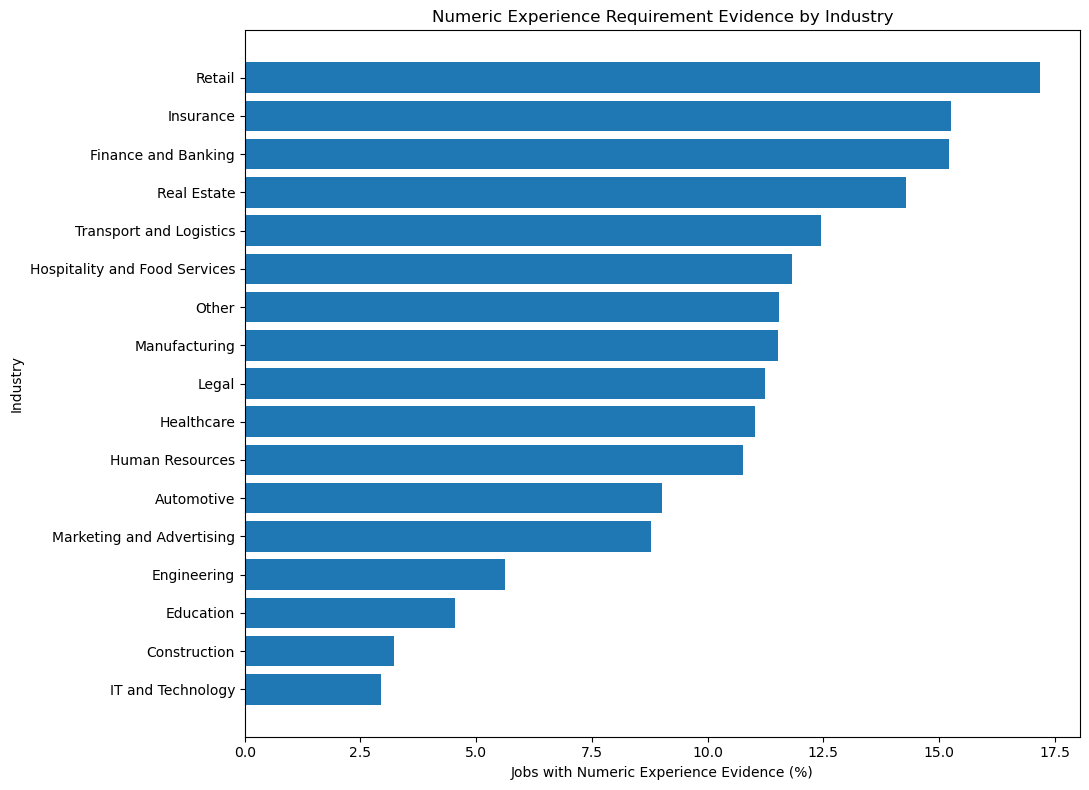

In [43]:
# ============================================================
# STEP 38 — NUMERIC EXPERIENCE EVIDENCE BY INDUSTRY
# ============================================================

import matplotlib.pyplot as plt

plot_df = experience_numeric_by_industry.sort_values(
    "numeric_experience_percentage",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["numeric_experience_percentage"]
)

plt.xlabel("Jobs with Numeric Experience Evidence (%)")
plt.ylabel("Industry")
plt.title(
    "Numeric Experience Requirement Evidence by Industry"
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# STEP 39 — EXPERIENCE REQUIREMENT VS SALARY
# ============================================================

experience_salary_df = df[
    df["experience_years"].notna()
    & df["salary_avg"].notna()
    & (df["salary_avg"] >= 100)
    & (df["experience_years"] <= 10)
].copy()

print(
    "Jobs with numeric experience and analytical salary:",
    len(experience_salary_df)
)

# Summary statistics by experience requirement
experience_salary_summary = (
    experience_salary_df
    .groupby("experience_years")["salary_avg"]
    .agg(
        job_count="count",
        mean_salary="mean",
        median_salary="median",
        min_salary="min",
        max_salary="max"
    )
    .reset_index()
    .sort_values("experience_years")
)

display(experience_salary_summary)

Jobs with numeric experience and analytical salary: 1408


,experience_years,job_count,mean_salary,median_salary,min_salary,max_salary
0,0.000000,5,37500.000000,37500.000,37500.00,37500.00
1,0.083333,6,39644.000000,43000.000,130.00,68484.00
2,0.166667,1,44026.000000,44026.000,44026.00,44026.00
3,0.333333,2,29665.250000,29665.250,27330.50,32000.00
4,0.500000,2,39344.345000,39344.345,31188.69,47500.00
5,0.750000,1,29000.000000,29000.000,29000.00,29000.00
6,0.833333,1,55000.000000,55000.000,55000.00,55000.00
7,1.000000,77,40122.333377,34500.000,24131.89,90000.00
8,1.500000,2,58500.000000,58500.000,54500.00,62500.00
9,2.000000,1302,47527.306317,43405.580,130.00,325000.00


In [45]:
# ============================================================
# STEP 39A — CREATE ANALYSIS-LEVEL EXPERIENCE BANDS
# ============================================================

def create_experience_band(years):

    if pd.isna(years):
        return "Not Available"

    if years <= 1:
        return "Up to 1 Year"

    elif years <= 2:
        return "1–2 Years"

    elif years <= 5:
        return "3–5 Years"

    elif years <= 10:
        return "5–10 Years"

    else:
        return "10+ Years"


# Create a separate analysis column
df["experience_analysis_band"] = (
    df["experience_years"]
    .apply(create_experience_band)
)

# Check distribution
experience_analysis_distribution = (
    df["experience_analysis_band"]
    .value_counts()
    .reset_index()
)

experience_analysis_distribution.columns = [
    "experience_analysis_band",
    "job_count"
]

experience_analysis_distribution["percentage"] = (
    experience_analysis_distribution["job_count"]
    / len(df)
    * 100
)

print("Experience analysis bands created.")

display(experience_analysis_distribution)

Experience analysis bands created.


,experience_analysis_band,job_count,percentage
0,Not Available,17330,90.227521
1,1–2 Years,1743,9.074816
2,Up to 1 Year,122,0.635185
3,3–5 Years,5,0.026032
4,5–10 Years,4,0.020826
5,10+ Years,3,0.015619


In [46]:
# ============================================================
# STEP 39B — SALARY BY EXPERIENCE ANALYSIS BAND
# ============================================================

experience_salary_banded = df[
    df["experience_years"].notna()
    & df["salary_avg"].notna()
    & (df["salary_avg"] >= 100)
    & (df["experience_years"] <= 10)
].copy()

experience_salary_banded_summary = (
    experience_salary_banded
    .groupby("experience_analysis_band")["salary_avg"]
    .agg(
        job_count="count",
        mean_salary="mean",
        median_salary="median",
        min_salary="min",
        max_salary="max"
    )
    .reset_index()
)

# Define logical order for the experience bands
band_order = [
    "Up to 1 Year",
    "1–2 Years",
    "3–5 Years",
    "5–10 Years",
    "10+ Years"
]

experience_salary_banded_summary["band_order"] = (
    experience_salary_banded_summary["experience_analysis_band"]
    .map({band: i for i, band in enumerate(band_order)})
)

experience_salary_banded_summary = (
    experience_salary_banded_summary
    .sort_values("band_order")
    .drop(columns="band_order")
    .reset_index(drop=True)
)

print(
    "Jobs with numeric experience and analytical salary:",
    len(experience_salary_banded)
)

print(
    "Experience bands analysed:",
    len(experience_salary_banded_summary)
)

display(experience_salary_banded_summary)

Jobs with numeric experience and analytical salary: 1408
Experience bands analysed: 4


,experience_analysis_band,job_count,mean_salary,median_salary,min_salary,max_salary
0,Up to 1 Year,95,39798.198526,35000.00,130.0,90000.00
1,1–2 Years,1304,47544.135602,43500.00,130.0,325000.00
2,3–5 Years,5,55422.150000,49832.63,42500.0,75548.97
3,5–10 Years,4,28525.000000,28000.00,600.0,57500.00


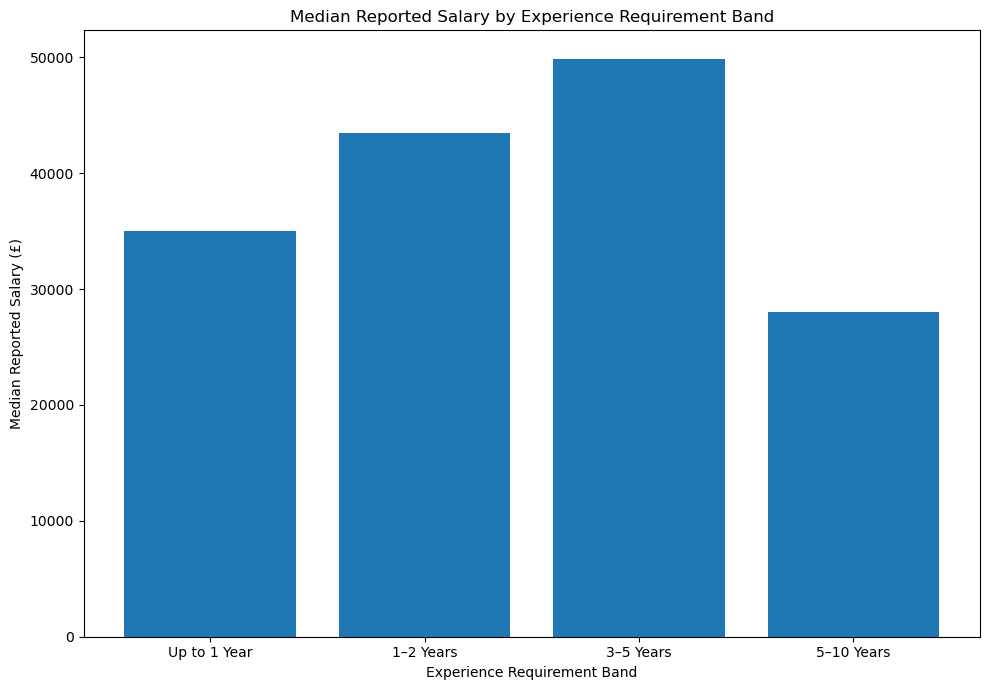

In [47]:
# ============================================================
# STEP 40 — EXPERIENCE BAND VS SALARY
# ============================================================

import matplotlib.pyplot as plt

plot_df = experience_salary_banded_summary.copy()

# Remove bands with no observations
plot_df = plot_df[plot_df["job_count"] > 0].copy()

plt.figure(figsize=(10, 7))

plt.bar(
    plot_df["experience_analysis_band"],
    plot_df["median_salary"]
)

plt.xlabel("Experience Requirement Band")
plt.ylabel("Median Reported Salary (£)")
plt.title(
    "Median Reported Salary by Experience Requirement Band"
)

plt.tight_layout()
plt.show()

In [48]:
# ============================================================
# STEP 41 — EDUCATION REQUIREMENT DISTRIBUTION
# ============================================================

education_distribution = (
    df["education_required"]
    .fillna("Not Specified")
    .replace("", "Not Specified")
    .value_counts()
    .reset_index()
)

education_distribution.columns = [
    "education_requirement",
    "job_count"
]

education_distribution["percentage"] = (
    education_distribution["job_count"]
    / len(df)
    * 100
)

education_distribution = (
    education_distribution
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

print("Total jobs:", len(df))
print(
    "Jobs with education information:",
    (
        (df["education_required"].notna())
        & (df["education_required"].astype(str).str.strip() != "")
    ).sum()
)

print(
    "Unique education requirements:",
    len(education_distribution)
)

display(education_distribution)

Total jobs: 19207
Jobs with education information: 1453
Unique education requirements: 647


,education_requirement,job_count,percentage
0,Not Specified,17754,92.435050
1,Formal teaching experience,125,0.650804
2,[],80,0.416515
3,not specified,69,0.359244
4,Bachelor's degree,69,0.359244
...,...,...,...
642,Degree in French or Spanish,1,0.005206
643,dedicated spanish teacher,1,0.005206
644,religious study,1,0.005206
645,UK Primary Teacher,1,0.005206


In [49]:
# ============================================================
# STEP 42 — NORMALISE EDUCATION REQUIREMENTS
# ============================================================

import re
import pandas as pd

def normalize_education(value):

    if pd.isna(value):
        return "Not Specified"

    text = str(value).strip().lower()

    # Missing / empty values
    if text in ["", "[]", "nan", "none", "not specified", "not_specified"]:
        return "Not Specified"

    # Doctoral level
    if any(keyword in text for keyword in [
        "phd",
        "doctorate",
        "doctoral"
    ]):
        return "PhD / Doctorate"

    # Master's level
    if any(keyword in text for keyword in [
        "master's",
        "masters",
        "master degree",
        "master degree",
        "msc",
        "ma degree",
        "mba"
    ]):
        return "Master's Degree"

    # Bachelor's level
    if any(keyword in text for keyword in [
        "bachelor",
        "bachelor's",
        "bsc",
        "ba degree",
        "undergraduate degree"
    ]):
        return "Bachelor's Degree"

    # HNC / HND
    if any(keyword in text for keyword in [
        "hnc",
        "hnd",
        "higher national certificate",
        "higher national diploma"
    ]):
        return "HNC / HND"

    # NVQ
    if "nvq" in text:
        return "NVQ"

    # Apprenticeship
    if any(keyword in text for keyword in [
        "apprenticeship",
        "apprentice"
    ]):
        return "Apprenticeship"

    # Diploma
    if "diploma" in text:
        return "Diploma"

    # A-level
    if any(keyword in text for keyword in [
        "a level",
        "a-level",
        "alevel"
    ]):
        return "A Level"

    # GCSE
    if "gcse" in text:
        return "GCSE"

    # Teaching-specific qualifications
    if any(keyword in text for keyword in [
        "qts",
        "qualified teacher",
        "teaching qualification",
        "teacher qualification",
        "pgce"
    ]):
        return "Teaching Qualification"

    # Remaining explicitly stated education information
    return "Other Specified"


# Create a new analysis-level education category
df["education_category"] = (
    df["education_required"]
    .apply(normalize_education)
)

# Distribution
education_category_distribution = (
    df["education_category"]
    .value_counts()
    .reset_index()
)

education_category_distribution.columns = [
    "education_category",
    "job_count"
]

education_category_distribution["percentage"] = (
    education_category_distribution["job_count"]
    / len(df)
    * 100
)

education_category_distribution = (
    education_category_distribution
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

print("Total jobs:", len(df))
print(
    "Jobs with specified education category:",
    (df["education_category"] != "Not Specified").sum()
)
print(
    "Jobs without specified education:",
    (df["education_category"] == "Not Specified").sum()
)
print(
    "Number of education categories:",
    len(education_category_distribution)
)

display(education_category_distribution)

Total jobs: 19207
Jobs with specified education category: 1293
Jobs without specified education: 17914
Number of education categories: 12


,education_category,job_count,percentage
0,Not Specified,17914,93.268079
1,Other Specified,1125,5.857240
2,Bachelor's Degree,75,0.390483
3,Apprenticeship,30,0.156193
4,Teaching Qualification,21,0.109335
5,Diploma,10,0.052064
6,HNC / HND,9,0.046858
7,GCSE,8,0.041651
8,NVQ,8,0.041651
9,PhD / Doctorate,4,0.020826


In [50]:
# ============================================================
# STEP 42A — INSPECT OTHER SPECIFIED EDUCATION VALUES
# ============================================================

other_education = (
    df.loc[
        df["education_category"] == "Other Specified",
        "education_required"
    ]
    .value_counts()
    .reset_index()
)

other_education.columns = [
    "raw_education_requirement",
    "job_count"
]

print("Number of raw values classified as Other Specified:",
      len(other_education))

print("Jobs classified as Other Specified:",
      other_education["job_count"].sum())

display(other_education.head(50))

Number of raw values classified as Other Specified: 571
Jobs classified as Other Specified: 1125


,raw_education_requirement,job_count
0,Formal teaching experience,125
1,Not explicitly stated,59
2,Graduate,53
3,graduate,31
4,not explicitly stated,28
5,Qualified Accountant,20
6,Degree,17
7,Qualification,12
8,qualification,12
9,Qualified,11


In [51]:
# ============================================================
# STEP 42B — REFINE EDUCATION CATEGORIES
# ============================================================

def refine_education(value):

    if pd.isna(value):
        return "Not Specified"

    text = str(value).strip().lower()

    # Missing / vague statements
    if text in [
        "",
        "[]",
        "nan",
        "none",
        "not specified",
        "not explicitly stated",
        "not explicitly stated."
    ]:
        return "Not Specified"

    # Doctoral level
    if any(keyword in text for keyword in [
        "phd",
        "doctorate",
        "doctoral"
    ]):
        return "PhD / Doctorate"

    # Master's level
    if any(keyword in text for keyword in [
        "master's",
        "masters",
        "msc",
        "m.sc",
        "ma degree",
        "mba"
    ]):
        return "Master's Degree"

    # Bachelor's / degree-level education
    if any(keyword in text for keyword in [
        "bachelor",
        "bachelor's",
        "bsc",
        "b.sc",
        "ba degree",
        "undergraduate degree"
    ]):
        return "Bachelor's Degree"

    # Explicit degree without specified level
    if (
        text == "degree"
        or text.startswith("degree in ")
        or " degree in " in text
    ):
        return "Degree (Level Not Specified)"

    # Higher National qualifications
    if any(keyword in text for keyword in [
        "hnc",
        "hnd",
        "higher national certificate",
        "higher national diploma"
    ]):
        return "HNC / HND"

    # NVQ
    if "nvq" in text:
        return "NVQ"

    # Apprenticeship
    if any(keyword in text for keyword in [
        "apprenticeship",
        "apprentice"
    ]):
        return "Apprenticeship"

    # GCSE
    if "gcse" in text:
        return "GCSE"

    # A Level
    if any(keyword in text for keyword in [
        "a level",
        "a-level",
        "alevel"
    ]):
        return "A Level"

    # Diploma
    if "diploma" in text:
        return "Diploma"

    # Teaching qualifications / explicit teaching credentials
    if any(keyword in text for keyword in [
        "qts",
        "pgce",
        "qualified teacher",
        "qualified primary teacher",
        "qualified secondary teacher",
        "teaching qualification",
        "teacher qualification"
    ]):
        return "Teaching Qualification"

    # Professional qualifications / registrations
    if any(keyword in text for keyword in [
        "cipd",
        "chartered accountant",
        "qualified accountant",
        "accountant qualification",
        "registered nurse",
        "qualified social worker",
        "professional qualification",
        "part qualified",
        "qualification"
    ]):
        return "Professional Qualification"

    # Clearly experience / job-role statements rather than education
    if any(keyword in text for keyword in [
        "experience",
        "teacher",
        "accountant",
        "manager",
        "entry level",
        "graduate",
        "pqe",
        "year 3",
        "year 5",
        "year 6",
        "highly educated"
    ]):
        return "Other / Unclear"

    # Remaining values that cannot be safely classified
    return "Other / Unclear"


# Create a refined analysis-level category
df["education_category_refined"] = (
    df["education_required"]
    .apply(refine_education)
)

# Create distribution
education_refined_distribution = (
    df["education_category_refined"]
    .value_counts()
    .reset_index()
)

education_refined_distribution.columns = [
    "education_category",
    "job_count"
]

education_refined_distribution["percentage"] = (
    education_refined_distribution["job_count"]
    / len(df)
    * 100
)

education_refined_distribution = (
    education_refined_distribution
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

print("Total jobs:", len(df))
print(
    "Jobs with an explicitly classifiable education/qualification category:",
    (
        ~df["education_category_refined"].isin([
            "Not Specified",
            "Other / Unclear"
        ])
    ).sum()
)

print(
    "Jobs classified as Other / Unclear:",
    (df["education_category_refined"] == "Other / Unclear").sum()
)

print(
    "Jobs with education not specified:",
    (df["education_category_refined"] == "Not Specified").sum()
)

print(
    "Number of refined categories:",
    len(education_refined_distribution)
)

display(education_refined_distribution)

Total jobs: 19207
Jobs with an explicitly classifiable education/qualification category: 406
Jobs classified as Other / Unclear: 798
Jobs with education not specified: 18003
Number of refined categories: 14


,education_category,job_count,percentage
0,Not Specified,18003,93.731452
1,Other / Unclear,798,4.154735
2,Professional Qualification,146,0.760140
3,Degree (Level Not Specified),88,0.458166
4,Bachelor's Degree,75,0.390483
5,Apprenticeship,30,0.156193
6,Teaching Qualification,29,0.150987
7,HNC / HND,8,0.041651
8,GCSE,8,0.041651
9,NVQ,8,0.041651


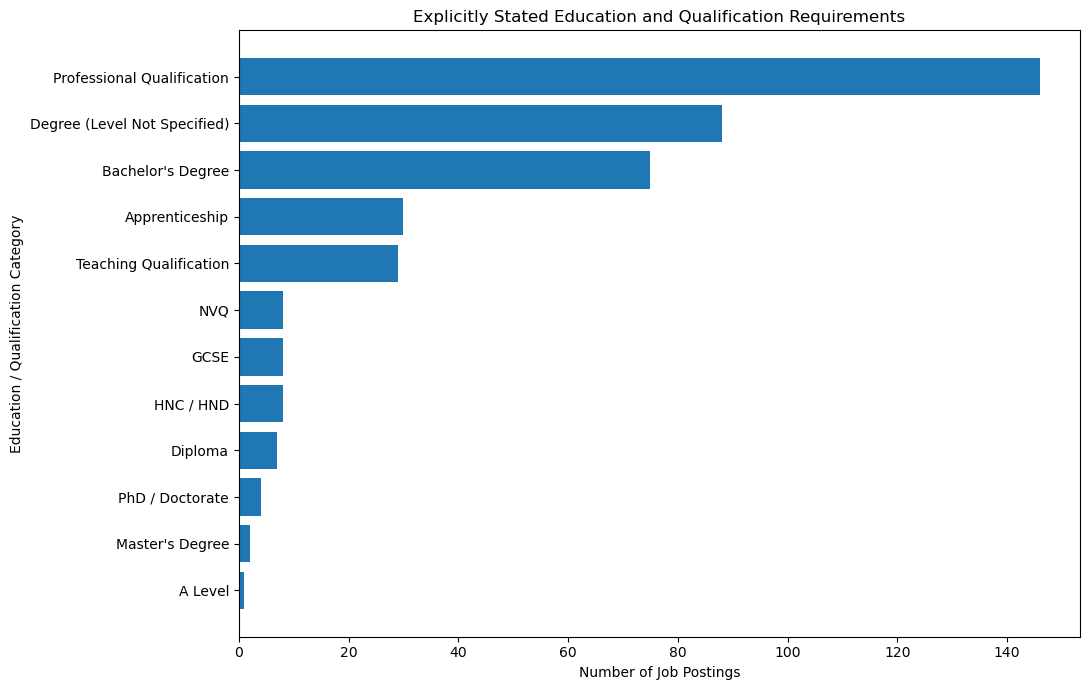

In [52]:
# ============================================================
# STEP 43 — EDUCATION REQUIREMENT VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

# Keep explicitly classifiable education/qualification categories
education_plot_df = education_refined_distribution[
    ~education_refined_distribution["education_category"].isin([
        "Not Specified",
        "Other / Unclear"
    ])
].copy()

# Sort for horizontal bar chart
education_plot_df = education_plot_df.sort_values(
    "job_count",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    education_plot_df["education_category"],
    education_plot_df["job_count"]
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Education / Qualification Category")
plt.title(
    "Explicitly Stated Education and Qualification Requirements"
)

plt.tight_layout()
plt.show()

In [53]:
# ============================================================
# STEP 44 — EDUCATION REQUIREMENTS BY INDUSTRY
# ============================================================

education_industry = (
    df[
        ~df["education_category_refined"].isin([
            "Not Specified",
            "Other / Unclear"
        ])
    ]
    .groupby([
        "industry_refined",
        "education_category_refined"
    ])
    .size()
    .reset_index(name="job_count")
)

# Add total jobs per industry
industry_totals = (
    df.groupby("industry_refined")
    .size()
    .reset_index(name="total_jobs")
)

education_industry = education_industry.merge(
    industry_totals,
    on="industry_refined",
    how="left"
)

education_industry["percentage_within_industry"] = (
    education_industry["job_count"]
    / education_industry["total_jobs"]
    * 100
)

education_industry = education_industry.sort_values(
    ["industry_refined", "job_count"],
    ascending=[True, False]
).reset_index(drop=True)

print(
    "Explicitly classifiable education/qualification records:",
    len(
        df[
            ~df["education_category_refined"].isin([
                "Not Specified",
                "Other / Unclear"
            ])
        ]
    )
)

print(
    "Industries represented:",
    education_industry["industry_refined"].nunique()
)

print(
    "Education-industry records:",
    len(education_industry)
)

display(education_industry)

Explicitly classifiable education/qualification records: 406
Industries represented: 14
Education-industry records: 52


,industry_refined,education_category_refined,job_count,total_jobs,percentage_within_industry
0,Automotive,Professional Qualification,3,255,1.176471
1,Construction,Apprenticeship,8,1369,0.584368
2,Construction,Degree (Level Not Specified),3,1369,0.219138
3,Construction,Professional Qualification,3,1369,0.219138
4,Construction,NVQ,1,1369,0.073046
5,Education,Degree (Level Not Specified),34,1012,3.359684
6,Education,Teaching Qualification,29,1012,2.865613
7,Education,Professional Qualification,22,1012,2.173913
8,Education,Bachelor's Degree,12,1012,1.185771
9,Education,GCSE,5,1012,0.494071


In [54]:
# ============================================================
# STEP 45 — EDUCATION INFORMATION COVERAGE BY INDUSTRY
# ============================================================

education_coverage = (
    df.groupby("industry_refined")
    .agg(
        total_jobs=("job_id", "count"),
        education_records=(
            "education_category_refined",
            lambda x: (
                ~x.isin([
                    "Not Specified",
                    "Other / Unclear"
                ])
            ).sum()
        )
    )
    .reset_index()
)

education_coverage["education_coverage_percentage"] = (
    education_coverage["education_records"]
    / education_coverage["total_jobs"]
    * 100
)

education_coverage = education_coverage.sort_values(
    "education_coverage_percentage",
    ascending=False
).reset_index(drop=True)

print("Total jobs:", len(df))
print(
    "Jobs with explicitly classifiable education/qualification information:",
    (
        ~df["education_category_refined"].isin([
            "Not Specified",
            "Other / Unclear"
        ])
    ).sum()
)

print(
    "Industries represented:",
    education_coverage["industry_refined"].nunique()
)

display(education_coverage)

Total jobs: 19207
Jobs with explicitly classifiable education/qualification information: 406
Industries represented: 17


,industry_refined,total_jobs,education_records,education_coverage_percentage
0,Finance and Banking,1117,121,10.832587
1,Education,1012,103,10.177866
2,Healthcare,263,24,9.125475
3,Human Resources,232,7,3.017241
4,Legal,240,6,2.500000
5,Real Estate,42,1,2.380952
6,Engineering,2583,37,1.432443
7,Automotive,255,3,1.176471
8,Construction,1369,15,1.095690
9,Other,8496,82,0.965160


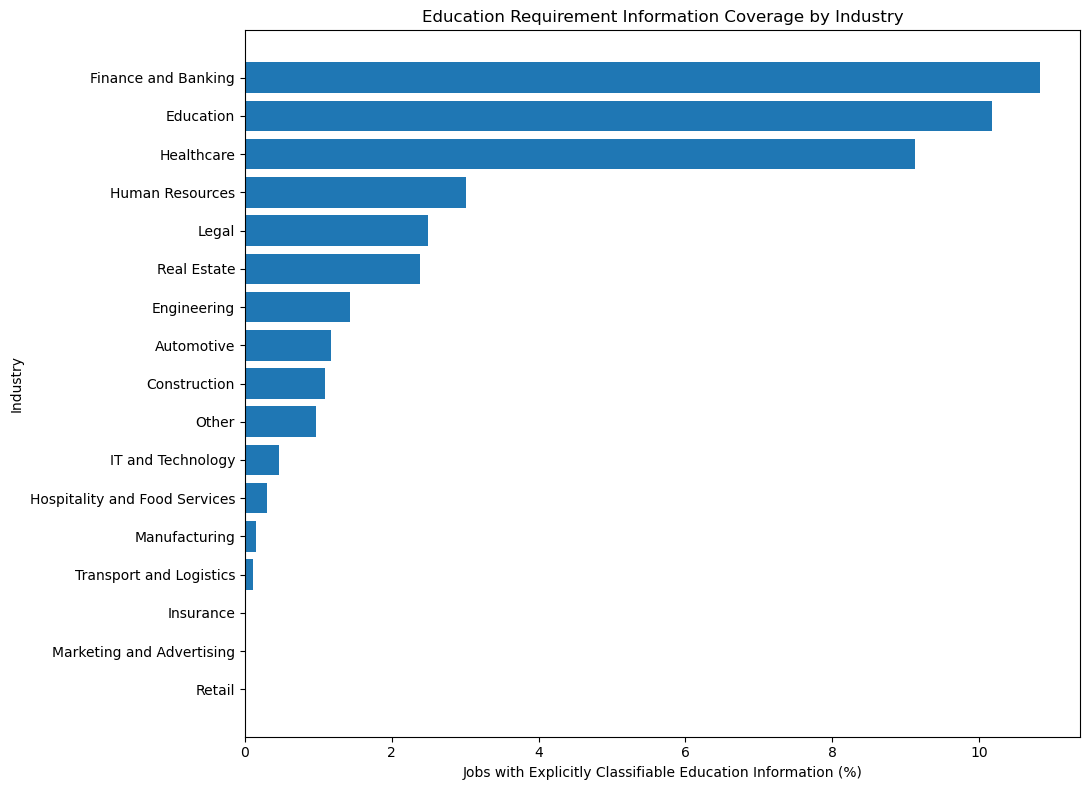

In [55]:
# ============================================================
# STEP 46 — EDUCATION INFORMATION COVERAGE BY INDUSTRY
# ============================================================

import matplotlib.pyplot as plt

plot_df = education_coverage.sort_values(
    "education_coverage_percentage",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["education_coverage_percentage"]
)

plt.xlabel("Jobs with Explicitly Classifiable Education Information (%)")
plt.ylabel("Industry")
plt.title(
    "Education Requirement Information Coverage by Industry"
)

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# STEP 47A — FIND EXISTING PRIORITY DATAFRAMES
# ============================================================

print("DataFrames currently available:")
print()

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        columns = list(obj.columns)

        if (
            "skill_pressure_score" in columns
            or "industry_skill_specialisation_score" in columns
        ):
            print(f"{name}")
            print(f"  Rows: {len(obj)}")
            print(f"  Columns: {columns}")
            print()

DataFrames currently available:

technical_skill_gap_candidates
  Rows: 147
  Columns: ['industry_refined', 'technical_skill', 'job_count', 'industry_job_count', 'demand_percentage', 'overall_job_count', 'overall_demand_percentage', 'relative_demand_ratio', 'demand_score', 'specialisation_score', 'frequency_score', 'industry_skill_specialisation_score', 'specialisation_rank']

high_demand_specialised_skills
  Rows: 46
  Columns: ['industry_refined', 'technical_skill', 'job_count', 'industry_job_count', 'demand_percentage', 'overall_job_count', 'overall_demand_percentage', 'relative_demand_ratio', 'demand_score', 'specialisation_score', 'frequency_score', 'industry_skill_specialisation_score', 'specialisation_rank']

skill_pressure
  Rows: 46
  Columns: ['industry_refined', 'technical_skill', 'job_count', 'industry_job_count', 'demand_percentage', 'overall_job_count', 'overall_demand_percentage', 'relative_demand_ratio', 'demand_score', 'specialisation_score', 'frequency_score', 'indust

In [57]:
# ============================================================
# STEP 47 — INDUSTRY × SKILL PRESSURE OVERVIEW
# ============================================================

# Technical skill pressure by industry
technical_industry_pressure = (
    priority_technical_skills
    .groupby("industry_refined")["skill_pressure_score"]
    .max()
    .reset_index(name="max_technical_skill_pressure")
)

# Soft skill pressure by industry
soft_industry_pressure = (
    soft_skill_priority
    .groupby("industry_refined")["skill_pressure_score"]
    .max()
    .reset_index(name="max_soft_skill_pressure")
)

# Combine technical and soft skill pressure
industry_skill_pressure = pd.merge(
    technical_industry_pressure,
    soft_industry_pressure,
    on="industry_refined",
    how="outer"
)

# Industries with no priority skill in one category receive 0
industry_skill_pressure["max_technical_skill_pressure"] = (
    industry_skill_pressure["max_technical_skill_pressure"]
    .fillna(0)
)

industry_skill_pressure["max_soft_skill_pressure"] = (
    industry_skill_pressure["max_soft_skill_pressure"]
    .fillna(0)
)

# Combined analytical indicator
industry_skill_pressure["combined_skill_pressure"] = (
    industry_skill_pressure["max_technical_skill_pressure"]
    + industry_skill_pressure["max_soft_skill_pressure"]
) / 2

industry_skill_pressure = (
    industry_skill_pressure
    .sort_values("combined_skill_pressure", ascending=False)
    .reset_index(drop=True)
)

print(
    "Industries with technical or soft skill pressure evidence:",
    len(industry_skill_pressure)
)

display(industry_skill_pressure)

Industries with technical or soft skill pressure evidence: 14


,industry_refined,max_technical_skill_pressure,max_soft_skill_pressure,combined_skill_pressure
0,Finance and Banking,0.679985,0.223203,0.451594
1,Construction,0.655133,0.216556,0.435844
2,Transport and Logistics,0.552034,0.250579,0.401307
3,Engineering,0.708272,0.000000,0.354136
4,Retail,0.000000,0.699247,0.349623
5,Education,0.000000,0.527590,0.263795
6,Human Resources,0.000000,0.469617,0.234809
7,Healthcare,0.000000,0.465019,0.232509
8,Real Estate,0.000000,0.456196,0.228098
9,Hospitality and Food Services,0.000000,0.400132,0.200066


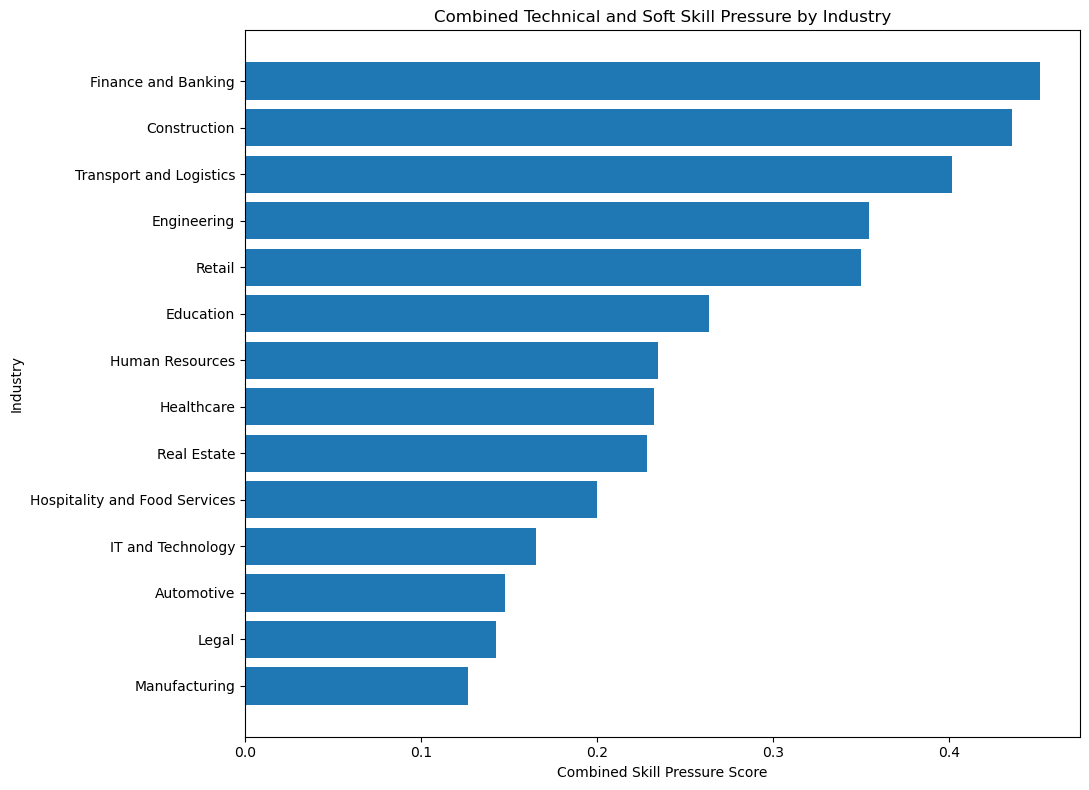

In [58]:
# ============================================================
# STEP 48 — COMBINED INDUSTRY SKILL PRESSURE VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = industry_skill_pressure.sort_values(
    "combined_skill_pressure",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["combined_skill_pressure"]
)

plt.xlabel("Combined Skill Pressure Score")
plt.ylabel("Industry")
plt.title(
    "Combined Technical and Soft Skill Pressure by Industry"
)

plt.tight_layout()
plt.show()

In [59]:
# ============================================================
# STEP 49 — INDUSTRY SKILL PROFILE
# ============================================================

# Technical priority skill profile
technical_profile = (
    priority_technical_skills
    .groupby("industry_refined")["skill_pressure_score"]
    .agg(
        technical_priority_skills="count",
        mean_technical_pressure="mean"
    )
    .reset_index()
)

# Soft priority skill profile
soft_profile = (
    soft_skill_priority
    .groupby("industry_refined")["skill_pressure_score"]
    .agg(
        soft_priority_skills="count",
        mean_soft_pressure="mean"
    )
    .reset_index()
)

# Combine profiles
industry_skill_profile = pd.merge(
    technical_profile,
    soft_profile,
    on="industry_refined",
    how="outer"
)

# Fill missing values
industry_skill_profile["technical_priority_skills"] = (
    industry_skill_profile["technical_priority_skills"]
    .fillna(0)
)

industry_skill_profile["soft_priority_skills"] = (
    industry_skill_profile["soft_priority_skills"]
    .fillna(0)
)

industry_skill_profile["mean_technical_pressure"] = (
    industry_skill_profile["mean_technical_pressure"]
    .fillna(0)
)

industry_skill_profile["mean_soft_pressure"] = (
    industry_skill_profile["mean_soft_pressure"]
    .fillna(0)
)

# Overall average pressure across priority technical and soft skills
industry_skill_profile["mean_combined_pressure"] = (
    industry_skill_profile["mean_technical_pressure"]
    + industry_skill_profile["mean_soft_pressure"]
) / 2

industry_skill_profile = (
    industry_skill_profile
    .sort_values("mean_combined_pressure", ascending=False)
    .reset_index(drop=True)
)

print(
    "Industries with priority technical or soft skills:",
    len(industry_skill_profile)
)

display(industry_skill_profile)

Industries with priority technical or soft skills: 14


,industry_refined,technical_priority_skills,mean_technical_pressure,soft_priority_skills,mean_soft_pressure,mean_combined_pressure
0,Transport and Logistics,1.0,0.552034,2.0,0.244416,0.398225
1,Finance and Banking,5.0,0.317429,1.0,0.223203,0.270316
2,Retail,0.0,0.000000,5.0,0.525542,0.262771
3,Construction,5.0,0.276020,1.0,0.216556,0.246288
4,Real Estate,0.0,0.000000,2.0,0.455753,0.227877
5,Engineering,5.0,0.360730,0.0,0.000000,0.180365
6,Healthcare,0.0,0.000000,5.0,0.352839,0.176419
7,Human Resources,0.0,0.000000,4.0,0.351097,0.175549
8,Education,0.0,0.000000,5.0,0.325816,0.162908
9,Hospitality and Food Services,0.0,0.000000,4.0,0.314146,0.157073


In [60]:
# ============================================================
# STEP 49A — CORRECTED INDUSTRY SKILL PROFILE
# ============================================================

industry_skill_profile["available_pressure_dimensions"] = (
    (industry_skill_profile["technical_priority_skills"] > 0).astype(int)
    + (industry_skill_profile["soft_priority_skills"] > 0).astype(int)
)

industry_skill_profile["mean_combined_pressure"] = (
    industry_skill_profile["mean_technical_pressure"]
    + industry_skill_profile["mean_soft_pressure"]
) / industry_skill_profile["available_pressure_dimensions"]

industry_skill_profile = (
    industry_skill_profile
    .sort_values("mean_combined_pressure", ascending=False)
    .reset_index(drop=True)
)

print(
    "Industries with priority technical or soft skills:",
    len(industry_skill_profile)
)

display(
    industry_skill_profile[
        [
            "industry_refined",
            "technical_priority_skills",
            "mean_technical_pressure",
            "soft_priority_skills",
            "mean_soft_pressure",
            "available_pressure_dimensions",
            "mean_combined_pressure"
        ]
    ]
)

Industries with priority technical or soft skills: 14


,industry_refined,technical_priority_skills,mean_technical_pressure,soft_priority_skills,mean_soft_pressure,available_pressure_dimensions,mean_combined_pressure
0,Retail,0.0,0.000000,5.0,0.525542,1,0.525542
1,Real Estate,0.0,0.000000,2.0,0.455753,1,0.455753
2,Transport and Logistics,1.0,0.552034,2.0,0.244416,2,0.398225
3,Engineering,5.0,0.360730,0.0,0.000000,1,0.360730
4,Healthcare,0.0,0.000000,5.0,0.352839,1,0.352839
5,Human Resources,0.0,0.000000,4.0,0.351097,1,0.351097
6,Education,0.0,0.000000,5.0,0.325816,1,0.325816
7,Hospitality and Food Services,0.0,0.000000,4.0,0.314146,1,0.314146
8,Automotive,0.0,0.000000,1.0,0.295430,1,0.295430
9,IT and Technology,5.0,0.289609,0.0,0.000000,1,0.289609


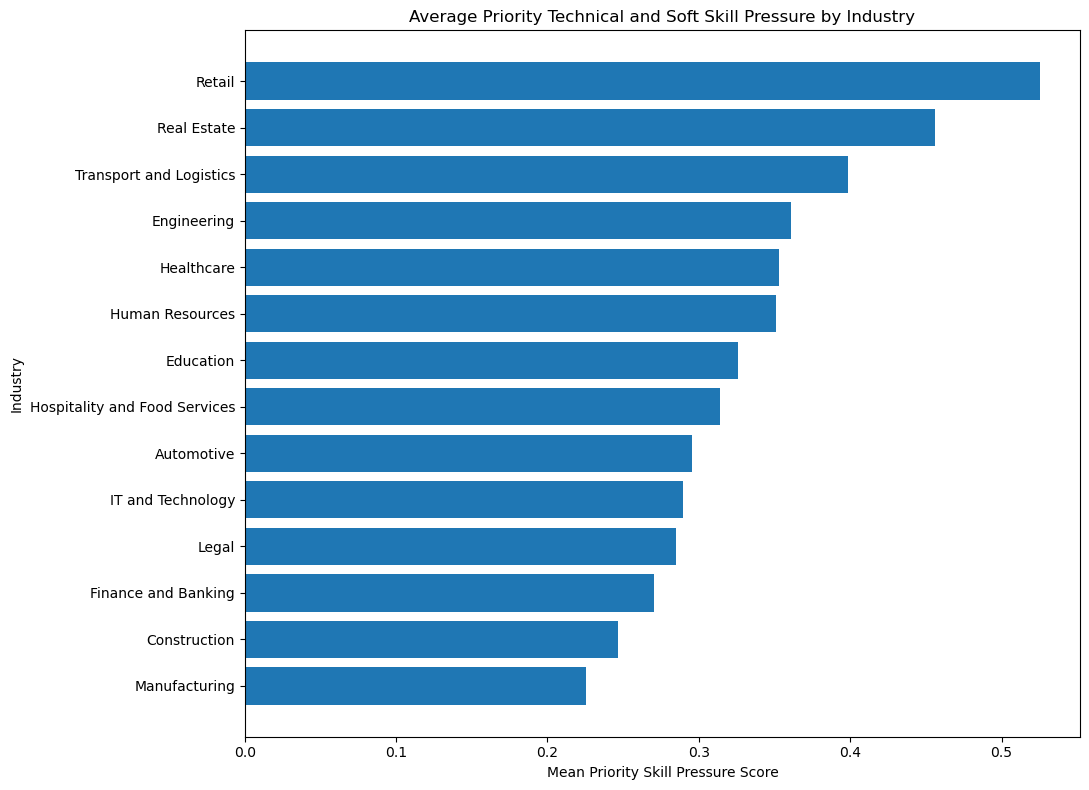

In [61]:
# ============================================================
# STEP 50 — AVERAGE PRIORITY SKILL PRESSURE BY INDUSTRY
# ============================================================

import matplotlib.pyplot as plt

plot_df = industry_skill_profile.sort_values(
    "mean_combined_pressure",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["industry_refined"],
    plot_df["mean_combined_pressure"]
)

plt.xlabel("Mean Priority Skill Pressure Score")
plt.ylabel("Industry")
plt.title(
    "Average Priority Technical and Soft Skill Pressure by Industry"
)

plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# STEP 51 — INTEGRATED INDUSTRY LABOUR-MARKET PROFILE
# ============================================================

# Industry demand
industry_demand_profile = industry_demand[
    ["industry_refined", "job_count", "demand_percentage"]
].copy()

# Adjusted salary information
salary_profile = adjusted_salary_by_industry[
    [
        "industry_refined",
        "median_salary",
        "adjusted_salary_coverage"
    ]
].copy()

# Numeric experience evidence
experience_profile = experience_numeric_by_industry[
    [
        "industry_refined",
        "numeric_experience_records",
        "numeric_experience_percentage",
        "median_experience_years"
    ]
].copy()

# Integrated industry profile
integrated_industry_profile = (
    industry_demand_profile
    .merge(
        salary_profile,
        on="industry_refined",
        how="left"
    )
    .merge(
        experience_profile,
        on="industry_refined",
        how="left"
    )
    .merge(
        industry_skill_profile[
            [
                "industry_refined",
                "technical_priority_skills",
                "soft_priority_skills",
                "mean_combined_pressure"
            ]
        ],
        on="industry_refined",
        how="left"
    )
)

# Sort by observed job demand
integrated_industry_profile = (
    integrated_industry_profile
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

print("Industries in integrated profile:",
      len(integrated_industry_profile))

print("Columns included:")
print(list(integrated_industry_profile.columns))

display(integrated_industry_profile)

Industries in integrated profile: 17
Columns included:
['industry_refined', 'job_count', 'demand_percentage', 'median_salary', 'adjusted_salary_coverage', 'numeric_experience_records', 'numeric_experience_percentage', 'median_experience_years', 'technical_priority_skills', 'soft_priority_skills', 'mean_combined_pressure']


,industry_refined,job_count,demand_percentage,median_salary,adjusted_salary_coverage,numeric_experience_records,numeric_experience_percentage,median_experience_years,technical_priority_skills,soft_priority_skills,mean_combined_pressure
0,Other,8496,44.233873,37467.710,74.658663,981,11.546610,2.0,NaN,NaN,NaN
1,Engineering,2583,13.448222,46134.415,79.442509,145,5.613628,2.0,5.0,0.0,0.360730
2,Construction,1369,7.127610,45548.780,88.531775,44,3.214025,2.0,5.0,1.0,0.246288
3,Manufacturing,1277,6.648618,37500.000,43.304620,147,11.511355,2.0,0.0,5.0,0.225540
4,Finance and Banking,1117,5.815588,47500.000,82.542525,170,15.219338,2.0,5.0,1.0,0.270316
5,Education,1012,5.268912,38921.740,91.007905,46,4.545455,2.0,0.0,5.0,0.325816
6,Transport and Logistics,948,4.935701,35000.000,49.894515,118,12.447257,2.0,1.0,2.0,0.398225
7,IT and Technology,644,3.352944,44393.590,74.223602,19,2.950311,2.0,5.0,0.0,0.289609
8,Hospitality and Food Services,330,1.718124,33280.000,85.151515,39,11.818182,2.0,0.0,4.0,0.314146
9,Healthcare,263,1.369292,35000.000,86.311787,29,11.026616,2.0,0.0,5.0,0.352839


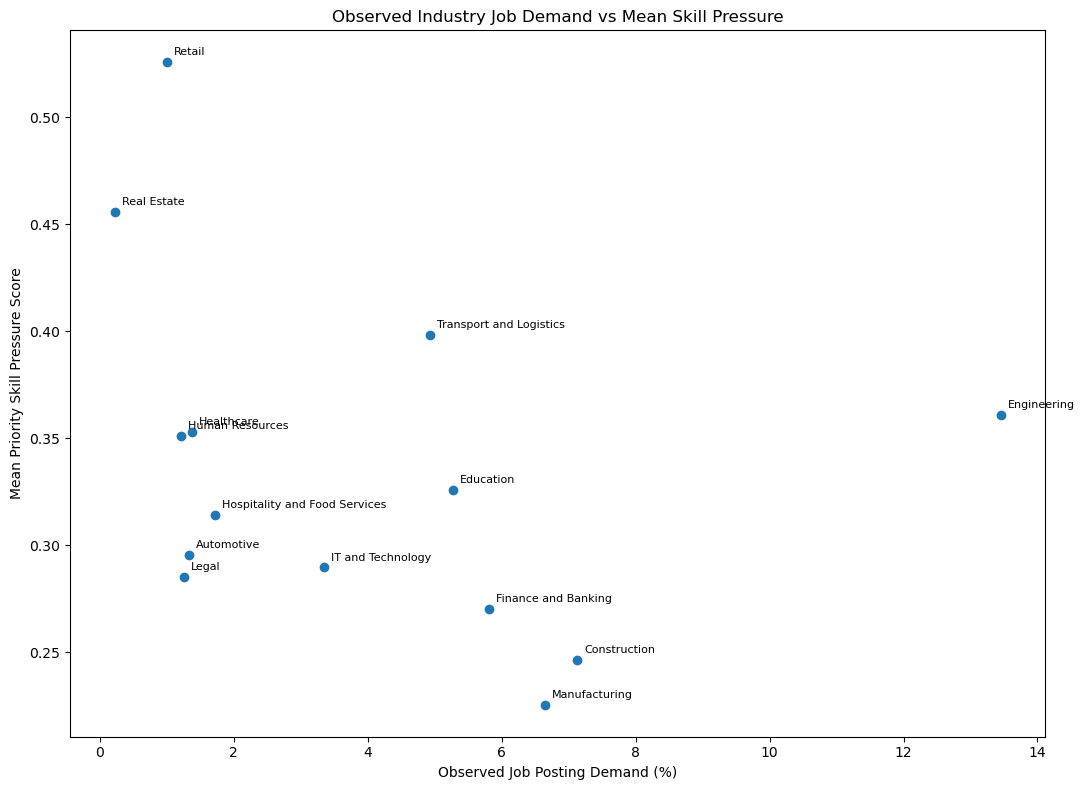

In [63]:
# ============================================================
# STEP 52 — INDUSTRY DEMAND VS SKILL PRESSURE
# ============================================================

plot_df = integrated_industry_profile[
    integrated_industry_profile["mean_combined_pressure"].notna()
].copy()

plt.figure(figsize=(11, 8))

plt.scatter(
    plot_df["demand_percentage"],
    plot_df["mean_combined_pressure"]
)

for _, row in plot_df.iterrows():
    plt.annotate(
        row["industry_refined"],
        (
            row["demand_percentage"],
            row["mean_combined_pressure"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Observed Job Posting Demand (%)")
plt.ylabel("Mean Priority Skill Pressure Score")
plt.title(
    "Observed Industry Job Demand vs Mean Skill Pressure"
)

plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# STEP 53 — FINAL INTEGRATED VALIDATION
# ============================================================

print("============================================================")
print("FINAL INTEGRATED DATA VALIDATION")
print("============================================================")

# Dataset structure
print("\nDataset:")
print("Rows:", len(df))
print("Columns:", len(df.columns))

# Job ID validation
print("\nJob ID validation:")
print("Missing job IDs:", df["job_id"].isna().sum())
print("Duplicate job IDs:", df["job_id"].duplicated().sum())

# Industry validation
print("\nIndustry validation:")
print("Number of industries:", df["industry_refined"].nunique())
print("Missing industries:", df["industry_refined"].isna().sum())

# Salary validation
print("\nSalary validation:")
print("Salary records:", df["salary_avg"].notna().sum())
print("Missing salary:", df["salary_avg"].isna().sum())
print("Negative salaries:", (df["salary_avg"] < 0).sum())

# Experience validation
print("\nExperience validation:")
print(
    "Missing final experience categories:",
    df["experience_category_final"].isna().sum()
)
print(
    "Numeric experience records:",
    df["experience_years"].notna().sum()
)
print(
    "Experience values above 10 years:",
    (df["experience_years"] > 10).sum()
)

# Education validation
print("\nEducation validation:")
print(
    "Education category values:",
    df["education_category_refined"].nunique()
)
print(
    "Explicitly classifiable education records:",
    (
        ~df["education_category_refined"].isin([
            "Not Specified",
            "Other / Unclear"
        ])
    ).sum()
)

# Skill analysis validation
print("\nSkill analysis:")
print(
    "Technical priority skill records:",
    len(priority_technical_skills)
)
print(
    "Soft priority skill records:",
    len(soft_skill_priority)
)
print(
    "Industries with integrated skill pressure:",
    len(industry_skill_profile)
)

# Integrated profile validation
print("\nIntegrated profile:")
print(
    "Industries in integrated profile:",
    len(integrated_industry_profile)
)

print(
    "Missing demand values:",
    integrated_industry_profile["demand_percentage"].isna().sum()
)

print(
    "Missing salary values:",
    integrated_industry_profile["median_salary"].isna().sum()
)

print(
    "Missing skill-pressure values:",
    integrated_industry_profile["mean_combined_pressure"].isna().sum()
)

print("\n============================================================")
print("VALIDATION COMPLETE")
print("============================================================")

FINAL INTEGRATED DATA VALIDATION

Dataset:
Rows: 19207
Columns: 56

Job ID validation:
Missing job IDs: 0
Duplicate job IDs: 0

Industry validation:
Number of industries: 17
Missing industries: 0

Salary validation:
Salary records: 16775
Missing salary: 2432
Negative salaries: 0

Experience validation:
Missing final experience categories: 0
Numeric experience records: 1877
Experience values above 10 years: 3

Education validation:
Education category values: 14
Explicitly classifiable education records: 406

Skill analysis:
Technical priority skill records: 21
Soft priority skill records: 36
Industries with integrated skill pressure: 14

Integrated profile:
Industries in integrated profile: 17
Missing demand values: 0
Missing salary values: 0
Missing skill-pressure values: 3

VALIDATION COMPLETE


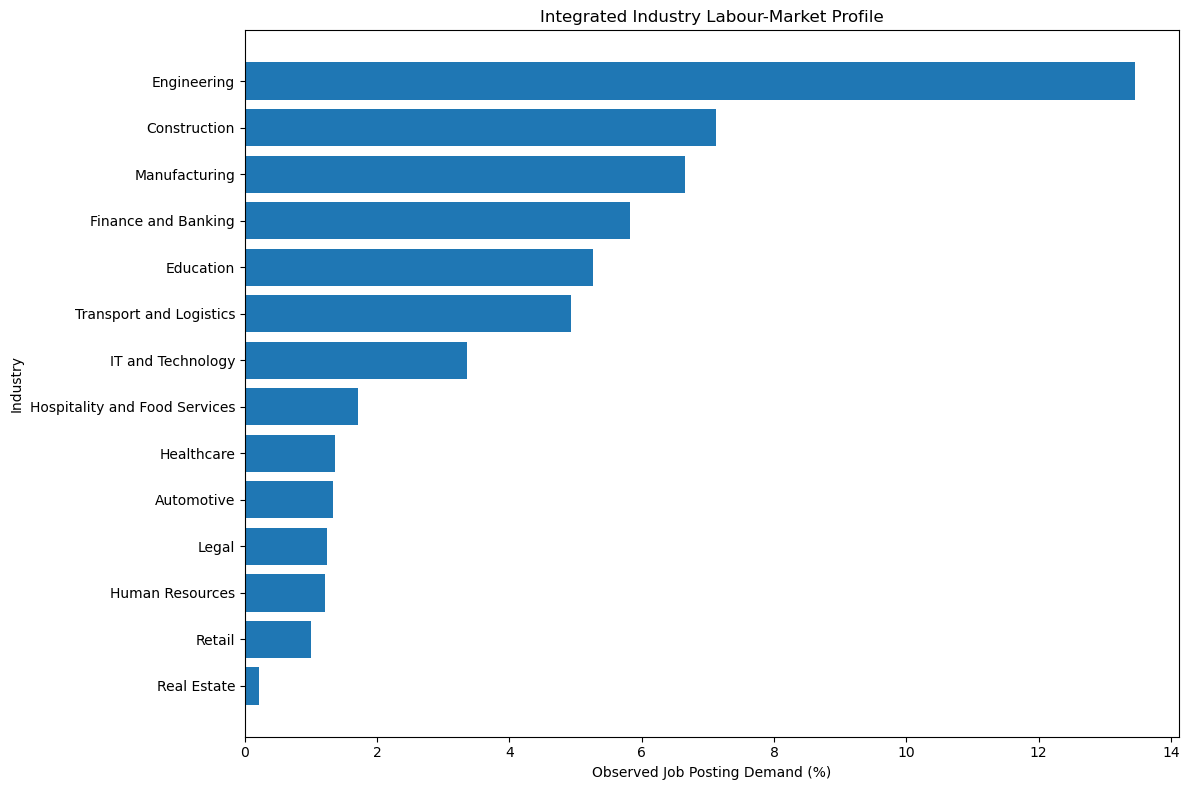

In [65]:
# ============================================================
# STEP 54 — FINAL INTEGRATED INDUSTRY PROFILE
# ============================================================

import matplotlib.pyplot as plt

plot_df = integrated_industry_profile[
    integrated_industry_profile["mean_combined_pressure"].notna()
].copy()

plot_df = plot_df.sort_values(
    "demand_percentage",
    ascending=True
)

fig, ax1 = plt.subplots(figsize=(12, 8))

# Job demand
ax1.barh(
    plot_df["industry_refined"],
    plot_df["demand_percentage"]
)

ax1.set_xlabel("Observed Job Posting Demand (%)")
ax1.set_ylabel("Industry")

ax1.set_title(
    "Integrated Industry Labour-Market Profile"
)

plt.tight_layout()
plt.show()

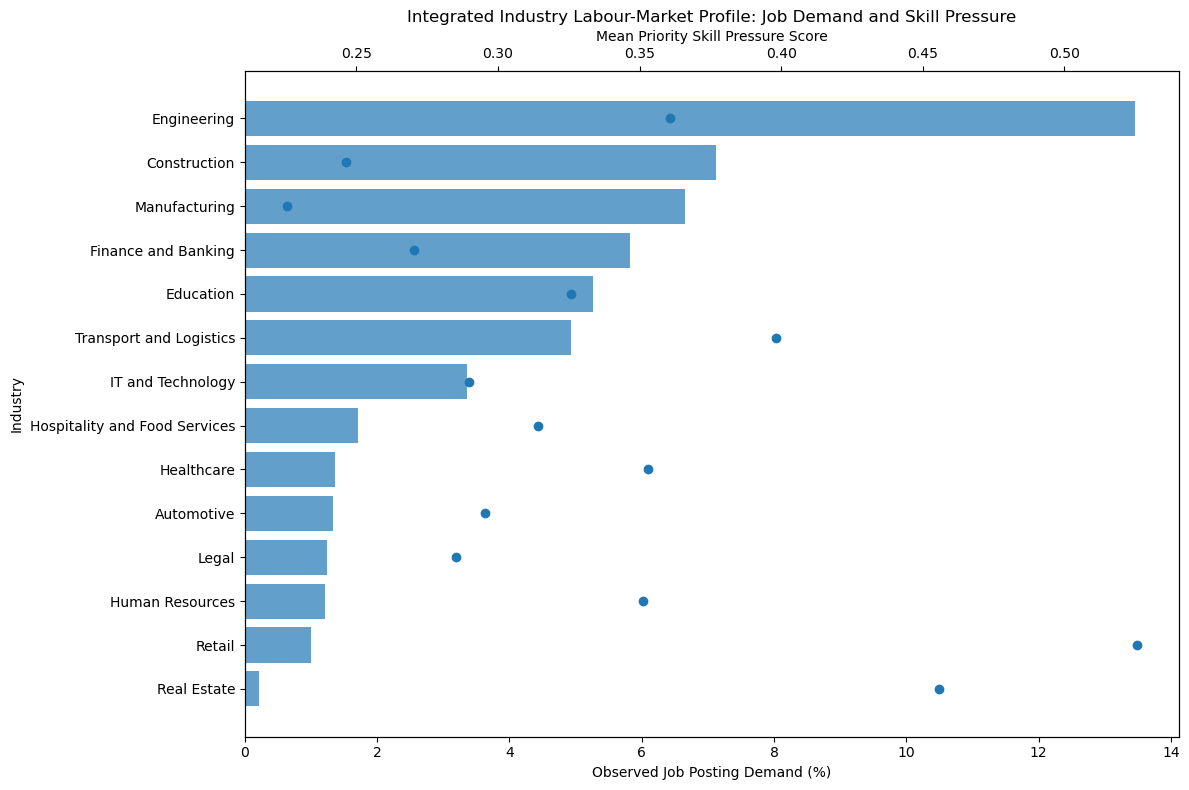

In [66]:
# ============================================================
# STEP 54A — FINAL INTEGRATED INDUSTRY PROFILE
# ============================================================

import matplotlib.pyplot as plt

plot_df = integrated_industry_profile[
    integrated_industry_profile["mean_combined_pressure"].notna()
].copy()

plot_df = plot_df.sort_values(
    "demand_percentage",
    ascending=True
)

fig, ax1 = plt.subplots(figsize=(12, 8))

# ------------------------------------------------------------
# Job demand
# ------------------------------------------------------------
ax1.barh(
    plot_df["industry_refined"],
    plot_df["demand_percentage"],
    alpha=0.7
)

ax1.set_xlabel("Observed Job Posting Demand (%)")
ax1.set_ylabel("Industry")

# ------------------------------------------------------------
# Skill pressure on second x-axis
# ------------------------------------------------------------
ax2 = ax1.twiny()

ax2.plot(
    plot_df["mean_combined_pressure"],
    plot_df["industry_refined"],
    "o"
)

ax2.set_xlabel("Mean Priority Skill Pressure Score")

plt.title(
    "Integrated Industry Labour-Market Profile: "
    "Job Demand and Skill Pressure"
)

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# STEP 55 — EXPORT FINAL ANALYTICAL RESULTS
# ============================================================

import os

output_dir = "outputs"

os.makedirs(output_dir, exist_ok=True)

# 1. Industry demand
industry_demand.to_csv(
    os.path.join(output_dir, "industry_demand.csv"),
    index=False
)

# 2. Adjusted salary by industry
adjusted_salary_by_industry.to_csv(
    os.path.join(output_dir, "adjusted_salary_by_industry.csv"),
    index=False
)

# 3. Numeric experience by industry
experience_numeric_by_industry.to_csv(
    os.path.join(output_dir, "experience_numeric_by_industry.csv"),
    index=False
)

# 4. Education coverage by industry
education_coverage.to_csv(
    os.path.join(output_dir, "education_coverage_by_industry.csv"),
    index=False
)

# 5. Technical priority skills
priority_technical_skills.to_csv(
    os.path.join(output_dir, "priority_technical_skills.csv"),
    index=False
)

# 6. Soft-skill priority
soft_skill_priority.to_csv(
    os.path.join(output_dir, "priority_soft_skills.csv"),
    index=False
)

# 7. Industry skill profile
industry_skill_profile.to_csv(
    os.path.join(output_dir, "industry_skill_profile.csv"),
    index=False
)

# 8. Final integrated industry profile
integrated_industry_profile.to_csv(
    os.path.join(output_dir, "integrated_industry_profile.csv"),
    index=False
)

print("Final analytical outputs exported successfully.")
print("\nFiles created:")

for filename in [
    "industry_demand.csv",
    "adjusted_salary_by_industry.csv",
    "experience_numeric_by_industry.csv",
    "education_coverage_by_industry.csv",
    "priority_technical_skills.csv",
    "priority_soft_skills.csv",
    "industry_skill_profile.csv",
    "integrated_industry_profile.csv"
]:
    print("✓", os.path.join(output_dir, filename))

Final analytical outputs exported successfully.

Files created:
✓ outputs\industry_demand.csv
✓ outputs\adjusted_salary_by_industry.csv
✓ outputs\experience_numeric_by_industry.csv
✓ outputs\education_coverage_by_industry.csv
✓ outputs\priority_technical_skills.csv
✓ outputs\priority_soft_skills.csv
✓ outputs\industry_skill_profile.csv
✓ outputs\integrated_industry_profile.csv


In [68]:
# ============================================================
# STEP 56 — CREATE FINAL RESULTS EXCEL WORKBOOK
# ============================================================

import os
import pandas as pd

output_dir = "outputs"
os.makedirs(output_dir, exist_ok=True)

excel_path = os.path.join(
    output_dir,
    "Labour_Market_Intelligence_Final_Results.xlsx"
)

# ------------------------------------------------------------
# Validation summary
# ------------------------------------------------------------

validation_summary = pd.DataFrame({
    "Metric": [
        "Total Jobs",
        "Total Columns",
        "Missing Job IDs",
        "Duplicate Job IDs",
        "Number of Industries",
        "Missing Industries",
        "Salary Records",
        "Missing Salary Records",
        "Negative Salary Values",
        "Numeric Experience Records",
        "Experience Values Above 10 Years",
        "Explicitly Classifiable Education Records",
        "Technical Priority Skill Records",
        "Soft Priority Skill Records",
        "Industries with Skill Pressure Evidence",
        "Industries in Integrated Profile"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df["job_id"].isna().sum(),
        df["job_id"].duplicated().sum(),
        df["industry_refined"].nunique(),
        df["industry_refined"].isna().sum(),
        df["salary_avg"].notna().sum(),
        df["salary_avg"].isna().sum(),
        (df["salary_avg"] < 0).sum(),
        df["experience_years"].notna().sum(),
        (df["experience_years"] > 10).sum(),
        (
            ~df["education_category_refined"].isin([
                "Not Specified",
                "Other / Unclear"
            ])
        ).sum(),
        len(priority_technical_skills),
        len(soft_skill_priority),
        len(industry_skill_profile),
        len(integrated_industry_profile)
    ]
})

# ------------------------------------------------------------
# Export all final analytical tables
# ------------------------------------------------------------

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    industry_demand.to_excel(
        writer,
        sheet_name="Industry Demand",
        index=False
    )

    adjusted_salary_by_industry.to_excel(
        writer,
        sheet_name="Salary Analysis",
        index=False
    )

    experience_numeric_by_industry.to_excel(
        writer,
        sheet_name="Experience Analysis",
        index=False
    )

    education_coverage.to_excel(
        writer,
        sheet_name="Education Coverage",
        index=False
    )

    priority_technical_skills.to_excel(
        writer,
        sheet_name="Technical Skills",
        index=False
    )

    soft_skill_priority.to_excel(
        writer,
        sheet_name="Soft Skills",
        index=False
    )

    industry_skill_profile.to_excel(
        writer,
        sheet_name="Skill Profile",
        index=False
    )

    integrated_industry_profile.to_excel(
        writer,
        sheet_name="Integrated Profile",
        index=False
    )

    validation_summary.to_excel(
        writer,
        sheet_name="Validation",
        index=False
    )

print("============================================================")
print("FINAL RESULTS WORKBOOK CREATED")
print("============================================================")
print()
print("File:", excel_path)
print()
print("Sheets included:")

for sheet in [
    "Industry Demand",
    "Salary Analysis",
    "Experience Analysis",
    "Education Coverage",
    "Technical Skills",
    "Soft Skills",
    "Skill Profile",
    "Integrated Profile",
    "Validation"
]:
    print("✓", sheet)

print()
print("Total sheets:", 9)

FINAL RESULTS WORKBOOK CREATED

File: outputs\Labour_Market_Intelligence_Final_Results.xlsx

Sheets included:
✓ Industry Demand
✓ Salary Analysis
✓ Experience Analysis
✓ Education Coverage
✓ Technical Skills
✓ Soft Skills
✓ Skill Profile
✓ Integrated Profile
✓ Validation

Total sheets: 9


In [69]:
# ============================================================
# STEP 57 — KEY FINDINGS SUMMARY
# ============================================================

key_findings = pd.DataFrame({
    "Analysis": [
        "Dataset size",
        "Industry classification",
        "Largest industry",
        "Second-largest industry",
        "Salary records",
        "Salary coverage",
        "Adjusted highest median salary",
        "Numeric experience records",
        "Most common numeric experience requirement",
        "Education information coverage",
        "Technical skill records",
        "Soft skill records",
        "Top technical skill",
        "Top soft skill",
        "Highest mean skill-pressure industry",
        "Highest observed-demand industry"
    ],
    
    "Finding": [
        f"{len(df):,} job postings",
        
        f"{df['industry_refined'].nunique()} industries",
        
        (
            industry_demand.iloc[0]["industry_refined"]
            + " ("
            + f"{industry_demand.iloc[0]['job_count']:,} jobs)"
        ),
        
        (
            industry_demand.iloc[1]["industry_refined"]
            + " ("
            + f"{industry_demand.iloc[1]['job_count']:,} jobs)"
        ),
        
        f"{df['salary_avg'].notna().sum():,} jobs",
        
        f"{df['salary_avg'].notna().mean() * 100:.2f}%",
        
        (
            adjusted_salary_by_industry.loc[
                adjusted_salary_by_industry["median_salary"].idxmax(),
                "industry_refined"
            ]
            + " (£"
            + f"{adjusted_salary_by_industry['median_salary'].max():,.2f}"
            + ")"
        ),
        
        f"{df['experience_years'].notna().sum():,} jobs",
        
        (
            experience_salary_banded_summary.loc[
                experience_salary_banded_summary["job_count"].idxmax(),
                "experience_analysis_band"
            ]
            + " ("
            + f"{experience_salary_banded_summary['job_count'].max():,} jobs)"
        ),
        
        (
            f"{(
                ~df['education_category_refined'].isin([
                    'Not Specified',
                    'Other / Unclear'
                ])
            ).sum():,} jobs"
        ),
        
        f"{(df['technical_skills_analysis_parsed'].apply(len) > 0).sum():,} jobs",
        
        f"{(df['soft_skills_analysis_parsed'].apply(len) > 0).sum():,} jobs",
        
        (
            df["technical_skills_analysis_parsed"]
            .explode()
            .value_counts()
            .index[0]
        ),
        
        (
            df["soft_skills_analysis_parsed"]
            .explode()
            .value_counts()
            .index[0]
        ),
        
        (
            industry_skill_profile.loc[
                industry_skill_profile["mean_combined_pressure"].idxmax(),
                "industry_refined"
            ]
            + " ("
            + f"{industry_skill_profile['mean_combined_pressure'].max():.3f}"
            + ")"
        ),
        
        (
            industry_demand.iloc[0]["industry_refined"]
            + " ("
            + f"{industry_demand.iloc[0]['demand_percentage']:.2f}%"
            + ")"
        )
    ]
})

display(key_findings)

# Export
key_findings.to_csv(
    os.path.join(output_dir, "key_findings_summary.csv"),
    index=False
)

print("\nKey findings summary exported:")
print(os.path.join(output_dir, "key_findings_summary.csv"))

,Analysis,Finding
0,Dataset size,"19,207 job postings"
1,Industry classification,17 industries
2,Largest industry,"Other (8,496 jobs)"
3,Second-largest industry,"Engineering (2,583 jobs)"
4,Salary records,"16,775 jobs"
5,Salary coverage,87.34%
6,Adjusted highest median salary,"Finance and Banking (£47,500.00)"
7,Numeric experience records,"1,877 jobs"
8,Most common numeric experience requirement,"1–2 Years (1,304 jobs)"
9,Education information coverage,406 jobs



Key findings summary exported:
outputs\key_findings_summary.csv


In [70]:
# ============================================================
# STEP 41 — EDUCATION REQUIREMENT CATEGORY CLEANING
# ============================================================

import pandas as pd
import numpy as np

# Work from the original education field
education_df = df[["job_id", "industry_refined", "education_required"]].copy()

# Convert missing values to empty strings
education_df["education_text"] = (
    education_df["education_required"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Remove empty / invalid values
education_df.loc[
    education_df["education_text"].isin(["", "[]", "nan", "None", "not specified"]),
    "education_text"
] = ""

# Create broad, interpretable education categories
def classify_education(text):
    text = text.lower().strip()

    if text == "":
        return "Not Explicitly Stated"

    if any(x in text for x in [
        "phd", "doctorate", "doctoral"
    ]):
        return "PhD / Doctorate"

    if any(x in text for x in [
        "master", "msc", "ma ", "mba", "m.eng", "meng"
    ]):
        return "Postgraduate Degree"

    if any(x in text for x in [
        "bachelor", "degree", "bsc", "ba ", "beng", "undergraduate",
        "higher education"
    ]):
        return "Degree"

    if any(x in text for x in [
        "apprentice", "apprenticeship"
    ]):
        return "Apprenticeship"

    if any(x in text for x in [
        "hnd", "hnc", "higher national"
    ]):
        return "HND / HNC"

    if any(x in text for x in [
        "nvq", "national vocational"
    ]):
        return "NVQ / Vocational Qualification"

    if any(x in text for x in [
        "gcse", "a level", "a-level", "alevel"
    ]):
        return "School Qualification"

    if any(x in text for x in [
        "qualification", "qualified", "certificate", "certification",
        "diploma", "professional qualification"
    ]):
        return "Professional / Other Qualification"

    return "Other Explicit Requirement"


education_df["education_category"] = education_df["education_text"].apply(
    classify_education
)

# Summary
education_category_summary = (
    education_df["education_category"]
    .value_counts()
    .reset_index()
)

education_category_summary.columns = [
    "education_category",
    "job_count"
]

education_category_summary["percentage"] = (
    education_category_summary["job_count"]
    / len(education_df)
    * 100
)

print("=" * 60)
print("EDUCATION REQUIREMENT CATEGORY ANALYSIS")
print("=" * 60)

print("Total jobs:", len(education_df))

print(
    "Jobs with explicitly stated education information:",
    (education_df["education_category"] != "Not Explicitly Stated").sum()
)

print(
    "Jobs without explicitly stated education information:",
    (education_df["education_category"] == "Not Explicitly Stated").sum()
)

print()
display(education_category_summary)

EDUCATION REQUIREMENT CATEGORY ANALYSIS
Total jobs: 19207
Jobs with explicitly stated education information: 1304
Jobs without explicitly stated education information: 17903



,education_category,job_count,percentage
0,Not Explicitly Stated,17903,93.210809
1,Other Explicit Requirement,802,4.175561
2,Professional / Other Qualification,243,1.265164
3,Degree,188,0.978810
4,Apprenticeship,31,0.161399
5,Postgraduate Degree,16,0.083303
6,School Qualification,9,0.046858
7,NVQ / Vocational Qualification,7,0.036445
8,HND / HNC,4,0.020826
9,PhD / Doctorate,4,0.020826


In [71]:
# ============================================================
# STEP 42 — EDUCATION REQUIREMENTS BY INDUSTRY
# ============================================================

# Education categories considered relevant for analysis
education_relevant_categories = [
    "Professional / Other Qualification",
    "Degree",
    "Apprenticeship",
    "Postgraduate Degree",
    "School Qualification",
    "NVQ / Vocational Qualification",
    "HND / HNC",
    "PhD / Doctorate"
]

# Keep only explicitly classifiable education requirements
education_by_industry_df = education_df[
    education_df["education_category"].isin(
        education_relevant_categories
    )
].copy()

# Count education requirements by industry and category
education_industry_summary = (
    education_by_industry_df
    .groupby(
        ["industry_refined", "education_category"]
    )
    .size()
    .reset_index(name="job_count")
)

# Total jobs per industry
industry_totals = (
    df.groupby("industry_refined")
    .size()
    .reset_index(name="total_jobs")
)

# Add industry totals
education_industry_summary = education_industry_summary.merge(
    industry_totals,
    on="industry_refined",
    how="left"
)

# Calculate percentage of all jobs in each industry
education_industry_summary["percentage_of_industry_jobs"] = (
    education_industry_summary["job_count"]
    / education_industry_summary["total_jobs"]
    * 100
)

# Sort by industry and job count
education_industry_summary = (
    education_industry_summary
    .sort_values(
        ["industry_refined", "job_count"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("=" * 60)
print("EDUCATION REQUIREMENTS BY INDUSTRY")
print("=" * 60)

print(
    "Education-relevant records:",
    len(education_by_industry_df)
)

print(
    "Industries represented:",
    education_industry_summary["industry_refined"].nunique()
)

print()

display(education_industry_summary)

EDUCATION REQUIREMENTS BY INDUSTRY
Education-relevant records: 502
Industries represented: 15



,industry_refined,education_category,job_count,total_jobs,percentage_of_industry_jobs
0,Automotive,Professional / Other Qualification,4,255,1.568627
1,Automotive,Degree,1,255,0.392157
2,Construction,Apprenticeship,8,1369,0.584368
3,Construction,Professional / Other Qualification,5,1369,0.365230
4,Construction,Degree,4,1369,0.292184
5,Construction,NVQ / Vocational Qualification,1,1369,0.073046
6,Education,Professional / Other Qualification,67,1012,6.620553
7,Education,Degree,45,1012,4.446640
8,Education,School Qualification,5,1012,0.494071
9,Education,Postgraduate Degree,2,1012,0.197628


In [72]:
# ============================================================
# STEP 43 — EDUCATION REQUIREMENTS VISUALISATION
# ============================================================

# Aggregate education categories across all industries
education_visual_summary = (
    education_by_industry_df["education_category"]
    .value_counts()
    .reset_index()
)

education_visual_summary.columns = [
    "education_category",
    "job_count"
]

education_visual_summary["percentage"] = (
    education_visual_summary["job_count"]
    / education_visual_summary["job_count"].sum()
    * 100
)

# Sort for horizontal bar chart
education_visual_summary = (
    education_visual_summary
    .sort_values("job_count", ascending=True)
    .reset_index(drop=True)
)

print("=" * 60)
print("EDUCATION REQUIREMENTS VISUALISATION DATA")
print("=" * 60)

print(
    "Education-relevant records:",
    education_visual_summary["job_count"].sum()
)

print(
    "Education categories:",
    len(education_visual_summary)
)

display(education_visual_summary)

EDUCATION REQUIREMENTS VISUALISATION DATA
Education-relevant records: 502
Education categories: 8


,education_category,job_count,percentage
0,HND / HNC,4,0.796813
1,PhD / Doctorate,4,0.796813
2,NVQ / Vocational Qualification,7,1.394422
3,School Qualification,9,1.792829
4,Postgraduate Degree,16,3.187251
5,Apprenticeship,31,6.175299
6,Degree,188,37.450199
7,Professional / Other Qualification,243,48.406375


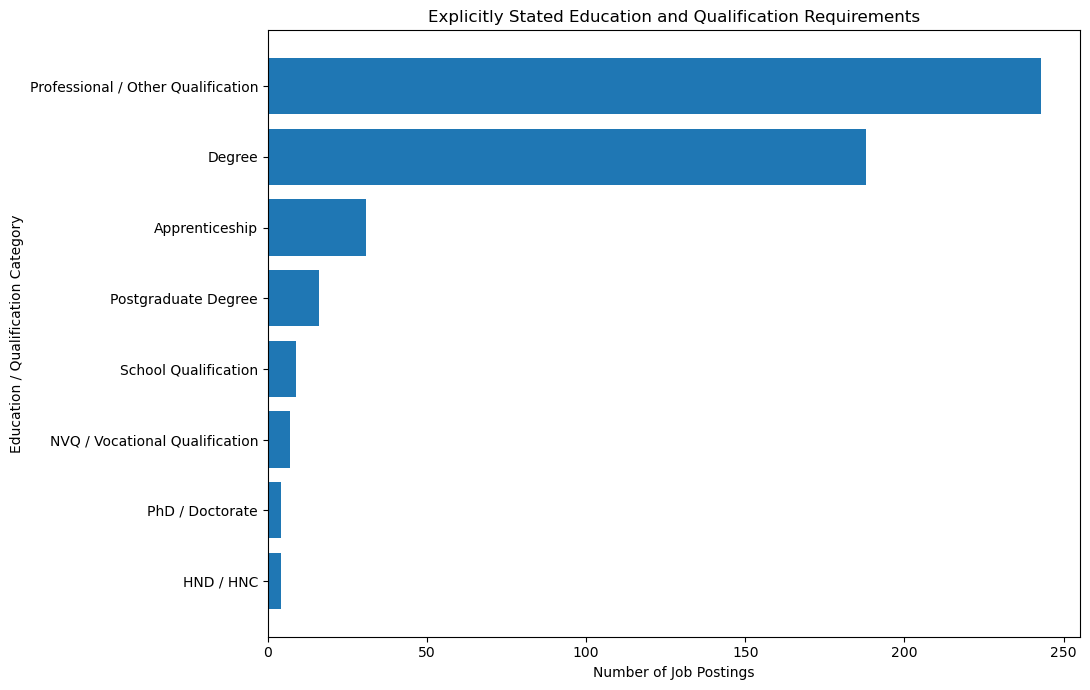

In [73]:
# ============================================================
# STEP 44 — EDUCATION REQUIREMENTS VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = education_visual_summary.sort_values(
    "job_count",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_df["education_category"],
    plot_df["job_count"]
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Education / Qualification Category")
plt.title(
    "Explicitly Stated Education and Qualification Requirements"
)

plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# STEP 45 — EDUCATION REQUIREMENTS BY INDUSTRY
# ============================================================

education_industry = df[
    df["education_category"] != "Not Explicitly Stated"
].copy()

education_industry_summary = (
    education_industry
    .groupby(["industry_refined", "education_category"])
    .size()
    .reset_index(name="job_count")
)

industry_education_totals = (
    education_industry
    .groupby("industry_refined")
    .size()
    .reset_index(name="education_records")
)

education_industry_summary = education_industry_summary.merge(
    industry_education_totals,
    on="industry_refined",
    how="left"
)

education_industry_summary["percentage"] = (
    education_industry_summary["job_count"]
    / education_industry_summary["education_records"]
    * 100
)

education_industry_summary = education_industry_summary.sort_values(
    ["industry_refined", "job_count"],
    ascending=[True, False]
).reset_index(drop=True)

print("=" * 60)
print("EDUCATION REQUIREMENTS BY INDUSTRY")
print("=" * 60)

print("Industries represented:",
      education_industry_summary["industry_refined"].nunique())

print("Education-industry records:",
      len(education_industry_summary))

display(education_industry_summary)

EDUCATION REQUIREMENTS BY INDUSTRY
Industries represented: 17
Education-industry records: 66


,industry_refined,education_category,job_count,education_records,percentage
0,Automotive,Not Specified,250,255,98.039216
1,Automotive,Other Specified,5,255,1.960784
2,Construction,Not Specified,1342,1369,98.027757
3,Construction,Other Specified,18,1369,1.314828
4,Construction,Apprenticeship,8,1369,0.584368
...,...,...,...,...,...
61,Real Estate,Other Specified,3,42,7.142857
62,Retail,Not Specified,192,192,100.000000
63,Transport and Logistics,Not Specified,946,948,99.789030
64,Transport and Logistics,NVQ,1,948,0.105485


In [75]:
# ============================================================
# STEP 45A — CHECK EDUCATION CATEGORY VALUES
# ============================================================

print("Unique education categories:")
print()

for value in sorted(df["education_category"].dropna().unique()):
    print(repr(value))

Unique education categories:

'A Level'
'Apprenticeship'
"Bachelor's Degree"
'Diploma'
'GCSE'
'HNC / HND'
"Master's Degree"
'NVQ'
'Not Specified'
'Other Specified'
'PhD / Doctorate'
'Teaching Qualification'


In [76]:
# ============================================================
# STEP 45B — CORRECTED EDUCATION REQUIREMENTS BY INDUSTRY
# ============================================================

education_industry = df[
    df["education_category"].notna()
    & (df["education_category"] != "Not Specified")
].copy()

education_industry_summary = (
    education_industry
    .groupby(["industry_refined", "education_category"])
    .size()
    .reset_index(name="job_count")
)

industry_education_totals = (
    education_industry
    .groupby("industry_refined")
    .size()
    .reset_index(name="education_records")
)

education_industry_summary = education_industry_summary.merge(
    industry_education_totals,
    on="industry_refined",
    how="left"
)

education_industry_summary["percentage"] = (
    education_industry_summary["job_count"]
    / education_industry_summary["education_records"]
    * 100
)

education_industry_summary = education_industry_summary.sort_values(
    ["industry_refined", "job_count"],
    ascending=[True, False]
).reset_index(drop=True)

print("=" * 60)
print("CORRECTED EDUCATION REQUIREMENTS BY INDUSTRY")
print("=" * 60)

print(
    "Industries represented:",
    education_industry_summary["industry_refined"].nunique()
)

print(
    "Explicit education-industry records:",
    len(education_industry)
)

print(
    "Education category combinations:",
    len(education_industry_summary)
)

display(education_industry_summary)

CORRECTED EDUCATION REQUIREMENTS BY INDUSTRY
Industries represented: 16
Explicit education-industry records: 1293
Education category combinations: 49


,industry_refined,education_category,job_count,education_records,percentage
0,Automotive,Other Specified,5,5,100.000000
1,Construction,Other Specified,18,27,66.666667
2,Construction,Apprenticeship,8,27,29.629630
3,Construction,NVQ,1,27,3.703704
4,Education,Other Specified,426,465,91.612903
5,Education,Teaching Qualification,21,465,4.516129
6,Education,Bachelor's Degree,12,465,2.580645
7,Education,GCSE,5,465,1.075269
8,Education,Apprenticeship,1,465,0.215054
9,Engineering,Other Specified,81,102,79.411765


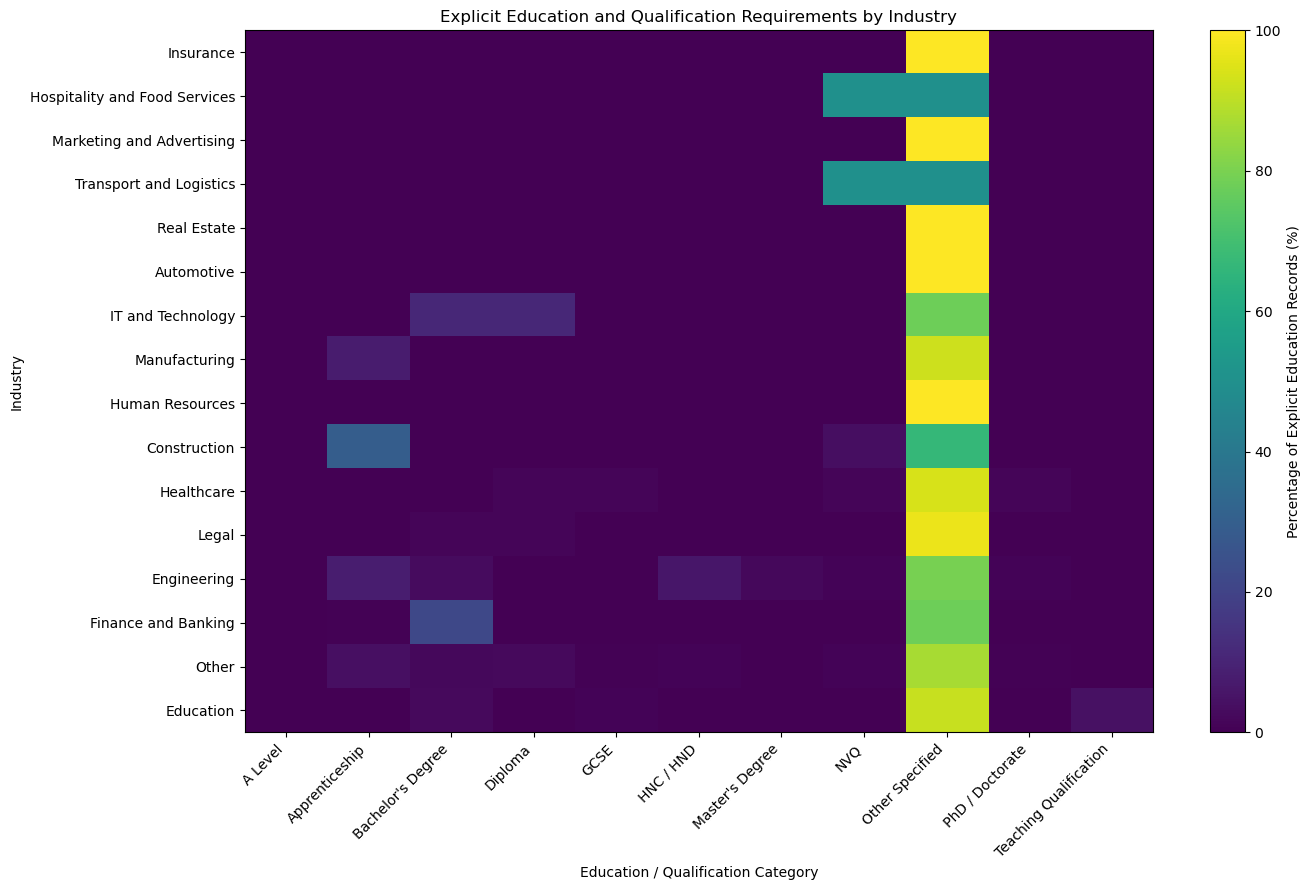

In [77]:
# ============================================================
# STEP 46 — EDUCATION REQUIREMENTS BY INDUSTRY HEATMAP
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

education_heatmap = education_industry_summary.pivot_table(
    index="industry_refined",
    columns="education_category",
    values="percentage",
    aggfunc="sum",
    fill_value=0
)

# Order industries by total explicit education records
industry_order = (
    education_industry
    .groupby("industry_refined")
    .size()
    .sort_values(ascending=True)
    .index
)

education_heatmap = education_heatmap.reindex(industry_order)

plt.figure(figsize=(14, 9))

plt.imshow(
    education_heatmap,
    aspect="auto"
)

plt.colorbar(
    label="Percentage of Explicit Education Records (%)"
)

plt.xticks(
    range(len(education_heatmap.columns)),
    education_heatmap.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(education_heatmap.index)),
    education_heatmap.index
)

plt.xlabel("Education / Qualification Category")
plt.ylabel("Industry")
plt.title(
    "Explicit Education and Qualification Requirements by Industry"
)

plt.tight_layout()
plt.show()

In [78]:
# ============================================================
# STEP 47 — FINAL INDUSTRY PROFILE RANKING
# ============================================================

final_industry_profiles = integrated_industry_profile.copy()

# Rank industries by observed job demand
final_industry_profiles["demand_rank"] = (
    final_industry_profiles["job_count"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Rank industries by median reported salary
final_industry_profiles["salary_rank"] = (
    final_industry_profiles["median_salary"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Rank industries by numeric experience evidence
final_industry_profiles["experience_evidence_rank"] = (
    final_industry_profiles["numeric_experience_percentage"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Rank industries by integrated skill pressure
final_industry_profiles["skill_pressure_rank"] = (
    final_industry_profiles["mean_combined_pressure"]
    .rank(method="min", ascending=False, na_option="bottom")
    .astype(int)
)

# Display the final analytical profile
final_industry_profiles = final_industry_profiles.sort_values(
    "demand_rank"
).reset_index(drop=True)

print("=" * 60)
print("FINAL INDUSTRY PROFILE RANKING")
print("=" * 60)

print(
    "Industries analysed:",
    len(final_industry_profiles)
)

display(final_industry_profiles)

FINAL INDUSTRY PROFILE RANKING
Industries analysed: 17


,industry_refined,job_count,demand_percentage,median_salary,adjusted_salary_coverage,numeric_experience_records,numeric_experience_percentage,median_experience_years,technical_priority_skills,soft_priority_skills,mean_combined_pressure,demand_rank,salary_rank,experience_evidence_rank,skill_pressure_rank
0,Other,8496,44.233873,37467.710,74.658663,981,11.546610,2.0,NaN,NaN,NaN,1,10,7,15
1,Engineering,2583,13.448222,46134.415,79.442509,145,5.613628,2.0,5.0,0.0,0.360730,2,2,14,4
2,Construction,1369,7.127610,45548.780,88.531775,44,3.214025,2.0,5.0,1.0,0.246288,3,4,16,13
3,Manufacturing,1277,6.648618,37500.000,43.304620,147,11.511355,2.0,0.0,5.0,0.225540,4,9,8,14
4,Finance and Banking,1117,5.815588,47500.000,82.542525,170,15.219338,2.0,5.0,1.0,0.270316,5,1,3,12
5,Education,1012,5.268912,38921.740,91.007905,46,4.545455,2.0,0.0,5.0,0.325816,6,8,15,7
6,Transport and Logistics,948,4.935701,35000.000,49.894515,118,12.447257,2.0,1.0,2.0,0.398225,7,13,5,3
7,IT and Technology,644,3.352944,44393.590,74.223602,19,2.950311,2.0,5.0,0.0,0.289609,8,6,17,10
8,Hospitality and Food Services,330,1.718124,33280.000,85.151515,39,11.818182,2.0,0.0,4.0,0.314146,9,15,6,8
9,Healthcare,263,1.369292,35000.000,86.311787,29,11.026616,2.0,0.0,5.0,0.352839,10,13,10,5


In [79]:
# ============================================================
# STEP 47A — CHECK REAL ESTATE INTEGRATED PROFILE
# ============================================================

print("Real Estate in integrated_industry_profile:")
display(
    integrated_industry_profile[
        integrated_industry_profile["industry_refined"] == "Real Estate"
    ]
)

print("\nReal Estate in soft_skill_priority:")
display(
    soft_skill_priority[
        soft_skill_priority["industry_refined"] == "Real Estate"
    ]
)

Real Estate in integrated_industry_profile:


,industry_refined,job_count,demand_percentage,median_salary,adjusted_salary_coverage,numeric_experience_records,numeric_experience_percentage,median_experience_years,technical_priority_skills,soft_priority_skills,mean_combined_pressure
16,Real Estate,42,0.21867,42500.0,88.095238,6,14.285714,1.5,0.0,2.0,0.455753



Real Estate in soft_skill_priority:


,industry_refined,soft_skill,job_count,industry_job_count,demand_percentage,overall_job_count,overall_demand_percentage,relative_demand_ratio,demand_score,specialisation_score,soft_skill_specialisation_score,specialisation_rank,observation_count,median_experience_years,experience_evidence,experience_score,skill_pressure_score,industry_skill_rank
27,Real Estate,Problem Solving,12,42,28.571429,2184,11.370854,2.512690,0.554113,0.034406,0.320245,9.0,499.0,2.0,Available,1.0,0.456196,1.0
28,Real Estate,Communication,12,42,28.571429,2352,12.245535,2.333212,0.554113,0.031948,0.319139,10.0,452.0,2.0,Available,1.0,0.455311,2.0


In [80]:
# ============================================================
# STEP 47 — FINAL INDUSTRY PROFILE RANKING
# ============================================================

final_industry_profiles = integrated_industry_profile.copy()

# ------------------------------------------------------------
# Rank by observed job demand
# ------------------------------------------------------------
final_industry_profiles["demand_rank"] = (
    final_industry_profiles["job_count"]
    .rank(method="min", ascending=False)
)

# ------------------------------------------------------------
# Rank by median reported salary
# ------------------------------------------------------------
final_industry_profiles["salary_rank"] = (
    final_industry_profiles["median_salary"]
    .rank(method="min", ascending=False)
)

# ------------------------------------------------------------
# Rank by numeric experience evidence
# ------------------------------------------------------------
final_industry_profiles["experience_evidence_rank"] = (
    final_industry_profiles["numeric_experience_percentage"]
    .rank(method="min", ascending=False)
)

# ------------------------------------------------------------
# Rank by integrated skill pressure
# ------------------------------------------------------------
final_industry_profiles["skill_pressure_rank"] = (
    final_industry_profiles["mean_combined_pressure"]
    .rank(method="min", ascending=False, na_option="bottom")
)

# Convert ranks to integers
final_industry_profiles["demand_rank"] = (
    final_industry_profiles["demand_rank"].astype(int)
)

final_industry_profiles["salary_rank"] = (
    final_industry_profiles["salary_rank"].astype(int)
)

final_industry_profiles["experience_evidence_rank"] = (
    final_industry_profiles["experience_evidence_rank"].astype(int)
)

final_industry_profiles["skill_pressure_rank"] = (
    final_industry_profiles["skill_pressure_rank"].astype(int)
)

# ------------------------------------------------------------
# Sort by observed job demand
# ------------------------------------------------------------
final_industry_profiles = (
    final_industry_profiles
    .sort_values("demand_rank")
    .reset_index(drop=True)
)

print("=" * 60)
print("FINAL INDUSTRY PROFILE RANKING")
print("=" * 60)

print(
    "Industries analysed:",
    len(final_industry_profiles)
)

display(final_industry_profiles)

FINAL INDUSTRY PROFILE RANKING
Industries analysed: 17


,industry_refined,job_count,demand_percentage,median_salary,adjusted_salary_coverage,numeric_experience_records,numeric_experience_percentage,median_experience_years,technical_priority_skills,soft_priority_skills,mean_combined_pressure,demand_rank,salary_rank,experience_evidence_rank,skill_pressure_rank
0,Other,8496,44.233873,37467.710,74.658663,981,11.546610,2.0,NaN,NaN,NaN,1,10,7,15
1,Engineering,2583,13.448222,46134.415,79.442509,145,5.613628,2.0,5.0,0.0,0.360730,2,2,14,4
2,Construction,1369,7.127610,45548.780,88.531775,44,3.214025,2.0,5.0,1.0,0.246288,3,4,16,13
3,Manufacturing,1277,6.648618,37500.000,43.304620,147,11.511355,2.0,0.0,5.0,0.225540,4,9,8,14
4,Finance and Banking,1117,5.815588,47500.000,82.542525,170,15.219338,2.0,5.0,1.0,0.270316,5,1,3,12
5,Education,1012,5.268912,38921.740,91.007905,46,4.545455,2.0,0.0,5.0,0.325816,6,8,15,7
6,Transport and Logistics,948,4.935701,35000.000,49.894515,118,12.447257,2.0,1.0,2.0,0.398225,7,13,5,3
7,IT and Technology,644,3.352944,44393.590,74.223602,19,2.950311,2.0,5.0,0.0,0.289609,8,6,17,10
8,Hospitality and Food Services,330,1.718124,33280.000,85.151515,39,11.818182,2.0,0.0,4.0,0.314146,9,15,6,8
9,Healthcare,263,1.369292,35000.000,86.311787,29,11.026616,2.0,0.0,5.0,0.352839,10,13,10,5


In [81]:
# ============================================================
# STEP 48 — FINAL INDUSTRY INTELLIGENCE SHORTLIST
# ============================================================

# Exclude the heterogeneous "Other" category
final_shortlist = final_industry_profiles[
    final_industry_profiles["industry_refined"] != "Other"
].copy()

# Calculate an overall analytical rank
# Lower average rank = stronger overall position
final_shortlist["overall_rank_score"] = (
    final_shortlist["demand_rank"]
    + final_shortlist["salary_rank"]
    + final_shortlist["experience_evidence_rank"]
    + final_shortlist["skill_pressure_rank"]
) / 4

final_shortlist = final_shortlist.sort_values(
    "overall_rank_score"
).reset_index(drop=True)

print("=" * 60)
print("FINAL INDUSTRY INTELLIGENCE SHORTLIST")
print("=" * 60)

print(
    "Industries included:",
    len(final_shortlist)
)

display(
    final_shortlist[
        [
            "industry_refined",
            "job_count",
            "demand_percentage",
            "median_salary",
            "numeric_experience_percentage",
            "technical_priority_skills",
            "soft_priority_skills",
            "mean_combined_pressure",
            "overall_rank_score"
        ]
    ]
)

FINAL INDUSTRY INTELLIGENCE SHORTLIST
Industries included: 16


,industry_refined,job_count,demand_percentage,median_salary,numeric_experience_percentage,technical_priority_skills,soft_priority_skills,mean_combined_pressure,overall_rank_score
0,Finance and Banking,1117,5.815588,47500.000,15.219338,5.0,1.0,0.270316,5.25
1,Engineering,2583,13.448222,46134.415,5.613628,5.0,0.0,0.360730,5.50
2,Transport and Logistics,948,4.935701,35000.000,12.447257,1.0,2.0,0.398225,7.00
3,Real Estate,42,0.218670,42500.000,14.285714,0.0,2.0,0.455753,7.50
4,Retail,192,0.999636,32500.000,17.187500,0.0,5.0,0.525542,8.00
5,Manufacturing,1277,6.648618,37500.000,11.511355,0.0,5.0,0.225540,8.75
6,Legal,240,1.249544,46064.625,11.250000,0.0,1.0,0.285134,8.75
7,Construction,1369,7.127610,45548.780,3.214025,5.0,1.0,0.246288,9.00
8,Education,1012,5.268912,38921.740,4.545455,0.0,5.0,0.325816,9.00
9,Hospitality and Food Services,330,1.718124,33280.000,11.818182,0.0,4.0,0.314146,9.50


In [82]:
# ============================================================
# STEP 41 — INDUSTRY TECHNICAL SKILL PRESSURE SUMMARY
# ============================================================

# Find the existing technical-skill dataframe automatically
technical_df = None

for name, obj in globals().items():
    if hasattr(obj, "columns"):
        required_columns = {
            "industry_refined",
            "technical_skill",
            "skill_pressure_score"
        }

        if required_columns.issubset(set(obj.columns)):
            technical_df = obj
            print("Using existing dataframe:", name)
            break

if technical_df is None:
    raise ValueError(
        "Technical skill pressure dataframe was not found. "
        "We need to recreate the technical priority table."
    )

technical_pressure_summary = (
    technical_df
    .groupby("industry_refined")
    .agg(
        technical_priority_count=("technical_skill", "count"),
        mean_technical_pressure=("skill_pressure_score", "mean"),
        max_technical_pressure=("skill_pressure_score", "max")
    )
    .reset_index()
)

technical_pressure_summary = technical_pressure_summary.sort_values(
    "mean_technical_pressure",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("INDUSTRY TECHNICAL SKILL PRESSURE SUMMARY")
print("=" * 60)

display(technical_pressure_summary)

Using existing dataframe: skill_pressure
INDUSTRY TECHNICAL SKILL PRESSURE SUMMARY


,industry_refined,technical_priority_count,mean_technical_pressure,max_technical_pressure
0,Transport and Logistics,1,0.552034,0.552034
1,Finance and Banking,8,0.236687,0.679985
2,IT and Technology,13,0.230764,0.330420
3,Construction,10,0.194719,0.655133
4,Engineering,14,0.183304,0.708272


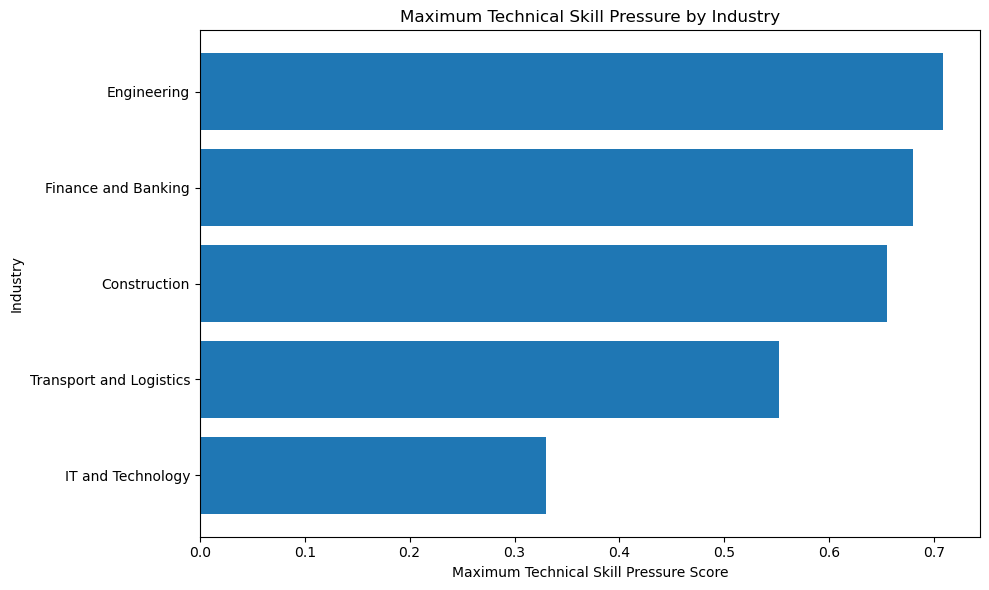

In [83]:
# ============================================================
# STEP 42 — INDUSTRY TECHNICAL SKILL PRESSURE VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = technical_pressure_summary.sort_values(
    "max_technical_pressure",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["industry_refined"],
    plot_df["max_technical_pressure"]
)

plt.xlabel("Maximum Technical Skill Pressure Score")
plt.ylabel("Industry")
plt.title("Maximum Technical Skill Pressure by Industry")

plt.tight_layout()
plt.show()

In [84]:
# ============================================================
# STEP 43 — INDUSTRY SOFT SKILL PRESSURE SUMMARY
# ============================================================

soft_df = None

for name, obj in globals().items():
    if hasattr(obj, "columns"):
        required_columns = {
            "industry_refined",
            "soft_skill",
            "skill_pressure_score"
        }

        if required_columns.issubset(set(obj.columns)):
            soft_df = obj
            print("Using existing dataframe:", name)
            break

if soft_df is None:
    raise ValueError(
        "Soft skill pressure dataframe was not found."
    )

soft_pressure_summary = (
    soft_df
    .groupby("industry_refined")
    .agg(
        soft_priority_count=("soft_skill", "count"),
        mean_soft_pressure=("skill_pressure_score", "mean"),
        max_soft_pressure=("skill_pressure_score", "max")
    )
    .reset_index()
)

soft_pressure_summary = soft_pressure_summary.sort_values(
    "mean_soft_pressure",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("INDUSTRY SOFT SKILL PRESSURE SUMMARY")
print("=" * 60)

display(soft_pressure_summary)

Using existing dataframe: soft_experience_adjusted
INDUSTRY SOFT SKILL PRESSURE SUMMARY


,industry_refined,soft_priority_count,mean_soft_pressure,max_soft_pressure
0,Real Estate,2,0.455753,0.456196
1,Retail,8,0.453206,0.699247
2,Human Resources,4,0.351097,0.469617
3,Healthcare,6,0.327834,0.465019
4,Hospitality and Food Services,4,0.314146,0.400132
5,Automotive,1,0.295430,0.295430
6,Legal,1,0.285134,0.285134
7,Transport and Logistics,2,0.244416,0.250579
8,Manufacturing,5,0.225540,0.253010
9,Finance and Banking,1,0.223203,0.223203


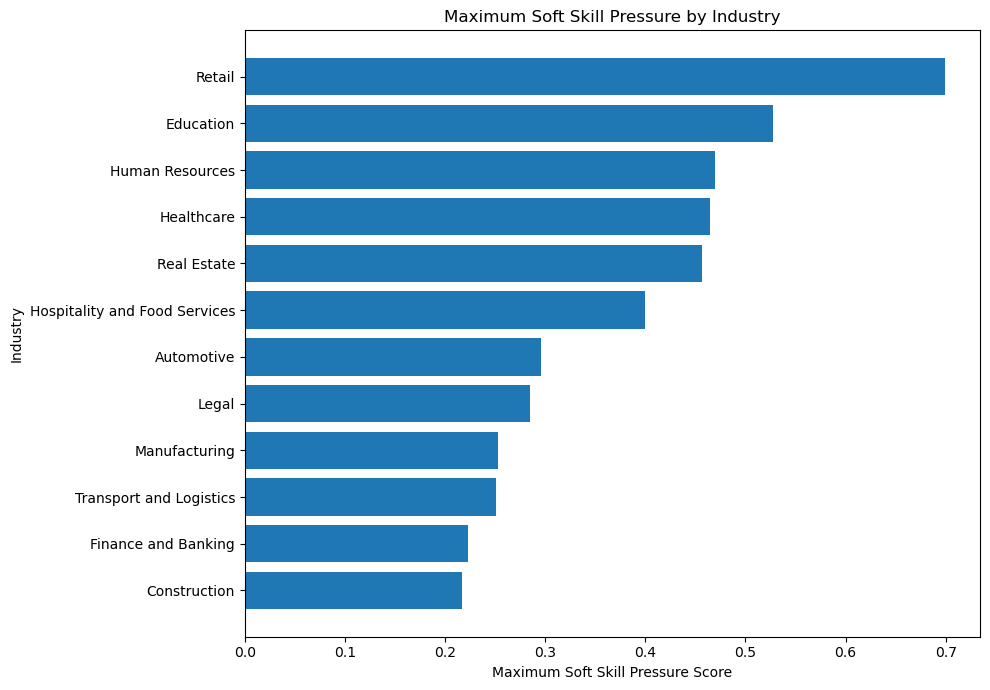

In [85]:
# ============================================================
# STEP 44 — INDUSTRY SOFT SKILL PRESSURE VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

plot_df = soft_pressure_summary.sort_values(
    "max_soft_pressure",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["industry_refined"],
    plot_df["max_soft_pressure"]
)

plt.xlabel("Maximum Soft Skill Pressure Score")
plt.ylabel("Industry")
plt.title("Maximum Soft Skill Pressure by Industry")

plt.tight_layout()
plt.show()

In [86]:
# ============================================================
# STEP 45 — COMBINED TECHNICAL + SOFT SKILL INTELLIGENCE
# ============================================================

combined_skill_pressure = pd.merge(
    technical_pressure_summary[
        [
            "industry_refined",
            "technical_priority_count",
            "mean_technical_pressure",
            "max_technical_pressure"
        ]
    ],
    soft_pressure_summary[
        [
            "industry_refined",
            "soft_priority_count",
            "mean_soft_pressure",
            "max_soft_pressure"
        ]
    ],
    on="industry_refined",
    how="outer"
)

# Calculate combined pressure using available skill evidence
combined_skill_pressure["combined_skill_pressure"] = (
    combined_skill_pressure[
        ["mean_technical_pressure", "mean_soft_pressure"]
    ].mean(axis=1, skipna=True)
)

combined_skill_pressure = combined_skill_pressure.sort_values(
    "combined_skill_pressure",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("COMBINED TECHNICAL + SOFT SKILL INTELLIGENCE")
print("=" * 60)

display(combined_skill_pressure)

COMBINED TECHNICAL + SOFT SKILL INTELLIGENCE


,industry_refined,technical_priority_count,mean_technical_pressure,max_technical_pressure,soft_priority_count,mean_soft_pressure,max_soft_pressure,combined_skill_pressure
0,Real Estate,NaN,NaN,NaN,2.0,0.455753,0.456196,0.455753
1,Retail,NaN,NaN,NaN,8.0,0.453206,0.699247,0.453206
2,Transport and Logistics,1.0,0.552034,0.552034,2.0,0.244416,0.250579,0.398225
3,Human Resources,NaN,NaN,NaN,4.0,0.351097,0.469617,0.351097
4,Healthcare,NaN,NaN,NaN,6.0,0.327834,0.465019,0.327834
5,Hospitality and Food Services,NaN,NaN,NaN,4.0,0.314146,0.400132,0.314146
6,Automotive,NaN,NaN,NaN,1.0,0.295430,0.295430,0.295430
7,Legal,NaN,NaN,NaN,1.0,0.285134,0.285134,0.285134
8,IT and Technology,13.0,0.230764,0.330420,NaN,NaN,NaN,0.230764
9,Finance and Banking,8.0,0.236687,0.679985,1.0,0.223203,0.223203,0.229945


In [87]:
# ============================================================
# STEP 46 — COMBINED SKILL EVIDENCE COVERAGE
# ============================================================

combined_skill_pressure["technical_evidence"] = (
    combined_skill_pressure["technical_priority_count"].notna()
)

combined_skill_pressure["soft_evidence"] = (
    combined_skill_pressure["soft_priority_count"].notna()
)

combined_skill_pressure["skill_domain_count"] = (
    combined_skill_pressure[
        ["technical_evidence", "soft_evidence"]
    ].sum(axis=1)
)

combined_skill_pressure["skill_evidence_coverage"] = (
    combined_skill_pressure["skill_domain_count"] / 2 * 100
)

combined_skill_pressure = combined_skill_pressure.sort_values(
    ["skill_evidence_coverage", "combined_skill_pressure"],
    ascending=[False, False]
).reset_index(drop=True)

print("=" * 60)
print("COMBINED SKILL EVIDENCE COVERAGE")
print("=" * 60)

display(
    combined_skill_pressure[
        [
            "industry_refined",
            "technical_priority_count",
            "soft_priority_count",
            "skill_domain_count",
            "skill_evidence_coverage",
            "combined_skill_pressure"
        ]
    ]
)

COMBINED SKILL EVIDENCE COVERAGE


,industry_refined,technical_priority_count,soft_priority_count,skill_domain_count,skill_evidence_coverage,combined_skill_pressure
0,Transport and Logistics,1.0,2.0,2,100.0,0.398225
1,Finance and Banking,8.0,1.0,2,100.0,0.229945
2,Construction,10.0,1.0,2,100.0,0.205638
3,Real Estate,NaN,2.0,1,50.0,0.455753
4,Retail,NaN,8.0,1,50.0,0.453206
5,Human Resources,NaN,4.0,1,50.0,0.351097
6,Healthcare,NaN,6.0,1,50.0,0.327834
7,Hospitality and Food Services,NaN,4.0,1,50.0,0.314146
8,Automotive,NaN,1.0,1,50.0,0.295430
9,Legal,NaN,1.0,1,50.0,0.285134


In [88]:
# EXPORT — TECHNICAL SKILL PRESSURE SUMMARY FOR TABLEAU
from pathlib import Path

project_root = Path(r"C:\Users\Visakh H S\Labour_Market_Intelligence")
output_file = project_root / "data" / "processed" / "tableau_technical_skill_pressure.csv"

technical_pressure_summary.to_csv(
    output_file,
    index=False
)

print("Export successful:")
print(output_file)

Export successful:
C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\tableau_technical_skill_pressure.csv


In [89]:
from pathlib import Path

project_root = Path(r"C:\Users\Visakh H S\Labour_Market_Intelligence")

output_file = (
    project_root
    / "data"
    / "processed"
    / "tableau_soft_skill_pressure.csv"
)

soft_pressure_summary.to_csv(
    output_file,
    index=False
)

print("Export successful:")
print(output_file)

Export successful:
C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\tableau_soft_skill_pressure.csv


In [90]:
from pathlib import Path

project_root = Path(r"C:\Users\Visakh H S\Labour_Market_Intelligence")

output_file = (
    project_root
    / "data"
    / "processed"
    / "tableau_combined_skill_pressure.csv"
)

combined_skill_pressure.to_csv(
    output_file,
    index=False
)

print("Export successful:")
print(output_file)

Export successful:
C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\tableau_combined_skill_pressure.csv


In [91]:
from pathlib import Path

project_root = Path(r"C:\Users\Visakh H S\Labour_Market_Intelligence")

output_file = (
    project_root
    / "data"
    / "processed"
    / "tableau_integrated_industry_profile.csv"
)

integrated_industry_profile.to_csv(
    output_file,
    index=False
)

print("Export successful:")
print(output_file)

Export successful:
C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\tableau_integrated_industry_profile.csv
